# AI Technologies (Basic Course) · Notebook 08
## Topic 5. Neural-network detection, segmentation and tracking of objects in the video of UAVs and UGVs

| Lesson | Type, duration | Title |
|---|---|---|
| **5.1** | Lecture, 2 h | Object detection by YOLO neural networks: IoU, confidence, non-maximum suppression, mAP and the detection of small targets |
| **5.2** | Group class, 2 h | Segmentation of the traversable area for a ground robotic platform, tracking of objects (ByteTrack), the video-analysis pipeline and the requirements of real time |

Course: *AI Technologies (Basic Course)*, AIT-BC · Content module 2 · Kruty Heroes Military Institute of Telecommunications and Information Technology, Kyiv, 2026.

**How to work with this notebook**

1. Run the cells from top to bottom: *Runtime → Run all*, or `Shift+Enter` cell by cell. Section 0 is always run first; after a restart of the runtime it is run again.
2. Every block begins with a text cell: the purpose, the formulas, the parameters of the form, the expected result and the control question. The parameters are changed in the form of the cell, and the cell is run again.
3. The notebook runs on the processor of Colab in about 10–15 minutes; with a GPU (*Runtime → Change runtime type → T4 GPU*) the detection blocks are several times faster.
4. The results are saved in the course project on Google Drive (`outputs`, `models`, `project.json`), created in Notebook 02.

**Data.** Only real images and videos are used, with the annotation of the authors of the data sets:
- **DUT Anti-UAV** — 10 000 images of drones taken by ground cameras against the sky, buildings and trees (counter-UAV task), with boxes of the class UAV;
- **M3OT** — video of DJI Mavic 3T drones at 100–120 m over roads and crossroads with tracks of vehicles;
- **GOOSE** — front camera of a ground vehicle in unstructured terrain (field tracks, forest, a training area) with pixel labels of 64 classes.

The detector is **YOLO11** of the library Ultralytics, trained by its authors on the data set COCO (80 everyday classes). In this notebook it is used as it is; its training for a new class is the mini-project of Lesson 5.4 (Notebook 09).

**Contents**

- **0. Preparation** — 0.1 runtime, course library, YOLO and data sets · 0.2 course project
- **Lesson 5.1 (lecture)**
  - 5.1.1 The task of detection, drones in the images of a ground camera and the output grid of YOLO
  - 5.1.2 Intersection over union (IoU)
  - 5.1.3 Confidence of a detection and non-maximum suppression
  - 5.1.4 Precision, recall, AP and mAP
  - 5.1.5 Small targets: size of the input, slicing of the frame and the cost in time
- **Lesson 5.2 (group class)**
  - 5.2.1 Terrain classes and the traversable area of a ground robotic platform
  - 5.2.2 Segmentation network LR-ASPP MobileNetV3: transfer learning and quality
  - 5.2.3 Tracking of objects by detection: Kalman filter, association, ByteTrack
  - 5.2.4 Video-analysis pipeline and the requirements of real time
- **Summary**: self-check, data sources and licences

---
# 0. Preparation

### Block 0.1. Runtime, course library, YOLO and data sets

**Purpose.** To prepare the runtime: the libraries, the library **Ultralytics** (models YOLO; it is installed in the session if it is absent), the course library `aitbc` (version 2.7.0 adds the data set DUT Anti-UAV, the metrics of detection and tracking, slicing of frames, the tracker ByteTrack, the segmentation network and a viewing window `crop_view`) and the data sets of the lessons.

**Parameters.** `CACHE_ON_DRIVE` — keep the downloaded files on Google Drive (they remain after the end of the session); otherwise they are kept on the disk of the session.

**Output.** A table of versions, the computing device and the size of the cache. The weights of the YOLO models (5–20 MB) are downloaded from the repository of Ultralytics when they are first used.

*Licence note.* Ultralytics and the weights of YOLO11 are distributed under AGPL-3.0; they are installed from PyPI in the session and are not part of the course materials.

In [1]:
#@title 0.1 Runtime, course library, YOLO and data sets (run once) { display-mode: "form" }
CACHE_ON_DRIVE = False #@param {type:"boolean"}

import sys, os, platform, time, json, math, importlib, shutil, warnings, subprocess, collections
import numpy as np
import pandas as pd
import torch
import torchvision
import cv2
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_colwidth", 200)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
WORK_DIR = "/content" if IN_COLAB else os.getcwd()

try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    import ultralytics
from ultralytics import YOLO
from ultralytics import settings as yolo_settings
yolo_settings.update({"sync": False})

LIB_SOURCE = r'''"""
aitbc - course library of "AI Technologies (Basic Course)" (AIT-BC).

Kruty Heroes Military Institute of Telecommunications and Information Technology,
Kyiv, 2026.

All demonstrations of the course use REAL open data sets recorded by UAVs and
ground vehicles. Only the files that a block needs are downloaded: large archives
are read selectively with HTTP range requests, and every file is cached in
DATA_ROOT (a Google Drive folder keeps the cache between sessions).

Data sets
---------
HIT-UAV   2898 thermal (LWIR) images 640x512 and 5 thermal videos. DJI Matrice
          M210 V2 with a Zenmuse XT2 camera (25 mm lens, field of view 25 x 20 deg),
          flight altitude 60-130 m, camera angle 30-90 deg, day and night. Boxes of
          Person, Car, Bicycle, OtherVehicle, DontCare.
          Suo J. et al. Scientific Data 10, 227 (2023). Licence CC BY 4.0.
Kust4K    4024 pixel-aligned visible (RGB) and thermal (TIR) image pairs 640x512
          from a hexacopter over urban roads, day and night; pixel labels of 8 classes.
          Scientific Data 12, 1701 (2025). Licence CC BY 4.0.
VisDrone  RGB images of drones over cities (VisDrone2019-DET validation part,
          548 images) with boxes of pedestrians, vehicles and other objects.
          Zhu P. et al. IEEE TPAMI 44(11), 7380-7399 (2022).
GOOSE     camera images of a ground vehicle on roads, field tracks, in forests and on
          a training area, with pixel labels of 64 classes (validation part, 962 images).
          IEEE ICRA 2024. Licence CC BY-SA 4.0.
M3OT      synchronised visible and thermal image sequences of two DJI Mavic 3T drones
          (100-120 m, 10 fps, 640x512, day, dusk, night) with vehicle tracks.
          Nie Z. et al. Scientific Data 12, 1927 (2025). Licence CC BY 4.0.

TII-RATM  frames 640x480 (125 fps), IMU 500 Hz and motion capture of an FPV racing quadrotor
          flown by human pilots in an indoor arena with racing gates (wide-angle camera
          155 x 115 deg). Bosello M. et al. IEEE RA-L 9(4), 3799-3806 (2024). Licence CC BY 4.0.
MilVeh    9444 photographs of 24 types of military vehicles collected from web sites
          (Kricheli J. S. et al., arXiv:2407.15192, 2024; Hugging Face
          leibnitz-lab/military_vehicles, licence declared: MIT).
SULAND    33771 frames 1440x1920 of video sequences of a camera over grass, leaves and
          gravel with surrogates of the surface landmines PFM-1 and PMA-2 (Italy and USA);
          Vivoli E. et al. Remote Sensing 16(4), 677 (2024); refined annotation SULAND_v2,
          Lekhak S. et al., arXiv:2607.28996 (2026). Licence CC BY 4.0.

DUT       10000 visible images of drones taken from the ground with boxes of the class UAV and 20
          tracking videos of a single drone. Zhao J. et al., IEEE Trans. Intelligent Transportation
          Systems (2022), arXiv:2205.10851. Licence Apache-2.0.
Units: metres, seconds, degrees. Images are NumPy arrays H x W (grey) or H x W x 3 (RGB).
"""

__version__ = "2.7.0"

import csv
import io
import json
import math
import os
import struct
import time
import urllib.error
import urllib.request
import zlib
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import cv2

DATA_ROOT = os.environ.get("AITBC_DATA") or (
    "/content/aitbc_data" if os.path.isdir("/content") else os.path.abspath("aitbc_data"))


def set_data_root(path):
    """Set the folder of the download cache (for example a folder on Google Drive)."""
    global DATA_ROOT
    DATA_ROOT = os.path.abspath(path)
    os.makedirs(DATA_ROOT, exist_ok=True)
    return DATA_ROOT


def _cache(*parts):
    p = os.path.join(DATA_ROOT, *parts)
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p


def cache_size():
    """Number of files and size of the download cache, MB."""
    n, s = 0, 0
    for dp, _, fn in os.walk(DATA_ROOT):
        for f in fn:
            n += 1
            s += os.path.getsize(os.path.join(dp, f))
    return n, s / 1e6


# =============================================================================
# 1. Downloading
# =============================================================================
class _HTTPSRedirect(urllib.request.HTTPRedirectHandler):
    """Follow redirects, keep the Range header and upgrade http:// targets to https://."""

    def redirect_request(self, req, fp, code, msg, headers, newurl):
        if newurl.startswith("http://"):
            newurl = "https://" + newurl[len("http://"):]
        new = super().redirect_request(req, fp, code, msg, headers, newurl)
        if new is not None and req.has_header("Range"):
            new.add_header("Range", req.get_header("Range"))
        return new


_OPENER = urllib.request.build_opener(_HTTPSRedirect)
_OPENER.addheaders = [("User-Agent", "aitbc-course/2.0")]


def _urlopen(url, headers=None, timeout=60, retries=4):
    """Open url with retries; a new Request object is built for every attempt."""
    err = None
    for k in range(retries):
        try:
            return _OPENER.open(urllib.request.Request(url, headers=dict(headers or {})), timeout=timeout)
        except urllib.error.HTTPError as e:
            if e.code in (400, 401, 403, 404, 416):
                raise
            err = e
        except Exception as e:                      # network error: retry after a pause
            err = e
        time.sleep(1.5 * (k + 1))
    raise err


def _retry(transfer, retries=5):
    """Run a complete transfer (request and reading of the whole body) with retries: a broken connection,
    a read timeout or an incomplete body repeats the transfer after a pause; client errors are not repeated."""
    err = None
    for k in range(retries):
        try:
            return transfer()
        except urllib.error.HTTPError as e:
            if e.code in (400, 401, 403, 404, 416):
                raise
            err = e
        except Exception as e:                      # timeout, reset connection, incomplete read
            err = e
        time.sleep(2.0 * (k + 1))
    raise err


def _read_url(url, headers=None, timeout=60, min_bytes=0, retries=5):
    """Whole body of a response (e.g. of a range request) with retries; a body shorter than min_bytes is
    an incomplete transfer and is repeated."""
    def transfer():
        with _OPENER.open(urllib.request.Request(url, headers=dict(headers or {})), timeout=timeout) as r:
            data = r.read()
        if len(data) < min_bytes:
            raise IOError(f"incomplete transfer: {len(data)} of at least {min_bytes} bytes")
        return data
    return _retry(transfer, retries)


def fetch(url, path, timeout=120, retries=5):
    """Download url to path with retries; nothing is done when the file is already in the cache.
    The file appears under its name only after a complete transfer."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".part"

    def transfer():
        with _OPENER.open(urllib.request.Request(url), timeout=timeout) as r, open(tmp, "wb") as fh:
            expected = int(r.headers.get("Content-Length") or 0)
            n = 0
            while True:
                b = r.read(1 << 20)
                if not b:
                    break
                fh.write(b)
                n += len(b)
        if expected and n < expected:
            raise IOError(f"incomplete download of {url}: {n} of {expected} bytes")
        os.replace(tmp, path)
        return path
    return _retry(transfer, retries)


def fetch_many(jobs, threads=8):
    """jobs: list of (url, path); parallel download, returns the list of paths."""
    with ThreadPoolExecutor(threads) as ex:
        return list(ex.map(lambda j: fetch(*j), jobs))


class _RangeFile(io.RawIOBase):
    """Seekable read-only file over HTTP range requests (reads the directory of a remote zip)."""

    def __init__(self, url, chunk=1 << 17, timeout=60):
        self.url, self.chunk, self.timeout = url, chunk, timeout
        r = _urlopen(url, {"Range": "bytes=0-0"}, timeout)
        cr = r.headers.get("Content-Range")
        r.read()
        if r.status != 206 or not cr:
            raise IOError(f"the server of {url} does not support range requests")
        self.size = int(cr.split("/")[-1])
        self.pos, self.buf_start, self.buf = 0, 0, b""

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else (self.pos + off if whence == 1 else self.size + off)
        return self.pos

    def read(self, n=-1):
        if n is None or n < 0:
            n = self.size - self.pos
        n = min(n, self.size - self.pos)
        if n <= 0:
            return b""
        if not (self.buf_start <= self.pos and self.pos + n <= self.buf_start + len(self.buf)):
            start = self.pos
            end = min(self.size, start + max(n, self.chunk)) - 1
            self.buf = _read_url(self.url, {"Range": f"bytes={start}-{end}"}, self.timeout, min_bytes=end - start + 1)
            self.buf_start = start
        off = self.pos - self.buf_start
        out = self.buf[off:off + n]
        self.pos += len(out)
        return out

    def readinto(self, b):
        d = self.read(len(b))
        b[:len(d)] = d
        return len(d)


class RemoteZip:
    """Selective reading of members of a large remote zip archive: only the central
    directory and the requested members are transferred; members are cached on disk."""

    def __init__(self, url, cache_name):
        import zipfile
        self.url, self.cache_name = url, cache_name
        idx_path = _cache("_index", cache_name + ".json")
        if os.path.exists(idx_path):
            with open(idx_path) as fh:
                self.index = json.load(fh)
        else:
            zf = zipfile.ZipFile(_RangeFile(url))
            self.index = {i.filename: (i.header_offset, i.compress_size, i.file_size, i.compress_type)
                          for i in zf.infolist() if not i.filename.endswith("/")}
            with open(idx_path, "w") as fh:
                json.dump(self.index, fh)

    def namelist(self):
        return list(self.index)

    def _fetch_member(self, name):
        path = _cache(self.cache_name, name)
        if os.path.exists(path):
            return path
        off, csize, usize, ctype = self.index[name]
        raw = _read_url(self.url, {"Range": f"bytes={off}-{off + 30 + 1024 + csize}"}, min_bytes=30 + csize)
        if raw[:4] != b"PK\x03\x04":
            raise IOError(f"bad local header of {name}")
        n, m = struct.unpack("<HH", raw[26:30])
        data = raw[30 + n + m: 30 + n + m + csize]
        if ctype == 8:
            data = zlib.decompressobj(-15).decompress(data)
        elif ctype != 0:
            raise IOError(f"unsupported compression {ctype} in {name}")
        if len(data) != usize:
            raise IOError(f"incomplete member {name}")
        with open(path + ".part", "wb") as fh:
            fh.write(data)
        os.replace(path + ".part", path)
        return path

    def get(self, names, threads=8):
        """Download members (a name or a list of names); returns local path(s)."""
        single = isinstance(names, str)
        names = [names] if single else list(names)
        with ThreadPoolExecutor(threads) as ex:
            paths = list(ex.map(self._fetch_member, names))
        return paths[0] if single else paths


def _rgb(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"cannot read {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# =============================================================================
# 2. Data sets
# =============================================================================
class HITUAV:
    """HIT-UAV: thermal images and videos of a DJI Matrice M210 V2 with a Zenmuse XT2.

    File name T_HHH_AA_W_NNNNN: T = 0 day / 1 night, HHH = flight altitude, m,
    AA = camera angle, deg (90 = vertical view), W = 0 sunny / 1 rainy.
    Images are 8-bit white-hot (warm = bright) after the automatic gain control
    of the camera: brightness is a relative, not a calibrated, temperature."""

    PALETTE = "white-hot"
    BASE = "https://raw.githubusercontent.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset/main/"
    CLASSES = ("Person", "Car", "Bicycle", "OtherVehicle", "DontCare")
    COLORS = {"Person": (0, 229, 255), "Car": (255, 235, 59), "Bicycle": (118, 255, 3),
              "OtherVehicle": (255, 152, 0), "DontCare": (190, 190, 190)}
    CAMERA = dict(model="DJI Zenmuse XT2, uncooled VOx microbolometer", width=640, height=512,
                  focal_mm=25.0, pixel_pitch_um=17.0, hfov_deg=25.0, vfov_deg=20.0, band_um="7.5-13.5")
    EXAMPLES = ('1_60_30_0_00047.jpg', '0_60_60_0_01734.jpg', '1_70_90_0_07776.jpg', '0_100_50_0_08162.jpg', '1_120_90_0_06161.jpg', '0_130_40_0_05603.jpg', '1_90_70_0_04990.jpg', '0_110_80_0_08518.jpg')
    VIDEOS = {"60m-30_1.mov": "60 m, camera angle 30 deg: people on a sports ground",
              "60m-40_3.mov": "60 m, 40 deg: cars on a parking lot",
              "70m-90_1.mov": "70 m, 90 deg (vertical view): people on a square",
              "120m-30_3.mov": "120 m, 30 deg: road along buildings",
              "130m-60_3.mov": "130 m, 60 deg: parking lot and roads"}

    def __init__(self, splits=("train", "val", "test")):
        import pandas as pd
        imgs, objs = [], []
        jobs = [(self.BASE + f"normal_json/annotations/{sp}.json", _cache("hituav", "annotations", sp + ".json"))
                for sp in splits]
        for sp, path in zip(splits, fetch_many(jobs, 3)):
            with open(path) as fh:
                d = json.load(fh)
            cat = {c["id"]: c["name"] for c in d["categories"]}
            id2f = {}
            for im in d["images"]:
                fn = im.get("filename") or im.get("file_name")
                id2f[im["id"]] = fn
                t, h, a, w = fn.split("_")[:4]
                imgs.append(dict(file=fn, split=sp, night=t == "1", altitude=int(h), angle=int(a), rainy=w == "1"))
            for an in d.get("annotation", d.get("annotations", [])):
                x, y, w, h = an["bbox"]
                objs.append(dict(ann_id=an["id"], file=id2f[an["image_id"]], cls=cat[an["category_id"]],
                                 x1=float(x), y1=float(y), x2=float(x + w), y2=float(y + h)))
        # oriented boxes [xc, yc, w, h, angle]: true width and length of rotated objects
        rjobs = [(self.BASE + f"rotate_json/annotations/{sp}.json", _cache("hituav", "annotations", "rot_" + sp + ".json"))
                 for sp in splits]
        rot = {}
        for path in fetch_many(rjobs, 3):
            with open(path) as fh:
                d = json.load(fh)
            for an in d.get("annotations", d.get("annotation", [])):
                b = an["bbox"]
                rot[an["id"]] = (min(b[2], b[3]), max(b[2], b[3]), b[4] if len(b) > 4 else 0.0)
        self.images = pd.DataFrame(imgs).sort_values("file").reset_index(drop=True)
        o = pd.DataFrame(objs)
        o["w"], o["h"] = o.x2 - o.x1, o.y2 - o.y1
        o["width_px"] = o.ann_id.map(lambda i: rot.get(i, (np.nan,) * 3)[0])     # oriented box: short side
        o["length_px"] = o.ann_id.map(lambda i: rot.get(i, (np.nan,) * 3)[1])    # oriented box: long side
        self.objects = o.merge(self.images[["file", "night", "altitude", "angle"]], on="file", how="left")
        self._split = dict(zip(self.images.file, self.images.split))
        self._groups = {f: g for f, g in self.objects.groupby("file")}
        counts = self.objects.pivot_table(index="file", columns="cls", values="x1", aggfunc="count", fill_value=0)
        self.images = self.images.merge(counts, left_on="file", right_index=True, how="left").fillna(0)

    def _url(self, f):
        return self.BASE + f"normal_json/{self._split[f]}/{f}"

    def path(self, file):
        return fetch(self._url(file), _cache("hituav", self._split[file], file))

    def prefetch(self, files, threads=8):
        return fetch_many([(self._url(f), _cache("hituav", self._split[f], f)) for f in files], threads)

    def load(self, file):
        """Thermal image (H x W uint8) and the list of annotated objects."""
        img = cv2.imread(self.path(file), cv2.IMREAD_GRAYSCALE)
        g = self._groups.get(file)
        objs = [] if g is None else [dict(cls=r.cls, box=[r.x1, r.y1, r.x2, r.y2]) for r in g.itertuples()]
        return img, objs

    def video(self, name):
        return fetch(self.BASE + "video_sample/" + name, _cache("hituav", "video", name))

    @staticmethod
    def video_geometry(name):
        """Flight altitude, m, and camera angle, deg, from a video name such as '60m-30_1.mov'."""
        alt, rest = name.split("m-")
        return int(alt), int(rest.split("_")[0])

    def gsd(self, altitude, angle=90):
        """Ground sampling distance at the image centre, m/px (formula of Lesson 1.1)."""
        rng = altitude / max(math.sin(math.radians(angle)), 1e-3)
        return 2 * rng * math.tan(math.radians(self.CAMERA["hfov_deg"]) / 2) / self.CAMERA["width"]


class Kust4K:
    """Kust4K: pixel-aligned RGB and thermal (TIR) pairs 640x512 of a hexacopter
    HET-3021C over urban roads, day (id ...D) and night (id ...N), with pixel labels.

    The thermal images are pseudo-colour (palette from purple = cold to yellow = warm);
    tir_gray is their luminance, a relative thermal brightness. The data set contains
    frames with SIMULATED failures (visible channel set to zero, thermal channel
    blurred) made by its authors; they are excluded from the curated lists below."""

    PALETTE = "pseudo-colour (purple = cold, yellow = warm)"
    URL = "https://ndownloader.figshare.com/files/{}"
    FILES = {"rgb": 55979147, "tir": 55979165, "seg": 55979159}
    CLASSES = ("unlabelled", "road", "building", "motorcycle", "car", "truck", "tree", "person", "traffic facilities")
    COLORS = np.array([(0, 0, 0), (150, 150, 150), (229, 57, 53), (255, 152, 0), (255, 235, 59),
                       (236, 64, 122), (46, 160, 67), (0, 229, 255), (30, 136, 229)], np.uint8)
    OBJECTS = (3, 4, 5, 7)
    CAMERA = dict(platform="hexacopter HET-3021C", tir_focal_mm=9.1, tir_pixel_um=12.0,
                  rgb="1920x1080, f = 8 mm, registered to the thermal image and resized to 640x512")
    DAY = ("00720D", "00719D", "00031D", "01944D", "00851D", "00580D", "00990D", "00355D", "02094D", "02293D")
    NIGHT = ("02566N", "02807N", "02921N", "03135N", "03685N", "03895N", "03780N", "04004N", "02867N", "02599N")

    def __init__(self):
        self._z = {}

    def _zip(self, key):
        if key not in self._z:
            self._z[key] = RemoteZip(self.URL.format(self.FILES[key]), "kust4k_" + key)
        return self._z[key]

    def prefetch(self, ids, threads=6):
        names = [i + ".png" for i in ids]
        with ThreadPoolExecutor(3) as ex:
            list(ex.map(lambda k: self._zip(k).get(names, threads), ("rgb", "tir", "seg")))

    def pair(self, fid):
        """dict(id, night, rgb, tir, tir_gray, labels) for a frame id such as '00720D'."""
        self.prefetch([fid])
        name = fid + ".png"
        rgb = _rgb(self._zip("rgb").get(name))
        tir = _rgb(self._zip("tir").get(name))
        lab = cv2.imread(self._zip("seg").get(name), cv2.IMREAD_UNCHANGED)
        return dict(id=fid, night=fid.endswith("N"), rgb=rgb, tir=tir,
                    tir_gray=cv2.cvtColor(tir, cv2.COLOR_RGB2GRAY), labels=lab)


class VisDrone:
    """VisDrone2019-DET validation part: RGB images of drones with object boxes.
    Annotation line: x, y, w, h, score, category, truncation, occlusion."""

    URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip"
    CLASSES = ("ignored region", "pedestrian", "people", "bicycle", "car", "van", "truck", "tricycle",
               "awning-tricycle", "bus", "motor", "others")
    COLORS = {"pedestrian": (0, 229, 255), "people": (0, 176, 255), "bicycle": (118, 255, 3), "car": (255, 235, 59),
              "van": (255, 193, 7), "truck": (255, 152, 0), "tricycle": (186, 104, 200),
              "awning-tricycle": (156, 39, 176), "bus": (244, 67, 54), "motor": (236, 64, 122)}

    CURATED = ('0000213_03920_d_0000243', '0000291_03801_d_0000887', '0000117_00112_d_0000087', '0000001_08414_d_0000013', '0000155_00401_d_0000001', '0000193_01705_d_0000112', '0000295_02400_d_0000033', '0000289_04601_d_0000834', '0000215_00000_d_0000256', '0000327_04001_d_0000731')

    def __init__(self):
        self.z = RemoteZip(self.URL, "visdrone_val")

    def names(self):
        return sorted(n.split("/")[-1][:-4] for n in self.z.namelist() if n.endswith(".jpg"))

    def _members(self, name):
        return [f"VisDrone2019-DET-val/images/{name}.jpg", f"VisDrone2019-DET-val/annotations/{name}.txt"]

    def prefetch(self, names, threads=8):
        self.z.get([m for n in names for m in self._members(n)], threads)

    def load(self, name):
        """RGB image and the list of objects (ignored regions and 'others' are skipped)."""
        pi, pa = self.z.get(self._members(name))
        objs = []
        with open(pa) as fh:
            for line in fh:
                v = line.strip().strip(",").split(",")
                if len(v) < 8:
                    continue
                x, y, w, h, _, c, trunc, occ = (int(float(s)) for s in v[:8])
                if c in (0, 11):
                    continue
                objs.append(dict(cls=self.CLASSES[c], box=[x, y, x + w, y + h], truncation=trunc, occlusion=occ))
        return _rgb(pi), objs


class M3OT:
    """M3OT: synchronised visible (RGB) and thermal (IR) image sequences of two DJI Mavic 3T
    drones flying at 100-120 m (10 frames per second, 640 x 512 px), day, dusk and night, with
    multi-object tracking annotation of vehicles (MOT format: frame, id, x, y, w, h, flag, class,
    confidence). The track identifiers are the same in the RGB and IR sequences of one drone.
    The two channels were aligned by the authors with an affine transform; a residual spatial
    offset of several pixels and a time offset of up to several frames remain (Lesson 1.4).

    The IR frames are 8-bit grey images in the BLACK-HOT palette (warm = dark). The data
    descriptor does not state the palette; it is established from the scene: in all nine
    sequences of drone 1 the road surface is darker than vegetation by day, at dusk and at night,
    while asphalt is, as a rule, the warmer surface (Lesson 1.3, task 1.3.4). Vehicles are
    bright, i.e. cooler than the road. to_white_hot() gives the white-hot convention of HIT-UAV."""

    PALETTE = "black-hot"
    URL = "https://ndownloader.figshare.com/files/52023875"
    CAMERA = dict(platform="DJI Mavic 3T", altitude_m="100-120", fps=10, width=640, height=512,
                  rgb="telephoto camera, f = 29.85 mm (35 mm equivalent 162 mm), frames registered to IR",
                  ir="uncooled thermal camera 640 x 512, f = 9.1 mm (35 mm equivalent 40 mm)")
    SEQUENCES = {"1-01": "day, suburban road", "1-02": "night, city crossroads", "1-03": "day, city road",
                 "1-04": "day, suburban highway", "1-05": "day, crossroads", "1-06": "dusk, highway",
                 "1-07": "day, crossroads", "1-08": "dusk, crossroads", "1-09": "day, city street with parked cars"}

    def __init__(self):
        self.z = RemoteZip(self.URL, "m3ot")
        self._seq = {}
        for n in self.z.namelist():
            parts = n.split("/")        # M3OT/<drone>/<rgb|ir>/<split>/<sequence>/img1/<frame>.PNG
            if len(parts) == 7 and parts[5] == "img1":
                self._seq.setdefault((parts[4].rstrip("T"), parts[2]), []).append(n)
        for k in self._seq:
            self._seq[k].sort()

    def sequences(self):
        return sorted({k[0] for k in self._seq})

    def n_frames(self, seq, channel="rgb"):
        return len(self._seq[(seq, channel)])

    def frame_names(self, seq, channel="rgb", start=0, count=None, step=1):
        names = self._seq[(seq, channel)]
        end = len(names) if count is None else min(len(names), start + count * step)
        return names[start:end:step]

    def prefetch(self, seq, channel="rgb", start=0, count=None, step=1, threads=8):
        return self.z.get(self.frame_names(seq, channel, start, count, step), threads)

    def frames(self, seq, channel="rgb", start=0, count=None, step=1):
        """List of RGB images (H x W x 3) of a sequence; IR frames are grey images in 3 equal channels."""
        return [_rgb(p) for p in self.prefetch(seq, channel, start, count, step)]

    def tracks(self, seq, channel="rgb"):
        """Annotation table: frame (from 1), id, x, y, w, h, cx, cy."""
        import pandas as pd
        names = self._seq[(seq, channel)]
        gt = names[0].rsplit("/img1/", 1)[0] + "/gt/gt.txt"
        g = pd.read_csv(self.z.get(gt), header=None, names=["frame", "id", "x", "y", "w", "h", "flag", "cls", "conf"])
        g["cx"], g["cy"] = g.x + g.w / 2, g.y + g.h / 2
        return g[["frame", "id", "x", "y", "w", "h", "cx", "cy"]]

    def objects(self, table, frame):
        """Objects of one frame in the format of draw_boxes."""
        t = table[table.frame == frame]
        return [dict(cls="vehicle", id=int(r.id), box=[r.x, r.y, r.x + r.w, r.y + r.h]) for r in t.itertuples()]


class GOOSE:
    """GOOSE: front camera of a ground vehicle (2048x1000) with pixel labels of 64 classes."""

    URL = "https://goose-dataset.de/storage/goose_2d_val.zip"
    TRAVERSABLE = ("asphalt", "cobble", "gravel", "soil", "low_grass", "moss", "leaves", "snow",
                   "road_marking", "pedestrian_crossing", "sidewalk", "bikeway")
    CONDITIONAL = ("high_grass", "crops", "debris", "tree_root")
    IGNORE = ("undefined", "sky", "ego_vehicle", "outlier")
    CURATED = (
        'labels/val/2022-07-22_flight/2022-07-22_flight__0078_1658494246011438339_labelids.png',
        'labels/val/2022-07-22_flight/2022-07-22_flight__0158_1658494465090456964_labelids.png',
        'labels/val/2022-08-30_siegertsbrunn_feldwege/2022-08-30_siegertsbrunn_feldwege__0528_1661860582736903436_labelids.png',
        'labels/val/2022-08-30_siegertsbrunn_feldwege/2022-08-30_siegertsbrunn_feldwege__0551_1661860697315889089_labelids.png',
        'labels/val/2022-09-21_garching_uebungsplatz_2/2022-09-21_garching_uebungsplatz_2__0002_1663755194931038715_labelids.png',
        'labels/val/2022-09-21_garching_uebungsplatz_2/2022-09-21_garching_uebungsplatz_2__0038_1663755353192423465_labelids.png',
        'labels/val/2023-03-03_garching_2/2023-03-03_garching_2__0114_1677850404544550420_labelids.png',
        'labels/val/2023-03-03_garching_2/2023-03-03_garching_2__0156_1677850669766430912_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0007_1670420722571435228_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0057_1670421449778652057_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0037_1670421230548919820_labelids.png',
        'labels/val/2023-05-15_neubiberg_rain/2023-05-15_neubiberg_rain__0650_1684157928693659670_labelids.png',
    )

    def __init__(self):
        self.z = RemoteZip(self.URL, "goose_val")
        self.names, self.colors = {}, {}
        with open(self.z.get("goose_label_mapping.csv"), newline="") as fh:
            for row in csv.DictReader(fh):
                k = int(row["label_key"])
                h = row["hex"].lstrip("#")
                self.names[k] = row["class_name"]
                self.colors[k] = tuple(int(h[i:i + 2], 16) for i in (0, 2, 4))
        self.lut = np.zeros((256, 3), np.uint8)
        for k, c in self.colors.items():
            self.lut[k] = c
        self.id_of = {v: k for k, v in self.names.items()}

    def frames(self):
        return sorted(n for n in self.z.namelist() if n.endswith("_labelids.png"))

    @staticmethod
    def _image_member(label_member):
        return label_member.replace("labels/", "images/").replace("_labelids.png", "_windshield_vis.png")

    def prefetch(self, members, threads=6):
        self.z.get([m for lm in members for m in (self._image_member(lm), lm)], threads)

    def load(self, label_member, scale=0.5):
        """RGB image and label map (both resized by `scale`)."""
        pi, pl = self.z.get([self._image_member(label_member), label_member])
        img, lab = _rgb(pi), cv2.imread(pl, cv2.IMREAD_UNCHANGED)
        if scale != 1:
            w, h = int(img.shape[1] * scale), int(img.shape[0] * scale)
            img = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
            lab = cv2.resize(lab, (w, h), interpolation=cv2.INTER_NEAREST)
        return img, lab

    def traversability(self, lab):
        """0 = ignored (sky, own vehicle), 1 = traversable, 2 = conditionally traversable, 3 = obstacle."""
        lut = np.full(256, 3, np.uint8)
        for group, v in ((self.TRAVERSABLE, 1), (self.CONDITIONAL, 2), (self.IGNORE, 0)):
            for n in group:
                if n in self.id_of:
                    lut[self.id_of[n]] = v
        return lut[lab]


# =============================================================================
# 3. Camera geometry
# =============================================================================
def gsd_nadir(altitude, hfov_deg, width_px):
    """Ground sampling distance of a vertical view, m/px: GSD = 2 H tan(alpha/2) / N."""
    return 2 * altitude * math.tan(math.radians(hfov_deg) / 2) / width_px


def hfov_from_sensor(focal_mm, pixel_um, width_px):
    """Horizontal field of view, deg, from the focal length and the pixel pitch."""
    return math.degrees(2 * math.atan(width_px * pixel_um * 1e-3 / 2 / focal_mm))


# =============================================================================
# 4. Degradations of the video signal (applied to real frames)
# =============================================================================
def fractal_noise(shape, rng, octaves=5, start=3, persistence=0.5):
    """Smooth random field in [0, 1] (sum of up-sampled random grids)."""
    h, w = shape
    out = np.zeros((h, w), np.float32)
    amp, m = 1.0, max(h, w)
    for o in range(octaves):
        n = start * (2 ** o)
        grid = rng.random((max(2, int(round(n * h / m)) + 1), max(2, int(round(n * w / m)) + 1)), dtype=np.float32)
        out += amp * cv2.resize(grid, (w, h), interpolation=cv2.INTER_CUBIC)
        amp *= persistence
    out -= out.min()
    return out / max(float(out.max()), 1e-6)


def _f(img):
    return img.astype(np.float32)


def _u8(x):
    return np.clip(x, 0, 255).astype(np.uint8)


def motion_blur(img, length=9.0, angle=0.0):
    """Linear motion blur: the point spread function is a line of `length` px at `angle` deg."""
    if length < 1.5:
        return img.copy()
    size = int(math.ceil(length)) | 1
    k = np.zeros((size * 4, size * 4), np.uint8)
    c = size * 2
    dx = math.cos(math.radians(angle)) * (length - 1) * 2
    dy = -math.sin(math.radians(angle)) * (length - 1) * 2
    cv2.line(k, (int(c - dx), int(c - dy)), (int(c + dx), int(c + dy)), 255, 4, cv2.LINE_AA)
    k = cv2.resize(k.astype(np.float32), (size, size), interpolation=cv2.INTER_AREA)
    return cv2.filter2D(img, -1, k / max(k.sum(), 1e-6), borderType=cv2.BORDER_REFLECT)


def defocus(img, sigma=1.5):
    return img.copy() if sigma <= 0 else cv2.GaussianBlur(img, (0, 0), sigma)


def add_noise(img, sigma=10.0, seed=None):
    rng = np.random.default_rng(seed)
    return _u8(_f(img) + rng.normal(0, sigma, img.shape))


def low_light(img, level=0.15, gain_max=8.0, seed=None):
    """Dark scene and automatic gain: light reduced by `level`, photon and read noise added."""
    if level >= 0.999:
        return img.copy()
    rng = np.random.default_rng(seed)
    lin = (_f(img) / 255.0) ** 2.2 * level
    full_well = 3000.0
    noisy = lin + rng.standard_normal(lin.shape).astype(np.float32) * np.sqrt(lin / full_well + (4.0 / full_well) ** 2)
    gain = float(np.clip(0.16 / max(float(lin.mean()), 1e-6), 1.0, gain_max))
    return _u8(np.clip(noisy * gain, 0, 1) ** (1 / 2.2) * 255)


def haze(img, density=0.4, airlight=200.0):
    """Uniform haze: I = J t + A (1 - t), transmission t = 1 - density."""
    t = 1.0 - float(np.clip(density, 0, 0.98))
    return _u8(_f(img) * t + airlight * (1 - t))


def smoke(img, density=0.5, seed=0, color=170.0, opacity=0.92):
    """Smoke: spatially variable veil."""
    if density <= 0:
        return img.copy()
    n = fractal_noise(img.shape[:2], np.random.default_rng(seed))
    m = np.clip((n - (1.0 - density)) * 3.0, 0, 1) * opacity
    if img.ndim == 3:
        m = m[..., None]
    return _u8(_f(img) * (1 - m) + color * m)


def jpeg(img, quality=30):
    """JPEG compression artefacts."""
    if quality >= 100:
        return img.copy()
    x = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    _, buf = cv2.imencode(".jpg", x, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    y = cv2.imdecode(buf, cv2.IMREAD_UNCHANGED)
    return y if img.ndim == 2 else cv2.cvtColor(y, cv2.COLOR_BGR2RGB)


def downscale(img, factor=0.5):
    """Loss of resolution: down-sample by `factor`, then up-sample back."""
    if factor >= 0.999:
        return img.copy()
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, int(w * factor)), max(1, int(h * factor))), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)


def rolling_shutter(img, amplitude=6.0, cycles=1.5, phase=0.0):
    """Rolling-shutter distortion: every row is shifted by a sinusoid of the row number."""
    if amplitude <= 0:
        return img.copy()
    h, w = img.shape[:2]
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    shift = amplitude * np.sin(2 * np.pi * cycles * yy / h + phase)
    return cv2.remap(img, xx + shift, yy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)


def analog_interference(img, strength=0.5, seed=None):
    """Analog FPV video link with a weak or jammed signal: colour loss, snow, line
    noise, horizontal tearing (loss of synchronisation) and a rolling brightness bar."""
    if strength <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    h = img.shape[0]
    x = _f(img)
    if x.ndim == 3:
        gray = x.mean(axis=2, keepdims=True)
        x = gray + (x - gray) * (1 - 0.85 * min(strength * 1.3, 1))
    x += rng.normal(0, 45 * strength, x.shape)
    for r in rng.integers(0, h, int(h * 0.06 * strength)):
        x[r] += rng.normal(70, 40) * strength
    if strength > 0.25:
        y0, band = rng.integers(0, h), int(h * 0.25 * strength)
        offs = np.cumsum(rng.normal(0, 3.0 * strength, band))
        for i in range(band):
            r = (y0 + i) % h
            x[r] = np.roll(x[r], int(offs[i] + 30 * strength), axis=0)
    bar = 1.0 + 0.3 * strength * np.sin(2 * np.pi * (np.arange(h, dtype=np.float32)[:, None] / h * 1.3 + rng.random()))
    return _u8(x * (bar if x.ndim == 2 else bar[..., None]))


def packet_loss(img, rate=0.05, block=16, seed=None):
    """Digital link with lost packets: damaged macroblock slices are filled with a smear
    of the row above or with a grey block."""
    if rate <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    out = img.copy()
    gh, gw = img.shape[0] // block, img.shape[1] // block
    lost = rng.random((gh, gw)) < rate
    for r in range(gh):
        c = 0
        while c < gw:
            if lost[r, c]:
                run = int(rng.integers(1, max(2, gw // 3)))
                lost[r, c:c + run] = True
                c += run
            c += 1
    for r, c in zip(*np.nonzero(lost)):
        ys, xs = slice(r * block, (r + 1) * block), slice(c * block, (c + 1) * block)
        if r > 0 and rng.random() < 0.6:
            out[ys, xs] = out[r * block - 1:r * block, xs]
        else:
            out[ys, xs] = 128 if img.ndim == 2 else (60, 128, 60)
    return out


def degrade(img, sensor="visible", motion_px=0.0, motion_angle=0.0, defocus_sigma=0.0, light=1.0, noise=0.0,
            haze_density=0.0, smoke_density=0.0, rolling=0.0, scale=1.0, jpeg_quality=100, analog=0.0,
            packet=0.0, seed=0):
    """Chain of degradations in physical order: atmosphere -> optics and motion -> sensor ->
    resolution -> compression -> radio link. For the thermal sensor haze and smoke are
    attenuated (long-wave infrared passes thin smoke and haze) and low light does not apply."""
    x, ir = img, sensor == "thermal"
    if haze_density > 0:
        x = haze(x, haze_density * (0.25 if ir else 1.0), airlight=128 if ir else 200)
    if smoke_density > 0:
        x = smoke(x, smoke_density, seed=seed, color=128 if ir else 170, opacity=0.18 if ir else 0.92)
    if motion_px > 0:
        x = motion_blur(x, motion_px, motion_angle)
    if defocus_sigma > 0:
        x = defocus(x, defocus_sigma)
    if rolling > 0:
        x = rolling_shutter(x, rolling)
    if light < 1.0 and not ir:
        x = low_light(x, light, seed=seed)
    if noise > 0:
        x = add_noise(x, noise, seed=seed + 1)
    if scale < 1.0:
        x = downscale(x, scale)
    if jpeg_quality < 100:
        x = jpeg(x, jpeg_quality)
    if analog > 0:
        x = analog_interference(x, analog, seed=seed + 2)
    if packet > 0:
        x = packet_loss(x, packet, seed=seed + 3)
    return x


# =============================================================================
# 5. Measures, classical detection, tracking
# =============================================================================
def gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


def psnr(ref, test):
    """Peak signal-to-noise ratio, dB."""
    mse = float(np.mean((_f(ref) - _f(test)) ** 2))
    return float("inf") if mse == 0 else 10 * math.log10(255.0 ** 2 / mse)


def ssim(ref, test):
    """Structural similarity index of grey levels (Gaussian window 11 x 11, sigma 1.5)."""
    a, b = _f(gray(ref)), _f(gray(test))
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    blur = lambda z: cv2.GaussianBlur(z, (11, 11), 1.5)
    ma, mb = blur(a), blur(b)
    va, vb, cab = blur(a * a) - ma * ma, blur(b * b) - mb * mb, blur(a * b) - ma * mb
    return float((((2 * ma * mb + c1) * (2 * cab + c2)) / ((ma * ma + mb * mb + c1) * (va + vb + c2))).mean())


def sharpness(img):
    """Variance of the Laplacian: a measure of focus (small values = blurred image)."""
    return float(cv2.Laplacian(gray(img), cv2.CV_64F).var())


def to_white_hot(img, palette):
    """Thermal frame in the white-hot convention (warm = bright) as a 3-channel uint8 image.
    palette: "white-hot" (HIT-UAV), "black-hot" (M3OT, inverted here) or a pseudo-colour palette
    whose luminance grows with the temperature (Kust4K: purple = cold, yellow = warm)."""
    g = gray(img)
    if palette.startswith("black"):
        g = 255 - g
    return np.dstack([g, g, g])


def vegetation_mask(rgb, exg_min=0.12, v_min=35, erode_px=15):
    """Vegetation of a visible RGB frame by the excess-green index ExG = (2G - R - B) / (R + G + B).
    The mask is eroded by erode_px so that a residual offset between the visible and the thermal
    channel does not move it onto neighbouring surfaces."""
    f = rgb.astype(np.float32)
    r, g, b = f[..., 0], f[..., 1], f[..., 2]
    exg = (2 * g - r - b) / (r + g + b + 1e-6)
    m = ((exg > exg_min) & (f.max(axis=2) > v_min)).astype(np.uint8)
    if erode_px > 1:
        m = cv2.erode(m, np.ones((erode_px, erode_px), np.uint8))
    return m.astype(bool)


def surroundings_mask(shape, boxes, scale=1.0, gap=3):
    """Background ring around annotated objects (e.g. the road surface around vehicles): every box
    [x1, y1, x2, y2] is expanded by scale x its longer side; the boxes themselves, expanded by gap px,
    are excluded."""
    ring = np.zeros(shape[:2], np.uint8)
    core = np.zeros(shape[:2], np.uint8)
    for x1, y1, x2, y2 in boxes:
        s = int(round(scale * max(x2 - x1, y2 - y1)))
        cv2.rectangle(ring, (int(x1) - s, int(y1) - s), (int(x2) + s, int(y2) + s), 1, -1)
        cv2.rectangle(core, (int(x1) - gap, int(y1) - gap), (int(x2) + gap, int(y2) + gap), 1, -1)
    return (ring > 0) & (core == 0)


def palette_check(thermal, road, vegetation, margin=15, min_pixels=200):
    """Palette of a thermal frame established from the scene. In a road scene the asphalt is, as a
    rule, warmer than vegetation (by day it absorbs most of the solar radiation, at night it gives off
    the stored heat), therefore a road darker than vegetation indicates the black-hot palette
    (warm = dark) and a brighter road the white-hot convention (warm = bright). A shaded or wet road
    and sunlit tree crowns can reverse the order in single frames: check several frames."""
    g = gray(thermal)
    road = road & ~vegetation
    nr, nv = int(road.sum()), int(vegetation.sum())
    r = float(np.median(g[road])) if nr >= min_pixels else float("nan")
    v = float(np.median(g[vegetation])) if nv >= min_pixels else float("nan")
    if np.isnan(r) or np.isnan(v):
        verdict = "not determined: too few road or vegetation pixels"
    elif r < v - margin:
        verdict = "road darker than vegetation: black-hot (warm = dark)"
    elif r > v + margin:
        verdict = "road brighter than vegetation: white-hot (warm = bright)"
    else:
        verdict = f"difference below {margin} grey levels: not determined"
    return dict(road_median=r, vegetation_median=v, road_pixels=nr, vegetation_pixels=nv, verdict=verdict)


def signal_to_clutter(img, mask, exclude=None, gap=2, ring=8):
    """Signal-to-clutter ratio of an object: |mean of object - mean of background ring| /
    standard deviation of the background ring (grey levels)."""
    g = _f(gray(img))
    m = mask.astype(np.uint8)
    k1 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * gap + 1, 2 * gap + 1))
    k2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * (gap + ring) + 1, 2 * (gap + ring) + 1))
    bg = (cv2.dilate(m, k2) > 0) & (cv2.dilate(m, k1) == 0)
    if exclude is not None:
        bg &= ~exclude
    t, b = g[m > 0], g[bg]
    if t.size < 3 or b.size < 10:
        return float("nan")
    return abs(float(t.mean()) - float(b.mean())) / max(float(b.std()), 1.0)


def box_iou(a, b):
    """Intersection over union of two boxes [x1, y1, x2, y2]."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def boxes_from_labels(labels, class_ids, names, min_area=20):
    """Boxes of connected regions of the given classes in a label map."""
    out = []
    for c in class_ids:
        n, cc, stats, _ = cv2.connectedComponentsWithStats((labels == c).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, w, h, a = stats[i]
            if a >= min_area:
                out.append(dict(cls=names[c], class_id=int(c), box=[float(x), float(y), float(x + w), float(y + h)],
                                area=int(a)))
    return out


def patch_labels(labels, tile, object_ids, names, min_px=10):
    """Patch classification from a label map: every tile receives the object class with
    the largest number of pixels in it, or 'background'."""
    rows, cols = labels.shape[0] // tile, labels.shape[1] // tile
    grid = np.empty((rows, cols), object)
    for r in range(rows):
        for c in range(cols):
            t = labels[r * tile:(r + 1) * tile, c * tile:(c + 1) * tile]
            n, k = max((int((t == k).sum()), k) for k in object_ids)
            grid[r, c] = names[k] if n >= min_px else "background"
    return grid


def detect_hotspots(img, k=5.0, se_px=21, min_area=4, max_area=5000):
    """Classical detector of small warm objects in a white-hot thermal image: white
    top-hat (local contrast) -> threshold mean + k std -> connected components.
    Returns boxes (N, 4) [x1, y1, x2, y2] and the binary mask."""
    g = cv2.GaussianBlur(gray(img), (3, 3), 0)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(se_px) | 1, int(se_px) | 1))
    th = cv2.morphologyEx(g, cv2.MORPH_TOPHAT, se).astype(np.float32)
    mask = (th > th.mean() + k * th.std()).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    boxes = [[x, y, x + w, y + h] for x, y, w, h, a in stats[1:] if min_area <= a <= max_area]
    return np.array(boxes, float).reshape(-1, 4), mask


def expected_size_px(gsd, size_m=0.45, margin_px=6.0):
    """Expected size of an object in an annotated box, px: size_m / GSD + margin_px.
    Defaults: nominal shoulder width of a person 0.45 m and a margin of 6 px (blur, thermal halo,
    annotation margin). For comparison, a least-squares fit to the HIT-UAV boxes of persons in
    vertical views gives d = 0.38 m and m = 6.6 px; block 1.1.1-B computes the fit for every class."""
    return size_m / gsd + margin_px


def detect_warm_objects(img, gsd, k=6.0, size_m=0.45, margin_px=6.0):
    """Hot-spot detector adapted to the ground sampling distance: the structuring element
    and the admissible blob areas follow the expected size of a person in pixels."""
    s = expected_size_px(gsd, size_m, margin_px)
    return detect_hotspots(img, k=k, se_px=int(max(7, round(2.5 * s))) | 1,
                           min_area=max(3, int((0.3 * s) ** 2)), max_area=int((2.0 * s) ** 2))


def match_detections(pred, objects, target_classes, pad=2.0):
    """A detection is correct when its centre lies inside a (padded) box of an object of a
    target class. Detections inside boxes of other annotated objects are counted apart.
    Returns dict(tp, fp, other, missed, recall, precision)."""
    tgt = [o for o in objects if o["cls"] in target_classes]
    oth = [o for o in objects if o["cls"] not in target_classes]
    used, tp, fp, other = set(), [], [], []
    inside = lambda o, cx, cy: (o["box"][0] - pad <= cx <= o["box"][2] + pad and o["box"][1] - pad <= cy <= o["box"][3] + pad)
    for b in pred:
        cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
        hit = next((i for i, o in enumerate(tgt) if i not in used and inside(o, cx, cy)), None)
        if hit is not None:
            used.add(hit)
            tp.append(list(b))
        elif any(inside(o, cx, cy) for o in oth) or any(inside(o, cx, cy) for o in tgt):
            other.append(list(b))
        else:
            fp.append(list(b))
    n = len(tgt)
    return dict(tp=tp, fp=fp, other=other, missed=[o for i, o in enumerate(tgt) if i not in used],
                recall=len(tp) / n if n else float("nan"), precision=len(tp) / max(len(tp) + len(fp), 1))


def global_shift(prev, cur):
    """Translation of the image content from `prev` to `cur` (phase correlation), px."""
    (dx, dy), _ = cv2.phaseCorrelate(_f(gray(prev)), _f(gray(cur)))
    return dx, dy


class NearestNeighbourTracker:
    """Simple multi-object tracker: the detections of a frame are linked to the tracks of
    the previous frame by the smallest distance after compensation of the camera motion.
    A track is closed after `max_missed` frames without a detection."""

    def __init__(self, max_dist=12.0, max_missed=4):
        self.max_dist, self.max_missed = max_dist, max_missed
        self.tracks, self.closed, self.next_id = {}, {}, 1
        self.offset = np.zeros(2)                    # accumulated camera motion, px

    def update(self, centres, shift=(0.0, 0.0), frame=0):
        """centres: (N, 2) detections of the frame; shift: image motion since the previous frame.
        Returns the list of (track id, centre) of the frame."""
        self.offset += np.asarray(shift, float)
        pts = np.asarray(centres, float).reshape(-1, 2) - self.offset      # coordinates of the first frame
        ids = list(self.tracks)
        pairs = []
        for i, tid in enumerate(ids):
            last = self.tracks[tid]["hist"][-1][1]
            for j, p in enumerate(pts):
                d = float(np.hypot(*(p - last)))
                if d <= self.max_dist:
                    pairs.append((d, tid, j))
        pairs.sort()
        used_t, used_d, out = set(), set(), []
        for d, tid, j in pairs:
            if tid in used_t or j in used_d:
                continue
            used_t.add(tid)
            used_d.add(j)
            self.tracks[tid]["hist"].append((frame, pts[j]))
            self.tracks[tid]["missed"] = 0
            out.append((tid, pts[j] + self.offset))
        for tid in ids:
            if tid not in used_t:
                self.tracks[tid]["missed"] += 1
                if self.tracks[tid]["missed"] > self.max_missed:
                    self.closed[tid] = self.tracks.pop(tid)
        for j, p in enumerate(pts):
            if j not in used_d:
                self.tracks[self.next_id] = dict(hist=[(frame, p)], missed=0)
                out.append((self.next_id, p + self.offset))
                self.next_id += 1
        return out

    def history(self, tid):
        """Trajectory of a track in the coordinates of the current frame."""
        t = self.tracks.get(tid) or self.closed.get(tid)
        return np.array([p for _, p in t["hist"]]) + self.offset


def track_warm_objects(frames, gsd, fps, k=5.0, max_speed_ms=2.5, max_missed=4, min_len=12, min_disp_m=2.0):
    """Detection and tracking of warm objects in a thermal video:
    detect_warm_objects -> camera motion by phase correlation -> NearestNeighbourTracker.
    A track is reported as a moving object when it lasts at least `min_len` frames and its
    start and end points are at least `min_disp_m` apart on the ground.
    Returns (tracker, moving: {id: trajectory (K, 2) in the last frame}, rows: list of
    (frame, track id, x, y), detections per frame)."""
    tr = NearestNeighbourTracker(max_dist=max(5.0, max_speed_ms / gsd / max(fps, 1e-6) + 3.0), max_missed=max_missed)
    prev, rows, n_det = None, [], []
    for i, f in enumerate(frames):
        g = gray(f)
        b, _ = detect_warm_objects(g, gsd, k=k)
        c = np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2] if len(b) else np.zeros((0, 2))
        shift = global_shift(prev, g) if prev is not None else (0.0, 0.0)
        for tid, p in tr.update(c, shift, i):
            rows.append((i, tid, float(p[0]), float(p[1])))
        n_det.append(len(b))
        prev = g
    moving = {}
    for tid, t in {**tr.closed, **tr.tracks}.items():
        pts = np.array([p for _, p in t["hist"]])
        if len(pts) >= min_len and float(np.hypot(*(pts[-1] - pts[0]))) * gsd >= min_disp_m:
            moving[tid] = pts + tr.offset
    return tr, moving, rows, n_det


def video_info(path):
    """Properties of a video file read by OpenCV."""
    cap = cv2.VideoCapture(path)
    info = dict(path=path, opened=cap.isOpened(), fps=cap.get(cv2.CAP_PROP_FPS),
                frames=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
                codec=int(cap.get(cv2.CAP_PROP_FOURCC)).to_bytes(4, "little").decode("latin-1", "replace"))
    cap.release()
    info["duration_s"] = info["frames"] / info["fps"] if info["fps"] else float("nan")
    info["size_mb"] = os.path.getsize(path) / 1e6 if os.path.exists(path) else float("nan")
    return info


def iter_video(path, every_n=1, max_frames=None, start=0):
    """Generator of (frame number, timestamp s, RGB frame) of every n-th frame of a video:
    frames are decoded one by one, so a long video does not fill the memory."""
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 1.0
    if start:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    k, n_out = start, 0
    try:
        while True:
            ok, f = cap.read()
            if not ok or (max_frames is not None and n_out >= max_frames):
                break
            if (k - start) % every_n == 0:
                yield k, k / fps, cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
                n_out += 1
            k += 1
    finally:
        cap.release()


def write_video(path, frames, fps, codec="mp4v"):
    """Write RGB or grey frames to a video file; returns the path. Codec 'mp4v' (.mp4) works in
    Colab and in most OpenCV builds; 'MJPG' (.avi) stores every frame as JPEG."""
    h, w = frames[0].shape[:2]
    wr = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*codec), float(fps), (w, h))
    if not wr.isOpened():
        raise IOError(f"OpenCV cannot write the codec {codec}")
    for f in frames:
        f = to_rgb(f)
        if f.shape[:2] != (h, w):
            f = cv2.resize(f, (w, h))
        wr.write(cv2.cvtColor(f, cv2.COLOR_RGB2BGR))
    wr.release()
    return path


def contact_sheet(frames, cols=6, width=1600, labels=None, font=0.5):
    """Grid of frames for a quick visual review of a sequence."""
    n = len(frames)
    rows = int(math.ceil(n / cols))
    tw = width // cols
    th = int(round(tw * frames[0].shape[0] / frames[0].shape[1]))
    sheet = np.zeros((rows * th, cols * tw, 3), np.uint8)
    for i, f in enumerate(frames):
        r, c = divmod(i, cols)
        t = cv2.resize(to_rgb(f), (tw, th), interpolation=cv2.INTER_AREA)
        if labels is not None:
            cv2.rectangle(t, (0, 0), (tw, 18), (0, 0, 0), -1)
            cv2.putText(t, str(labels[i]), (4, 13), cv2.FONT_HERSHEY_SIMPLEX, font * 0.8, (255, 255, 0), 1, cv2.LINE_AA)
        sheet[r * th:(r + 1) * th, c * tw:(c + 1) * tw] = t
    return sheet


def frame_difference(a, b):
    """Mean absolute difference of the grey levels of two frames."""
    return float(np.mean(np.abs(_f(gray(a)) - _f(gray(b)))))


def grad_magnitude(img, sigma=1.5):
    """Normalised gradient magnitude; edges of a visible and a thermal image of the same scene
    are similar even when their brightness is not, so it is used to compare the two channels."""
    g = cv2.GaussianBlur(_f(gray(img)), (0, 0), sigma)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return (m - m.mean()) / (m.std() + 1e-6)


def channel_shift(img_a, img_b):
    """Translation between two images of different sensors (phase correlation of gradient
    magnitudes): (dx, dy, response). The response is low when the images have little common structure."""
    a, b = grad_magnitude(img_a), grad_magnitude(img_b)
    win = cv2.createHanningWindow((a.shape[1], a.shape[0]), cv2.CV_32F)
    (dx, dy), resp = cv2.phaseCorrelate(a, b, win)
    return float(dx), float(dy), float(resp)


def track_offsets(table_a, table_b, lag=0):
    """Offsets of the centres of the same track (same id) in two annotated channels:
    channel b at frame t is compared with channel a at frame t + lag. Returns arrays dx, dy."""
    bb = table_b[["id", "frame", "cx", "cy"]].copy()
    bb["frame"] = bb["frame"] + lag
    m = bb.merge(table_a[["id", "frame", "cx", "cy"]], on=["id", "frame"], suffixes=("_b", "_a"))
    return (m.cx_b - m.cx_a).values, (m.cy_b - m.cy_a).values


def read_video(path, step=1, max_frames=None, start=0):
    """Frames of a video file (BGR from OpenCV converted to RGB) and the frame rate."""
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
    cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    frames, k = [], 0
    while True:
        ok, f = cap.read()
        if not ok or (max_frames and len(frames) >= max_frames):
            break
        if k % step == 0:
            frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        k += 1
    cap.release()
    return frames, fps


# =============================================================================
# 6. Visualisation
# =============================================================================
def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_GRAY2RGB) if img.ndim == 2 else img


def colorize(labels, colors):
    """Label map -> RGB image with the colour table `colors` (array K x 3)."""
    return np.asarray(colors, np.uint8)[np.clip(labels, 0, len(colors) - 1)]


def overlay(img, color_img, alpha=0.5, mask=None):
    base, col = _f(to_rgb(img)), _f(color_img)
    a = np.full(base.shape[:2], alpha, np.float32) if mask is None else mask.astype(np.float32) * alpha
    return _u8(base * (1 - a[..., None]) + col * a[..., None])


def draw_boxes(img, objects, colors=None, labels=True, scores=None, ids=None, thickness=1, font=0.4, color=None):
    """Draw boxes of objects (dicts with 'box' and 'cls')."""
    out = to_rgb(img).copy()
    for i, o in enumerate(objects):
        x1, y1, x2, y2 = [int(round(v)) for v in o["box"]]
        c = color if color is not None else (colors or {}).get(o["cls"], (255, 255, 0))
        c = tuple(int(v) for v in c)
        cv2.rectangle(out, (x1, y1), (x2, y2), c, thickness, cv2.LINE_AA)
        txt = []
        if labels:
            txt.append(str(o["cls"]))
        if ids is not None:
            txt.append(f"#{ids[i]}")
        if scores is not None:
            txt.append(f"{scores[i]:.2f}")
        if txt:
            s = " ".join(txt)
            (tw, th), _ = cv2.getTextSize(s, cv2.FONT_HERSHEY_SIMPLEX, font, 1)
            y0 = max(y1 - 3, th + 2)
            cv2.rectangle(out, (x1, y0 - th - 2), (x1 + tw + 2, y0 + 2), c, -1)
            cv2.putText(out, s, (x1 + 1, y0), cv2.FONT_HERSHEY_SIMPLEX, font, (0, 0, 0), 1, cv2.LINE_AA)
    return out


def legend(ax, names, colors, loc="lower right", fontsize=7, ncol=1):
    import matplotlib.patches as mpatches
    ax.legend(handles=[mpatches.Patch(color=np.array(c) / 255.0, label=n) for n, c in zip(names, colors)],
              loc=loc, fontsize=fontsize, ncol=ncol, framealpha=0.85)


def setup_plots():
    import matplotlib.pyplot as plt
    plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8,
                         "ytick.labelsize": 8, "legend.fontsize": 8, "figure.facecolor": "white"})


def catalogue():
    """Table of the data sets of the course."""
    return [
        ("HIT-UAV", "UAV DJI M210 V2, thermal camera Zenmuse XT2 (640x512, 25 x 20 deg)",
         "2898 thermal images, 5 thermal videos; boxes of persons and vehicles; 60-130 m, day and night",
         "CC BY 4.0", "Suo J. et al., Scientific Data 10, 227 (2023)",
         "https://github.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset"),
        ("Kust4K", "UAV hexacopter HET-3021C, visible + thermal cameras",
         "4024 pixel-aligned RGB-thermal pairs 640x512 over urban roads, day and night; pixel labels of 8 classes",
         "CC BY 4.0", "Scientific Data 12, 1701 (2025)", "https://doi.org/10.6084/m9.figshare.29476610"),
        ("VisDrone2019-DET (val)", "camera drones of different types, 14 Chinese cities",
         "548 RGB images; boxes of pedestrians, cars, vans, trucks, buses, motors and others",
         "research use, see the data set site", "Zhu P. et al., IEEE TPAMI 44(11), 7380-7399 (2022)",
         "https://github.com/VisDrone/VisDrone-Dataset"),
        ("GOOSE (val)", "ground vehicle, front RGB camera 2048x1000",
         "962 images of roads, field tracks, forests and a training area; pixel labels of 64 classes",
         "CC BY-SA 4.0", "IEEE ICRA 2024 (arXiv:2310.16788)", "https://goose-dataset.de"),
        ("Military vehicles", "photographs from web sites (ground, side and oblique views)",
         "9444 images of 24 types of military vehicles, 7 groups", "MIT (declared by the authors)",
         "Kricheli J. S. et al., arXiv:2407.15192 (2024)", "https://huggingface.co/datasets/leibnitz-lab/military_vehicles"),
        ("SULAND_v2", "handheld camera iPhone 13 moved over the ground (view of a ground robot)",
         "33771 frames 1440x1920 of 55 sequences; boxes of surrogates of the landmines PFM-1 and PMA-2",
         "CC BY 4.0", "Vivoli E. et al., Remote Sensing 16(4), 677 (2024); Lekhak S. et al., arXiv:2607.28996 (2026)",
         "https://huggingface.co/datasets/SagarLekhak/SULAND_v2_RGB_Surface_Landmine_Dataset"),
        ("DUT Anti-UAV", "ground camera looking at drones in the sky (counter-UAV task)",
         "10000 visible images of drones with boxes (train 5200, val 2600, test 2200); 20 tracking videos",
         "Apache-2.0", "Zhao J. et al., IEEE Trans. Intelligent Transportation Systems (2022), arXiv:2205.10851",
         "https://huggingface.co/datasets/aegean-ai/dut-anti-uav"),
    ]


# =====================================================================================
# Topic 2. Digital image, video frame formation and preprocessing
# =====================================================================================
def quantize(img, bits):
    """Brightness quantised to `bits` bits per channel (2**bits levels), shown again in 0...255."""
    step = 256.0 / (2 ** int(bits))
    return np.clip(np.floor(img.astype(np.float32) / step) * step + step / 2, 0, 255).astype(np.uint8)


def entropy(img):
    """Entropy of the brightness histogram, bit (8 bit = all 256 levels used equally)."""
    hist = np.bincount(gray(img).ravel(), minlength=256).astype(float)
    p = hist[hist > 0] / hist.sum()
    return float(-(p * np.log2(p)).sum())


def rms_contrast(img):
    """RMS contrast: standard deviation of the grey levels."""
    return float(_f(gray(img)).std())


def average_gradient(img):
    """Average gradient: mean of sqrt((gx^2 + gy^2) / 2) of the grey levels (central differences)."""
    g = _f(gray(img))
    gx = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=1)
    gy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=1)
    return float(np.sqrt((gx ** 2 + gy ** 2) / 2.0).mean())


def hsv_mask(rgb, h=(35, 85), s=(40, 255), v=(40, 255)):
    """Pixels whose hue (degrees, 0...360), saturation and value (0...255) lie in the given ranges.
    OpenCV stores the hue of 8-bit images as degrees / 2 (0...179); a range with h[0] > h[1]
    passes through 0 degrees (red)."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    hh = hsv[..., 0].astype(np.int32) * 2
    mh = ((hh >= h[0]) & (hh <= h[1])) if h[0] <= h[1] else ((hh >= h[0]) | (hh <= h[1]))
    return mh & (hsv[..., 1] >= s[0]) & (hsv[..., 1] <= s[1]) & (hsv[..., 2] >= v[0]) & (hsv[..., 2] <= v[1])


def mask_scores(pred, truth, valid=None):
    """IoU, precision and recall of a binary mask against a reference mask; pixels outside `valid` are ignored."""
    if valid is not None:
        pred, truth = pred & valid, truth & valid
    tp = int((pred & truth).sum())
    fp = int((pred & ~truth).sum())
    fn = int((~pred & truth).sum())
    return dict(iou=tp / max(tp + fp + fn, 1), precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1))


def box_mask(shape, box):
    """Binary mask of a box [x1, y1, x2, y2]."""
    m = np.zeros(shape[:2], bool)
    x1, y1, x2, y2 = (int(round(v)) for v in box)
    m[max(0, y1):max(0, y2), max(0, x1):max(0, x2)] = True
    return m


def colour_planes(rgb, thermal=None):
    """8-bit planes of the colour models of a frame: R, G, B, grey (luma Y = 0.299 R + 0.587 G + 0.114 B),
    H (degrees / 2), S, V and, if given, the thermal channel."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    planes = {"R": rgb[..., 0], "G": rgb[..., 1], "B": rgb[..., 2], "grey": cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
              "H": hsv[..., 0], "S": hsv[..., 1], "V": hsv[..., 2]}
    if thermal is not None:
        planes["thermal"] = gray(thermal)
    return planes


def wide_angle_lens(img, barrel=0.2, vignetting=0.0):
    """Wide-angle lens of an FPV camera: barrel distortion and vignetting. The output pixel at the
    normalised radius r (r = 1 in the corners) shows the point of the ideal image at r (1 + b r^2) / (1 + b):
    the corners stay in place, the centre is magnified by 1 + b, straight lines bend outwards.
    OpenCV describes the same distortion with a negative coefficient k1 of its camera model.
    Vignetting: the brightness is multiplied by 1 - v r^2."""
    h, w = img.shape[:2]
    cx, cy = (w - 1) / 2.0, (h - 1) / 2.0
    rmax = math.hypot(cx, cy)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    dx, dy = (xx - cx) / rmax, (yy - cy) / rmax
    r2 = dx * dx + dy * dy
    f = (1 + barrel * r2) / (1 + barrel)
    out = cv2.remap(img, (cx + dx * f * rmax).astype(np.float32), (cy + dy * f * rmax).astype(np.float32),
                    cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    if vignetting > 0:
        v = np.clip(1 - vignetting * r2, 0, 1)
        out = _u8(_f(out) * (v if out.ndim == 2 else v[..., None]))
    return out


def free_space_loss_db(distance_m, freq_mhz):
    """Free-space path loss, dB: 20 lg(d, km) + 20 lg(f, MHz) + 32.44."""
    return 20 * math.log10(max(distance_m, 1.0) / 1000.0) + 20 * math.log10(freq_mhz) + 32.44


def link_budget(p_tx_mw, distance_m, freq_mhz=5800.0, g_tx_dbi=2.0, g_rx_dbi=2.0, extra_loss_db=0.0,
                bandwidth_mhz=20.0, noise_figure_db=6.0, interference_db=0.0):
    """Line-of-sight radio link: received power P_rx = P_tx + G_tx + G_rx - L_fs - L_add, dBm; noise power
    N = -174 + 10 lg(B, Hz) + NF, dBm, raised by `interference_db` (jamming); carrier-to-noise ratio CNR = P_rx - N."""
    p_tx = 10 * math.log10(p_tx_mw)
    fspl = free_space_loss_db(distance_m, freq_mhz)
    p_rx = p_tx + g_tx_dbi + g_rx_dbi - fspl - extra_loss_db
    noise = -174.0 + 10 * math.log10(bandwidth_mhz * 1e6) + noise_figure_db + interference_db
    return dict(p_tx_dbm=p_tx, fspl_db=fspl, p_rx_dbm=p_rx, noise_dbm=noise, cnr_db=p_rx - noise)


def analog_link_frame(img, cnr_db, threshold_db=10.0, fm_gain_db=25.0, seed=0):
    """Frame at the output of an analog FM video receiver (ILLUSTRATIVE model of the course, not a standard):
    above the FM threshold the picture has Gaussian noise with SNR = CNR + fm_gain_db; below the threshold
    impulse noise ("sparkles"), loss of colour and loss of line synchronisation grow with the deficit
    threshold - CNR; at a deficit of 6 dB and more the picture is replaced by noise."""
    rng = np.random.default_rng(seed)
    x = _f(img)
    x = x + rng.normal(0, 255.0 * 10 ** (-(cnr_db + fm_gain_db) / 20.0), x.shape)
    deficit = threshold_db - cnr_db
    if deficit >= 6:
        return _u8(rng.normal(128, 60, img.shape))
    if deficit > 0:
        imp = rng.random(x.shape[:2]) < min(0.5, 0.012 * deficit ** 2)
        vals = rng.choice(np.array([0.0, 255.0], np.float32), size=int(imp.sum()))
        x[imp] = vals[:, None] if x.ndim == 3 else vals
        return analog_interference(_u8(x), strength=min(1.0, deficit / 6.0), seed=seed)
    return _u8(x)


def jpeg_for_budget(img, bytes_per_frame):
    """Highest JPEG quality (5...95) whose file of this frame fits into `bytes_per_frame`: intra-frame
    equivalent of a digital video link with a given bit rate. Returns (decoded frame, quality, bytes)."""
    bgr = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    best = None
    lo, hi = 5, 95
    while lo <= hi:
        q = (lo + hi) // 2
        ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, q])
        if len(buf) <= bytes_per_frame:
            best, lo = (q, buf), q + 1
        else:
            hi = q - 1
    if best is None:
        ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, 5])
        best = (5, buf)
    dec = cv2.imdecode(best[1], cv2.IMREAD_UNCHANGED)
    return (dec if dec.ndim == 2 else cv2.cvtColor(dec, cv2.COLOR_BGR2RGB)), best[0], len(best[1])


def digital_packet_loss_rate(cnr_db, required_db=8.0, width_db=0.4):
    """Packet loss rate of a digital link near its sensitivity (ILLUSTRATIVE logistic model of the "cliff
    effect"): 0.5 at CNR = required_db, 0.1 % at a margin of about 2.8 dB."""
    return float(1.0 / (1.0 + math.exp((cnr_db - required_db) / width_db)))


def noise_sigma(img, exclude_edges=0.1):
    """Standard deviation of the noise of a frame by the method of Immerkaer (1996): the frame is filtered with
    the mask [[1,-2,1],[-2,4,-2],[1,-2,1]], which suppresses the smooth structure of the scene, and
    sigma = sqrt(pi/2) / 6 * mean |filtered|. Edges and fine texture increase the estimate, therefore the
    share `exclude_edges` of the pixels with the strongest gradient of the smoothed frame is excluded.
    For a colour frame the estimate is the mean over the R, G, B channels (noise of one channel)."""
    if img.ndim == 3 and not (np.array_equal(img[..., 0], img[..., 1]) and np.array_equal(img[..., 1], img[..., 2])):
        return float(np.mean([noise_sigma(img[..., c], exclude_edges) for c in range(3)]))
    g = _f(gray(img))
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
    r = np.abs(cv2.filter2D(g, -1, k))[1:-1, 1:-1]
    if exclude_edges > 0:
        sm = cv2.GaussianBlur(g, (0, 0), 2.0)           # edges of the scene, not of the noise
        gx = cv2.Sobel(sm, cv2.CV_32F, 1, 0, ksize=3)[1:-1, 1:-1]
        gy = cv2.Sobel(sm, cv2.CV_32F, 0, 1, ksize=3)[1:-1, 1:-1]
        gm = gx * gx + gy * gy
        r = r[gm <= np.quantile(gm, 1 - exclude_edges)]
    return float(math.sqrt(math.pi / 2) * r.mean() / 6.0)


def add_gaussian_noise(img, sigma, seed=0):
    """Additive Gaussian noise with the standard deviation sigma (grey levels)."""
    rng = np.random.default_rng(seed)
    return _u8(_f(img) + rng.normal(0, sigma, img.shape))


def add_impulse_noise(img, amount, seed=0):
    """Impulse ("salt and pepper") noise: the share `amount` of the pixels becomes black or white."""
    rng = np.random.default_rng(seed)
    out = img.copy()
    m = rng.random(img.shape[:2]) < amount
    vals = rng.choice(np.array([0, 255], np.uint8), size=int(m.sum()))
    out[m] = vals[:, None] if img.ndim == 3 else vals
    return out


def equalize(img, method="clahe", clip=2.0, tiles=8):
    """Global histogram equalisation (method "he") or CLAHE ("clahe": tiles x tiles regions, histogram of every
    region clipped at clip x its mean height) of a grey frame or of the lightness L* of a colour frame (CIE L*a*b*)."""
    def one(g):
        if method == "he":
            return cv2.equalizeHist(g)
        return cv2.createCLAHE(clipLimit=float(clip), tileGridSize=(int(tiles), int(tiles))).apply(g)
    if img.ndim == 2:
        return one(img)
    if np.array_equal(img[..., 0], img[..., 1]) and np.array_equal(img[..., 1], img[..., 2]):
        g = one(img[..., 0])
        return np.dstack([g, g, g])
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = one(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def letterbox(img, size=640, stride=32, auto=False, scaleup=True, color=114):
    """Letterbox transformation to the input of a detector: the frame is scaled by r = min(S / H, S / W)
    without a change of its aspect ratio and padded symmetrically with the grey value `color` to S x S
    (auto=True: only to the nearest multiple of `stride`). Returns the image, r and the padding (left, top)."""
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    if not scaleup:
        r = min(r, 1.0)
    nw, nh = int(round(w * r)), int(round(h * r))
    dw, dh = size - nw, size - nh
    if auto:
        dw, dh = dw % stride, dh % stride
    dw, dh = dw / 2.0, dh / 2.0
    if (nw, nh) != (w, h):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    value = (color, color, color) if img.ndim == 3 else color
    return cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=value), r, (left, top)


def boxes_to_input(boxes, r, pad):
    """Boxes [x1, y1, x2, y2] of the frame mapped to the letterboxed input: x' = r x + left, y' = r y + top."""
    return [[b[0] * r + pad[0], b[1] * r + pad[1], b[2] * r + pad[0], b[3] * r + pad[1]] for b in boxes]


def boxes_from_input(boxes, r, pad):
    """Inverse mapping of boxes of the letterboxed input to the frame: x = (x' - left) / r, y = (y' - top) / r."""
    return [[(b[0] - pad[0]) / r, (b[1] - pad[1]) / r, (b[2] - pad[0]) / r, (b[3] - pad[1]) / r] for b in boxes]


def to_input_tensor(img):
    """Standard input of a neural network: RGB, float32 in 0...1, layout N x C x H x W (N = 1)."""
    x = to_rgb(img).astype(np.float32) / 255.0
    return np.ascontiguousarray(x.transpose(2, 0, 1)[None])


def time_call(fn, repeats=5, warmup=1):
    """Median execution time of fn() in milliseconds."""
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(max(1, repeats)):
        t0 = time.perf_counter()
        fn()
        t.append((time.perf_counter() - t0) * 1000.0)
    return float(np.median(t))


def step_overlap(tracks, step):
    """Overlap and displacement of every annotated object between the frames t and t + step of a track table
    (columns frame, id, x, y, w, h): IoU of its two boxes, displacement of the centre (px) and box size."""
    import pandas as pd
    a = tracks[["frame", "id", "x", "y", "w", "h"]]
    b = a.copy()
    b["frame"] = b["frame"] - step
    m = a.merge(b, on=["id", "frame"], suffixes=("", "_n"))
    ix = (np.minimum(m.x + m.w, m.x_n + m.w_n) - np.maximum(m.x, m.x_n)).clip(lower=0)
    iy = (np.minimum(m.y + m.h, m.y_n + m.h_n) - np.maximum(m.y, m.y_n)).clip(lower=0)
    inter = ix * iy
    union = m.w * m.h + m.w_n * m.h_n - inter
    return pd.DataFrame({"frame": m.frame, "id": m.id, "iou": inter / union.clip(lower=1e-6),
                         "displacement_px": np.hypot(m.x_n + m.w_n / 2 - m.x - m.w / 2, m.y_n + m.h_n / 2 - m.y - m.h / 2),
                         "size_px": np.minimum(m.w, m.h)})


# =====================================================================================
# Topic 2, practical lessons 2.3-2.4: noise models, quality and suitability measures
# =====================================================================================
def add_poisson_noise(img, photons_per_level=2.0, seed=0):
    """Photon (shot) noise: every value I is replaced by Poisson(k I) / k with k photons per grey level,
    so the variance of the noise equals I / k and grows with the brightness (signal-dependent noise)."""
    rng = np.random.default_rng(seed)
    k = max(float(photons_per_level), 1e-3)
    return _u8(rng.poisson(_f(img) * k) / k)


def add_column_noise(img, sigma=8.0, seed=0, row_sigma=0.0):
    """Fixed-pattern noise of a sensor read out by columns (stripes typical of uncooled thermal
    cameras between two non-uniformity corrections): every column receives its own offset N(0, sigma^2),
    optionally every row an offset N(0, row_sigma^2)."""
    rng = np.random.default_rng(seed)
    h, w = img.shape[:2]
    off = rng.normal(0, sigma, (1, w)) + (rng.normal(0, row_sigma, (h, 1)) if row_sigma > 0 else 0)
    x = _f(img)
    return _u8(x + (off[..., None] if x.ndim == 3 else off))


def column_correction(img, smooth_px=15):
    """Correction of column stripes (scene-based non-uniformity correction, simplest form): the mean of
    every column is compared with a smoothed profile of the column means; the difference is the offset of
    the column and is subtracted. Smooth structures of the scene wider than smooth_px are kept."""
    x = _f(img)
    planes = [x] if x.ndim == 2 else [x[..., c] for c in range(x.shape[2])]
    out = []
    for p in planes:
        m = p.mean(axis=0)
        ms = cv2.GaussianBlur(m.reshape(1, -1).astype(np.float32), (0, 0), smooth_px).ravel()
        out.append(p - (m - ms)[None, :])
    return _u8(out[0] if x.ndim == 2 else np.dstack(out))


def edge_f1(ref, test, low=60, high=140, tol=1):
    """Agreement of the Canny edges of a test frame with the edges of a reference frame: an edge pixel is
    matched when the other map has an edge within tol pixels; returns dict(precision, recall, f1)."""
    e1 = cv2.Canny(gray(ref), low, high) > 0
    e2 = cv2.Canny(gray(test), low, high) > 0
    k = np.ones((2 * tol + 1, 2 * tol + 1), np.uint8)
    d1 = cv2.dilate(e1.astype(np.uint8), k) > 0
    d2 = cv2.dilate(e2.astype(np.uint8), k) > 0
    p = float((e2 & d1).sum()) / max(int(e2.sum()), 1)
    r = float((e1 & d2).sum()) / max(int(e1.sum()), 1)
    return dict(precision=p, recall=r, f1=2 * p * r / max(p + r, 1e-9))


def rank_correlation(a, b, sample=200000, seed=0):
    """Spearman rank correlation of the grey levels of two frames of the same scene (pixel by pixel).
    A global monotonic mapping of the brightness (stretching, gamma, global HE) gives 1 up to ties;
    a local mapping (CLAHE) changes the order of brightness between regions and gives less than 1."""
    x, y = gray(a).ravel().astype(np.float64), gray(b).ravel().astype(np.float64)
    if x.size > sample:
        idx = np.random.default_rng(seed).choice(x.size, sample, replace=False)
        x, y = x[idx], y[idx]
    def ranks(v):
        order = np.argsort(v, kind="mergesort")
        r = np.empty(v.size, np.float64)
        r[order] = np.arange(v.size)
        _, inv, cnt = np.unique(v, return_inverse=True, return_counts=True)
        sums = np.bincount(inv, weights=r)
        return (sums / cnt)[inv]                       # mean rank of tied values
    rx, ry = ranks(x), ranks(y)
    return float(np.corrcoef(rx, ry)[0, 1])


def hue_shift(ref, test, s_min=40, v_min=40):
    """Mean absolute change of the hue (degrees, circular) of the saturated pixels between two colour frames."""
    h1 = cv2.cvtColor(to_rgb(ref), cv2.COLOR_RGB2HSV)
    h2 = cv2.cvtColor(to_rgb(test), cv2.COLOR_RGB2HSV)
    m = (h1[..., 1] >= s_min) & (h1[..., 2] >= v_min)
    if not m.any():
        return float("nan")
    d = np.abs(h1[..., 0][m].astype(np.int32) - h2[..., 0][m].astype(np.int32)) * 2
    return float(np.minimum(d, 360 - d).mean())


def linear_stretch(img, p_low=1.0, p_high=99.0):
    """Global linear stretch of the brightness between two percentiles to 0...255 (the operation of the
    automatic gain control of a thermal camera); monotonic, keeps the order of brightness."""
    g = gray(img)
    lo, hi = np.percentile(g, [p_low, p_high])
    hi = max(hi, lo + 1)
    lut = np.clip((np.arange(256) - lo) * 255.0 / (hi - lo), 0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)


def gamma_correction(img, gamma=0.6):
    """Global power-law mapping I' = 255 (I / 255)^gamma; gamma < 1 brightens the dark part of the range."""
    lut = np.clip(255.0 * (np.arange(256) / 255.0) ** float(gamma), 0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)


def ambe(a, b):
    """Absolute mean brightness error |mean(b) - mean(a)| of the grey levels."""
    return abs(float(gray(b).mean()) - float(gray(a).mean()))


# =============================================================================
# 9. Topic 3: edges, binarisation, contours, ground geometry, FPV video
# =============================================================================

def label_boundaries(labels, ignore=(0,)):
    """Boundaries between regions of a label image (pixel labels of a data set): a pixel is a boundary
    pixel when one of its 4 neighbours has another label; pixels of the classes in `ignore` are excluded."""
    lab = np.asarray(labels)
    b = np.zeros(lab.shape, bool)
    b[:, 1:] |= lab[:, 1:] != lab[:, :-1]
    b[:, :-1] |= lab[:, 1:] != lab[:, :-1]
    b[1:, :] |= lab[1:, :] != lab[:-1, :]
    b[:-1, :] |= lab[1:, :] != lab[:-1, :]
    for c in ignore:
        b &= lab != c
    return b


def edge_map_scores(pred, ref, tol=2):
    """Agreement of two binary edge maps within `tol` pixels: precision (share of predicted edge pixels near a
    reference edge), recall (share of reference edge pixels near a predicted edge) and F1."""
    p, r = np.asarray(pred) > 0, np.asarray(ref) > 0
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * tol + 1, 2 * tol + 1))
    rd = cv2.dilate(r.astype(np.uint8), k) > 0
    pd_ = cv2.dilate(p.astype(np.uint8), k) > 0
    prec = float((p & rd).sum()) / max(int(p.sum()), 1)
    rec = float((r & pd_).sum()) / max(int(r.sum()), 1)
    return dict(precision=prec, recall=rec, f1=2 * prec * rec / max(prec + rec, 1e-9),
                edge_share=float(p.mean()))


def otsu(img, mask=None):
    """Otsu threshold computed by its definition: for every threshold t the between-class variance
    sigma_B^2(t) = w0(t) w1(t) (mu0(t) - mu1(t))^2 of the histogram is computed, and the threshold with the
    largest value is chosen. Returns (t, sigma_B^2 for t = 0...255, histogram)."""
    g = gray(img)
    v = g[mask > 0] if mask is not None else g.ravel()
    h = np.bincount(v.ravel(), minlength=256).astype(np.float64)
    p = h / max(h.sum(), 1)
    w0 = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    mt = mu[-1]
    w1 = 1 - w0
    with np.errstate(divide="ignore", invalid="ignore"):
        sb = (mt * w0 - mu) ** 2 / (w0 * w1)
    sb = np.nan_to_num(sb, nan=0.0, posinf=0.0)
    return int(np.argmax(sb)), sb, h


def oblique_gsd(altitude, angle, rows, height=512, vfov_deg=20.0, hfov_deg=25.0, width=640):
    """Ground sampling distance of a tilted camera in the image rows, m/px: (across, along).
    The depression angle of the line of sight of row y is delta = angle + (y - H/2)/H * vfov
    (angle = 90 deg for a vertical view); the slant range is h / sin(delta), the footprint of a pixel
    across the line of sight is range * IFOV and along it range * IFOV / sin(delta)."""
    rows = np.asarray(rows, float)
    dep = np.radians(np.clip(angle + (rows - height / 2.0) / height * vfov_deg, 1.0, 179.0))
    rng = altitude / np.sin(dep)
    across = rng * 2 * math.tan(math.radians(hfov_deg) / 2) / width
    return across, across / np.sin(dep)


def camera_matrix(width, height, hfov_deg, vfov_deg=None):
    """Pinhole camera matrix K from the size of the image and the field of view."""
    fx = width / 2.0 / math.tan(math.radians(hfov_deg) / 2)
    fy = fx if vfov_deg is None else height / 2.0 / math.tan(math.radians(vfov_deg) / 2)
    return np.array([[fx, 0, (width - 1) / 2.0], [0, fy, (height - 1) / 2.0], [0, 0, 1.0]])


def ground_homography(altitude, angle, K, size, gsd_out=None, max_range_m=None):
    """Homography that maps an image of a tilted camera to a top view of the flat ground (perspective
    transformation of Lesson 3.3). The camera is at the height h over the plane Z = 0 and looks forward
    with the depression angle `angle` (90 = vertical view); image x is the ground X axis.
    H_g = K [r1, r2, -h r3] maps the ground point (X, Y, 1) to the image; the returned matrix maps
    image pixels to pixels of the top view with the step gsd_out, m/px (forward = up).
    Returns (H, (width, height) of the top view, gsd_out, extent (Xmin, Xmax, Ymin, Ymax) in metres)."""
    th = math.radians(angle)
    R = np.array([[1, 0, 0], [0, -math.sin(th), -math.cos(th)], [0, math.cos(th), -math.sin(th)]], float)
    Hg = K @ np.column_stack([R[:, 0], R[:, 1], -altitude * R[:, 2]])
    Hi = np.linalg.inv(Hg)
    w, h = size
    corners = np.array([[0, 0, 1], [w - 1, 0, 1], [w - 1, h - 1, 1], [0, h - 1, 1]], float).T
    g = Hi @ corners
    X, Y = g[0] / g[2], g[1] / g[2]
    if max_range_m:
        Y = np.minimum(Y, max(float(max_range_m), float(Y.min()) + 20.0))    # at least 20 m beyond the nearest row
    if gsd_out is None:
        gsd_out = altitude / math.sin(th) / K[0, 0]          # GSD across the line of sight at the image centre
    x0, x1, y0, y1 = X.min(), X.max(), Y.min(), Y.max()
    W, Ht = int(math.ceil((x1 - x0) / gsd_out)), int(math.ceil((y1 - y0) / gsd_out))
    S = np.array([[1 / gsd_out, 0, -x0 / gsd_out], [0, -1 / gsd_out, y1 / gsd_out], [0, 0, 1]])
    return S @ Hi, (W, Ht), gsd_out, (x0, x1, y0, y1)


def transform_boxes(boxes, H):
    """Boxes [x1, y1, x2, y2] after the perspective transformation H (box of the four mapped corners)."""
    out = []
    for b in boxes:
        c = np.array([[b[0], b[1], 1], [b[2], b[1], 1], [b[2], b[3], 1], [b[0], b[3], 1]], float).T
        m = H @ c
        x, y = m[0] / m[2], m[1] / m[2]
        out.append([x.min(), y.min(), x.max(), y.max()])
    return np.array(out, float).reshape(-1, 4)


def thermal_mask(img, polarity="warm", method="top-hat + Otsu", se_px=31, k=4.0, block=51, offset=-5):
    """Binary mask of thermal signatures. polarity: 'warm' (brighter than the surroundings in a white-hot
    frame), 'cold' (darker) or 'both'. method: 'Otsu (global)', 'top-hat + Otsu', 'top-hat + mean + k*std',
    'adaptive (local mean)'. The white top-hat I - open(I) keeps bright details smaller than the structuring
    element se_px, the black top-hat close(I) - I keeps dark details."""
    g = cv2.GaussianBlur(gray(img), (3, 3), 0)
    parts = (["warm"] if polarity == "warm" else ["cold"] if polarity == "cold" else ["warm", "cold"])
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(se_px) | 1, int(se_px) | 1))
    out = np.zeros(g.shape, np.uint8)
    for pol in parts:
        src = g if pol == "warm" else 255 - g
        if method.startswith("Otsu"):
            _, m = cv2.threshold(src, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        elif method.startswith("adaptive"):
            m = cv2.adaptiveThreshold(src, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, int(block) | 1, offset)
        else:
            th = cv2.morphologyEx(src, cv2.MORPH_TOPHAT, se)
            if "Otsu" in method:
                _, m = cv2.threshold(th, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            else:
                t = th.astype(np.float32)
                m = ((t > t.mean() + k * t.std()) * 255).astype(np.uint8)
        out |= m
    return out


def contour_features(c, gsd_across=None, gsd_along=None):
    """Geometric characteristics of a contour (OpenCV point array): area and perimeter, px; box;
    length and width of the minimum-area rectangle; aspect ratio L/W; extent = area / box area;
    solidity = area / area of the convex hull; circularity 4 pi A / P^2 (1 for a circle).
    With the GSD of the row of the centroid (m/px across and along the line of sight) the contour is
    scaled to metres and its area, length and width in metres are added."""
    a = float(cv2.contourArea(c))
    p = float(cv2.arcLength(c, True))
    x, y, w, h = cv2.boundingRect(c)
    m = cv2.moments(c)
    cx, cy = (m["m10"] / m["m00"], m["m01"] / m["m00"]) if m["m00"] > 0 else (x + w / 2, y + h / 2)
    (_, _), (rw, rh), ang = cv2.minAreaRect(c)
    L, W = max(rw, rh), min(rw, rh)
    hull = float(cv2.contourArea(cv2.convexHull(c)))
    f = dict(cx=cx, cy=cy, box=[x, y, x + w, y + h], area_px=a, perimeter_px=p, length_px=L, width_px=W,
             aspect=L / max(W, 1e-6), extent=a / max(w * h, 1e-6), solidity=a / max(hull, 1e-6),
             circularity=4 * math.pi * a / max(p * p, 1e-6))
    if gsd_across is not None:
        pts = c.reshape(-1, 2).astype(np.float32) * np.float32([gsd_across, gsd_along])
        (_, _), (mw, mh), _ = cv2.minAreaRect(pts)
        f.update(area_m2=a * gsd_across * gsd_along, length_m=max(mw, mh), width_m=min(mw, mh))
    return f


class TIIRacing:
    """TII-RATM ("Race Against the Machine"): flights of an FPV racing quadrotor in an indoor arena with
    racing gates, piloted by human FPV pilots and autonomous, speeds above 21 m/s. Camera Arducam IMX219,
    640 x 480 px, 120 frames per second (125 measured from the time stamps), wide-angle lens with a field of
    view of 155 x 115 deg, tilted up by 30-50 deg; IMU 500 Hz (gyroscope, accelerometer), motion capture,
    labels of the gates. Bosello M. et al. IEEE Robotics and Automation Letters 9(4), 3799-3806 (2024).
    Licence CC BY 4.0.

    The frames of a flight are stored in random order in a zip archive inside the release archive. The first
    call of clip() downloads the camera archive of the flight once (about 200 MB, transferred in parallel
    parts) and keeps in the cache the frames of the requested interval and of the preset SEGMENTS."""

    RELEASE = "https://github.com/tii-racing/drone-racing-dataset/releases/download/v3.0.0/"
    RAW = "https://raw.githubusercontent.com/tii-racing/drone-racing-dataset/main/"
    # local header offset and compressed size of the members in the release archive piloted.zip
    FLIGHTS = {"flight-16p-trackRATM": dict(asset="piloted_zipchunk01", camera=(1574086012, 201903685),
                                            camera_csv=(1549423339, 33752), imu=(1546851674, 488328),
                                            meta=(1574085613, 258))}
    SEGMENTS = {"flight-16p-trackRATM": {"A: take-off and first gates (0.5-4.5 s)": (0.5, 4.5),
                                         "B: slalom between gates (15.0-19.0 s)": (15.0, 19.0)}}
    ROTATION_KEY = {50: "trackRATM", 40: "lemniscate", 60: "piloted"}

    def __init__(self, flight="flight-16p-trackRATM"):
        if flight not in self.FLIGHTS:
            raise ValueError(f"flight {flight} is not prepared; available: {list(self.FLIGHTS)}")
        self.flight = flight
        self.info = self.FLIGHTS[flight]
        self.url = self.RELEASE + self.info["asset"]

    def _member(self, key):
        off, csize = self.info[key]
        path = _cache("tii", self.flight, key + ".bin")
        if os.path.exists(path):
            return open(path, "rb").read()
        raw = _read_url(self.url, {"Range": f"bytes={off}-{off + 30 + 1024 + csize}"}, min_bytes=30 + csize)
        if raw[:4] != b"PK\x03\x04":
            raise IOError(f"bad local header of {key}")
        n, m = struct.unpack("<HH", raw[26:30])
        data = zlib.decompressobj(-15).decompress(raw[30 + n + m: 30 + n + m + csize])
        with open(path + ".part", "wb") as fh:
            fh.write(data)
        os.replace(path + ".part", path)
        return data

    def metadata(self):
        """Flight metadata (YAML of the data set) as a flat dict."""
        out, sect = {}, ""
        for line in self._member("meta").decode().splitlines():
            if not line.strip() or ":" not in line:
                continue
            key, val = line.split(":", 1)
            ind = len(key) - len(key.lstrip())
            key = key.strip()
            if ind == 0:
                sect = key
            full = key if ind == 0 else f"{sect}.{key}"
            val = val.strip()
            if val:
                try:
                    val = float(val) if "." in val else int(val)
                except ValueError:
                    pass
                out[full] = val
        return out

    def frame_table(self):
        """Table of the camera frames: index, file, timestamp_us, t (s from the first frame)."""
        import pandas as pd
        t = pd.read_csv(io.BytesIO(self._member("camera_csv")))
        t["index"] = np.arange(len(t))
        t["t"] = (t.timestamp - t.timestamp.iloc[0]) / 1e6
        return t.rename(columns={"filename": "file"})[["index", "file", "timestamp", "t"]]

    def imu(self):
        """IMU table: timestamp_us, t (s from the first camera frame), accel_x/y/z m/s^2, gyro_x/y/z rad/s
        (axes of the body of the drone)."""
        import pandas as pd
        d = pd.read_csv(io.BytesIO(self._member("imu")))
        d["t"] = (d.timestamp - self.frame_table().timestamp.iloc[0]) / 1e6
        return d

    def calibration(self):
        """Camera matrix K and distortion coefficients D (pinhole model with radial and tangential terms)
        of the piloted trackRATM flights."""
        path = fetch(self.RAW + "camera_calibration/calib_p-trackRATM.json", _cache("tii", "calib_p-trackRATM.json"))
        d = json.load(open(path))
        return np.array(d["mtx"], float), np.array(d["dist"], float).ravel()

    def camera_to_body(self):
        """Rotation matrix R (3 x 3) from the camera axes (x right, y down, z forward) to the body axes of
        the drone, for the camera angle of the flight (file drone_to_camera.json of the data set)."""
        path = fetch(self.RAW + "camera_calibration/drone_to_camera.json", _cache("tii", "drone_to_camera.json"))
        q = json.load(open(path))["rotation"][self.ROTATION_KEY.get(int(self.metadata().get("camera.angle", 50)), "trackRATM")]
        x, y, z, w = q["x"], q["y"], q["z"], q["w"]
        return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - z * w), 2 * (x * z + y * w)],
                         [2 * (x * y + z * w), 1 - 2 * (x * x + z * z), 2 * (y * z - x * w)],
                         [2 * (x * z - y * w), 2 * (y * z + x * w), 1 - 2 * (x * x + y * y)]])

    def _download_camera_zip(self, path, part=16 << 20, threads=6):
        off, csize = self.info["camera"]
        hdr = _read_url(self.url, {"Range": f"bytes={off}-{off + 29}"}, min_bytes=30)
        n, m = struct.unpack("<HH", hdr[26:30])
        start = off + 30 + n + m
        pieces = [(start + p, min(start + csize, start + p + part) - 1) for p in range(0, csize, part)]
        with open(path, "wb") as fh:
            fh.truncate(csize)

        def get(rg):
            a, b = rg
            data = _read_url(self.url, {"Range": f"bytes={a}-{b}"}, timeout=120, min_bytes=b - a + 1)
            with open(path, "r+b") as fh:
                fh.seek(a - start)
                fh.write(data)
            return len(data)

        with ThreadPoolExecutor(threads) as ex:
            return sum(ex.map(get, pieces))

    def _extract(self, wanted):
        """Stream the camera archive of the flight and keep the frames with the indices in `wanted`."""
        tmp = _cache("tii", self.flight, "_camera_deflate.part")
        self._download_camera_zip(tmp)
        d = zlib.decompressobj(-15)
        buf, kept = b"", 0
        with open(tmp, "rb") as fh:
            while True:
                chunk = fh.read(4 << 20)
                buf += d.decompress(chunk) if chunk else d.flush()
                while len(buf) >= 30 and buf[:4] == b"PK\x03\x04":
                    flag, comp = struct.unpack("<HH", buf[6:10])
                    csz, usz, nl, el = struct.unpack("<IIHH", buf[18:30])
                    need = 30 + nl + el + csz
                    if len(buf) < need:
                        break
                    name = buf[30:30 + nl].decode("utf-8", "replace")
                    data = buf[30 + nl + el:need]
                    buf = buf[need:]
                    base = name.rsplit("/", 1)[-1]
                    if base.endswith(".jpg") and int(base.split("_")[0]) in wanted:
                        if comp == 8:
                            data = zlib.decompressobj(-15).decompress(data)
                        with open(_cache("tii", self.flight, "frames", base), "wb") as out:
                            out.write(data)
                        kept += 1
                if not chunk or (len(buf) >= 4 and buf[:4] == b"PK\x01\x02"):
                    break
        os.remove(tmp)
        return kept

    def clip(self, t0, t1, step=1):
        """Frames (RGB, 480 x 640 x 3) of the interval t0...t1 s with every `step`-th frame, and their table."""
        tab = self.frame_table()
        sel = tab[(tab.t >= t0) & (tab.t < t1)].iloc[::max(1, int(step))]
        miss = [i for i, f in zip(sel["index"], sel.file) if not os.path.exists(_cache("tii", self.flight, "frames", f))]
        if miss:
            wanted = set(miss)
            for a, b in self.SEGMENTS.get(self.flight, {}).values():
                wanted |= set(tab[(tab.t >= a) & (tab.t < b)]["index"])
            self._extract(wanted)
        frames = [_rgb(_cache("tii", self.flight, "frames", f)) for f in sel.file]
        return frames, sel.reset_index(drop=True)


def undistort_maps(K, D, size, alpha=0.0):
    """Maps of cv2.remap that remove the lens distortion, and the new camera matrix.
    alpha = 0 keeps only valid pixels (the image is cropped), alpha = 1 keeps the whole field of view."""
    newK, _ = cv2.getOptimalNewCameraMatrix(K, D, size, alpha, size)
    m1, m2 = cv2.initUndistortRectifyMap(K, D, None, newK, size, cv2.CV_16SC2)
    return m1, m2, newK


def gyro_rotation(t, w, t1, t2):
    """Rotation vector (rad) of the body between the times t1 and t2 obtained by integration of the angular
    rate w (N x 3, rad/s) measured at the times t (s): R = prod exp([w_k dt_k])."""
    m = (t >= t1) & (t <= t2)
    idx = np.where(m)[0]
    if idx.size == 0:
        return np.zeros(3)
    tt = np.concatenate([[t1], t[idx], [t2]])
    ww = np.vstack([w[max(idx[0] - 1, 0)], w[idx], w[idx[-1]]])
    R = np.eye(3)
    for k in range(len(tt) - 1):
        dt = tt[k + 1] - tt[k]
        if dt <= 0:
            continue
        Rk, _ = cv2.Rodrigues((ww[k] * dt).reshape(3, 1))
        R = R @ Rk
    rv, _ = cv2.Rodrigues(R)
    return rv.ravel()


def rotation_from_homography(H, K):
    """Rotation of the camera between two frames from their homography, assuming a pure rotation:
    H = K R K^-1, so R = K^-1 H K scaled to det = 1 and projected on the nearest rotation matrix.
    Returns the rotation vector (rad) of R in the axes of the camera."""
    if H is None or not np.all(np.isfinite(H)):
        return np.full(3, np.nan)
    R = np.linalg.inv(K) @ H @ K
    d = np.linalg.det(R)
    if not np.isfinite(d) or abs(d) < 1e-12:
        return np.full(3, np.nan)                          # degenerate homography: no rotation can be computed
    R = R / np.cbrt(d)
    U, _, Vt = np.linalg.svd(R)
    R = U @ Vt
    if np.linalg.det(R) < 0:
        R = -R
    rv, _ = cv2.Rodrigues(R)
    return rv.ravel()


def smooth_rotations(rotvecs, sigma):
    """Smoothed orientations of the camera: rotvecs (N x 3) are absolute orientations; every orientation is
    replaced by the Gaussian-weighted mean of its neighbours (sigma in frames) computed in the tangent space
    of the orientation itself. Returns N x 3 rotation vectors."""
    Rs = [cv2.Rodrigues(np.asarray(r, float).reshape(3, 1))[0] for r in rotvecs]
    n = len(Rs)
    half = int(max(1, round(3 * sigma)))
    out = []
    for i in range(n):
        a, b = max(0, i - half), min(n, i + half + 1)
        wts = np.exp(-0.5 * ((np.arange(a, b) - i) / max(sigma, 1e-6)) ** 2)
        wts /= wts.sum()
        acc = np.zeros(3)
        for j, wj in zip(range(a, b), wts):
            d, _ = cv2.Rodrigues(Rs[i].T @ Rs[j])
            acc += wj * d.ravel()
        Rm = Rs[i] @ cv2.Rodrigues(acc.reshape(3, 1))[0]
        out.append(cv2.Rodrigues(Rm)[0].ravel())
    return np.array(out)


def interframe_psnr(frames, valid=None):
    """Inter-frame transformation fidelity (ITF): mean PSNR between consecutive frames, dB; a stabilised
    video has a higher ITF. `valid` (optional list of masks) limits the comparison to valid pixels."""
    vals = []
    for k in range(1, len(frames)):
        a, b = _f(gray(frames[k - 1])), _f(gray(frames[k]))
        m = np.ones(a.shape, bool) if valid is None else (valid[k - 1] & valid[k])
        if m.sum() < 100:
            continue
        mse = float(((a - b)[m] ** 2).mean())
        vals.append(10 * math.log10(255.0 ** 2 / max(mse, 1e-6)))
    return float(np.mean(vals)) if vals else float("nan")



# =====================================================================================
# Topic 4. Machine learning and neural networks in the recognition of military objects
# =====================================================================================
class MilitaryVehicles:
    """Photographs of 24 types of military vehicles: 9444 images (7823 for training, 1621 for
    testing) collected from web sites; Kricheli J. S. et al., arXiv:2407.15192 (2024);
    Hugging Face data set leibnitz-lab/military_vehicles, licence declared by the authors: MIT
    (the rights to the individual photographs are not stated by the authors).

    The parquet files hold every image twice: in the tree of 24 fine types (file names of
    1-3 digits, "0.jpg") and in the tree of the 7 coarse classes of the authors (4 digits,
    "0000.jpg"). The fine tree is used; the coarse class of the authors is attached to every
    image by its MD5 checksum (column `source_group`), the grouping of the course is in `group`."""

    URL = "https://huggingface.co/api/datasets/leibnitz-lab/military_vehicles/parquet/default/{}/0.parquet"
    GROUPS = {"T-14": "Tank", "T-62": "Tank", "T-64": "Tank", "T-72": "Tank", "T-80": "Tank", "T-90": "Tank",
              "BMP-1": "IFV", "BMP-2": "IFV", "BMP-T15": "IFV", "BMD": "IFV",
              "BTR-60": "APC/recon", "BTR-70": "APC/recon", "BTR-80": "APC/recon", "BRDM": "APC/recon",
              "MT_LB": "APC/recon", "2S19_MSTA": "Artillery", "D-30": "Artillery",
              "BM-30": "MLRS", "Tornado": "MLRS", "TOS-1": "MLRS",
              "Pantsir-S1": "Air defence/radar", "30N6E": "Air defence/radar",
              "Iskander": "Missile system", "Rs-24": "Missile system"}
    GROUP_ORDER = ("Tank", "IFV", "APC/recon", "Artillery", "MLRS", "Air defence/radar", "Missile system")
    TYPES = {"T-14": "main battle tank (Armata)", "T-62": "main battle tank", "T-64": "main battle tank",
             "T-72": "main battle tank", "T-80": "main battle tank", "T-90": "main battle tank",
             "BMP-1": "tracked infantry fighting vehicle", "BMP-2": "tracked infantry fighting vehicle",
             "BMP-T15": "heavy infantry fighting vehicle T-15 (Armata)", "BMD": "airborne infantry fighting vehicle",
             "BTR-60": "wheeled armoured personnel carrier", "BTR-70": "wheeled armoured personnel carrier",
             "BTR-80": "wheeled armoured personnel carrier", "BRDM": "wheeled armoured scout car",
             "MT_LB": "tracked multi-purpose armoured tractor", "2S19_MSTA": "152 mm self-propelled howitzer",
             "D-30": "122 mm towed howitzer", "BM-30": "300 mm multiple rocket launcher (Smerch)",
             "Tornado": "multiple rocket launcher (Tornado)", "TOS-1": "heavy thermobaric rocket launcher",
             "Pantsir-S1": "self-propelled anti-aircraft gun and missile system",
             "30N6E": "fire-control radar of the S-300 system", "Iskander": "tactical ballistic missile system",
             "Rs-24": "intercontinental ballistic missile system (Yars) on a wheeled launcher"}

    def __init__(self):
        import hashlib
        import pandas as pd
        import pyarrow.parquet as pq
        parts = []
        for sp in ("train", "test"):
            path = fetch(self.URL.format(sp), _cache("military_vehicles", sp + ".parquet"))
            t = pq.read_table(path)
            names = json.loads(t.schema.metadata[b"huggingface"])["info"]["features"]["label"]["names"]
            d = t.to_pandas()
            d["file"] = [x["path"] for x in d.image]
            d["bytes"] = [x["bytes"] for x in d.image]
            d["label_name"] = [names[i] for i in d.label]
            d["md5"] = [hashlib.md5(b).hexdigest() for b in d.bytes]
            d["split"] = sp
            parts.append(d.drop(columns=["image", "label"]))
        a = pd.concat(parts, ignore_index=True)
        fine = a.file.str.len() < 8
        coarse = a[~fine].groupby("md5").label_name.agg(lambda s: s.value_counts().index[0])
        t = a[fine].rename(columns={"label_name": "cls"}).reset_index(drop=True)
        t["source_group"] = t.md5.map(coarse)
        t["group"] = t.cls.map(self.GROUPS)
        hw = [cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_GRAYSCALE).shape for b in t.bytes]
        t["height"], t["width"] = [h for h, w in hw], [w for h, w in hw]
        tr = t[t.split == "train"]
        t["dup_in_split"] = t.duplicated(["split", "md5"])
        cls_train = tr.groupby("md5").cls.agg(lambda s: ", ".join(sorted(set(s))))
        t["in_train"] = (t.split == "test") & t.md5.isin(tr.md5)
        t["train_label"] = np.where(t.in_train, t.md5.map(cls_train), "")
        self.table = t[["split", "file", "cls", "group", "source_group", "width", "height", "md5",
                        "dup_in_split", "in_train", "train_label", "bytes"]]
        self.CLASSES = tuple(sorted(t.cls.unique()))

    def image(self, i, size=None, gray=False):
        """Image i of the table: RGB (or grey) array, optionally resized to size x size."""
        b = self.table.bytes.iat[i] if not isinstance(i, (bytes, bytearray)) else i
        img = cv2.imdecode(np.frombuffer(b, np.uint8), cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
        if not gray:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if size:
            img = cv2.resize(img, (int(size), int(size)), interpolation=cv2.INTER_AREA)
        return img

    def hashes(self):
        """dHash (8 bytes) of every image of the table (computed once)."""
        if getattr(self, "_hashes", None) is None:
            self._hashes = np.stack([dhash(self.image(i, gray=True)) for i in range(len(self.table))])
        return self._hashes

    def clean(self, near=None):
        """Indices of the cleaned training and test parts: a copy of an image repeated inside a part is
        removed, and every test image that also occurs in the training part is removed. With near = d
        also the test images whose dHash differs from the hash of a training image by at most d bits
        (near duplicates: the same photograph re-compressed or resized) are removed."""
        t = self.table
        tr = t.index[(t.split == "train") & ~t.dup_in_split].values
        te = t.index[(t.split == "test") & ~t.dup_in_split & ~t.in_train].values
        if near is not None:
            h = self.hashes()
            d, _ = hamming_nearest(h[te], h[tr])
            te = te[d > int(near)]
        return tr, te

    def subset(self, idx, n_per_class, seed=0):
        """At most n_per_class indices of every fine type from idx (random, reproducible)."""
        rng = np.random.default_rng(seed)
        t = self.table.loc[idx]
        out = [rng.permutation(g.index.values)[:int(n_per_class)] for _, g in t.groupby("cls")]
        return np.sort(np.concatenate(out))


class SULAND:
    """SULAND: frames of video sequences of a camera moved over grass, fallen leaves and gravel
    with surrogates of two anti-personnel surface landmines, PFM-1 ("butterfly") and PMA-2
    ("starfish"); iPhone 13, 1440 x 1920 pixels (portrait), boxes in the YOLO format.
    In-distribution part recorded in Italy (data-iid: train 34, val 5, test 6 sequences) and
    out-of-distribution part recorded in the USA (data-ood: val 10 sequences).
    Vivoli E., Bertini M., Capineri L. Remote Sensing 16(4), 677 (2024); refined annotation
    SULAND_v2: Lekhak S. et al., arXiv:2607.28996 (2026). Licence CC BY 4.0.

    Only the annotation archive (7-10 MB) is downloaded in full; the frames are read one by one
    from the image archive of 16.7 GB with HTTP range requests. version="v1" gives the original
    annotation of the authors, including its errors (in data-ood the class numbers are inverted)."""

    BASE = "https://huggingface.co/datasets/SagarLekhak/SULAND_v2_RGB_Surface_Landmine_Dataset/resolve/main/"
    ANNOTATIONS = {"v2": "Annotation_files_for_SULAND_v2.zip", "v1": "Annotations_files_for_SULAND_v1.zip"}
    CLASSES = ("PFM-1", "PMA-2")
    NICKNAMES = {"PFM-1": "butterfly", "PMA-2": "starfish"}
    COLORS = {"PFM-1": (255, 64, 64), "PMA-2": (0, 229, 255)}
    _images = None

    def __init__(self, version="v2"):
        import re as _re
        import zipfile
        import pandas as pd
        self.version = version
        path = fetch(self.BASE + self.ANNOTATIONS[version], _cache("suland", self.ANNOTATIONS[version]))
        z = zipfile.ZipFile(path)
        frames, boxes = [], []
        for n in z.namelist():
            if not (n.endswith(".txt") and "/labels/" in n):
                continue
            p = n.split("/")
            i = p.index("labels")
            dom, split, seq, stem = p[i - 2], p[i - 1], p[i + 1], p[-1][:-4]
            fr = int(_re.search(r"(\d+)$", stem).group(1))
            lines = [l.split() for l in z.read(n).decode().strip().splitlines() if l.strip()]
            for l in lines:
                c = int(l[0])
                boxes.append((dom, split, seq, fr, c, self.CLASSES[c], *map(float, l[1:5])))
            frames.append((dom, split, seq, fr, stem, f"SULAND_images/{dom}/{split}/images/{seq}/{stem}.jpg",
                           len(lines), sum(int(l[0]) == 0 for l in lines), sum(int(l[0]) == 1 for l in lines)))
        self.frames = pd.DataFrame(frames, columns=["domain", "split", "seq", "frame", "stem", "member", "n_boxes",
                                                    "n_pfm1", "n_pma2"]).sort_values(["domain", "split", "seq", "frame"]).reset_index(drop=True)
        self.boxes = pd.DataFrame(boxes, columns=["domain", "split", "seq", "frame", "cls_id", "cls", "cx", "cy", "w", "h"])
        self._by_frame = {k: g for k, g in self.boxes.groupby(["seq", "frame"])}
        self._member = {(r.seq, r.frame): r.member for r in self.frames.itertuples()}

    def sequences(self):
        """Table of the sequences: part, number of frames, frames with mines, boxes of both classes."""
        f = self.frames
        g = f.groupby(["domain", "split", "seq"]).agg(frames=("frame", "size"), first=("frame", "min"), last=("frame", "max"),
                                                      with_mines=("n_boxes", lambda s: int((s > 0).sum())),
                                                      boxes=("n_boxes", "sum"), pfm1=("n_pfm1", "sum"), pma2=("n_pma2", "sum"))
        return g.reset_index()

    @classmethod
    def _zip(cls):
        if SULAND._images is None:
            SULAND._images = RemoteZip(cls.BASE + "SULAND_images.zip", "suland_images")
        return SULAND._images

    def path(self, seq, frame):
        return self._zip()._fetch_member(self._member[(seq, int(frame))])

    def prefetch(self, items, threads=8):
        """items: list of (sequence, frame); downloads the frames (about 0.5 MB each)."""
        return self._zip().get([self._member[(s, int(f))] for s, f in items], threads)

    def objects(self, seq, frame, width=1440, height=1920):
        """Boxes of a frame in pixels: list of dicts with 'cls' and 'box' [x1, y1, x2, y2]."""
        g = self._by_frame.get((seq, int(frame)))
        if g is None:
            return []
        return [dict(cls=r.cls, box=yolo_to_xyxy(r.cx, r.cy, r.w, r.h, width, height)) for r in g.itertuples()]

    def load(self, seq, frame, gray=False):
        """Frame (RGB or grey array) and its boxes in pixels."""
        img = cv2.imread(self.path(seq, frame), cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
        if not gray:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        return img, self.objects(seq, frame, img.shape[1], img.shape[0])

    def window(self, seq, length):
        """First frame of the run of `length` consecutive frames of a sequence with most frames with mines."""
        f = self.frames[self.frames.seq == seq].set_index("frame").n_boxes.gt(0).astype(int)
        s = f.rolling(int(length)).sum().shift(-(int(length) - 1))
        return int(s.idxmax())

    def crop_set(self, seqs, length=30, size=64, scale=1.5, n_background=2, seed=0, threads=8):
        """Crops of a run of `length` consecutive frames of every sequence: every box (square of
        scale x the longer side of the box around its centre) and n_background squares of the same
        size without mines from the same frame; grey crops size x size. Returns a DataFrame with
        seq, frame, label ('PFM-1', 'PMA-2', 'background') and img."""
        import pandas as pd
        rng = np.random.default_rng(seed)
        items = []
        for s in seqs:
            a = self.window(s, length)
            items += [(s, a + k) for k in range(int(length)) if (s, a + k) in self._member]
        self.prefetch(items, threads)
        rows = []
        for s, fr in items:
            img, objs = self.load(s, fr, gray=True)
            H, W = img.shape
            sq = []
            for o in objs:
                x1, y1, x2, y2 = o["box"]
                side = int(max(24, scale * max(x2 - x1, y2 - y1)))
                x0 = int(min(max((x1 + x2) / 2 - side / 2, 0), W - side))
                y0 = int(min(max((y1 + y2) / 2 - side / 2, 0), H - side))
                sq.append((x0, y0, side))
                rows.append(dict(seq=s, frame=fr, label=o["cls"],
                                 img=cv2.resize(img[y0:y0 + side, x0:x0 + side], (size, size), interpolation=cv2.INTER_AREA)))
            k = tries = 0
            while k < n_background and tries < 300:
                tries += 1
                side = int(rng.choice([q[2] for q in sq])) if sq else 120
                x0, y0 = int(rng.integers(0, W - side)), int(rng.integers(0, H - side))
                if all(x0 + side <= q[0] or q[0] + q[2] <= x0 or y0 + side <= q[1] or q[1] + q[2] <= y0 for q in sq):
                    rows.append(dict(seq=s, frame=fr, label="background",
                                     img=cv2.resize(img[y0:y0 + side, x0:x0 + side], (size, size), interpolation=cv2.INTER_AREA)))
                    k += 1
        return pd.DataFrame(rows)


def yolo_to_xyxy(cx, cy, w, h, width, height):
    """YOLO box (centre and size as fractions of the image) -> [x1, y1, x2, y2] in pixels."""
    return [(cx - w / 2) * width, (cy - h / 2) * height, (cx + w / 2) * width, (cy + h / 2) * height]


def xyxy_to_yolo(box, width, height):
    """[x1, y1, x2, y2] in pixels -> (cx, cy, w, h) as fractions of the image (YOLO format)."""
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2 / width, (y1 + y2) / 2 / height, (x2 - x1) / width, (y2 - y1) / height)


def xyxy_to_coco(box):
    """[x1, y1, x2, y2] -> [x, y, width, height] (COCO format, pixels)."""
    x1, y1, x2, y2 = box
    return [x1, y1, x2 - x1, y2 - y1]


def dhash(img, n=8):
    """Difference hash: n x n bits (sign of the difference of neighbouring pixels of the image reduced
    to (n + 1) x n); returned as n * n / 8 bytes (uint8). Close images have close hashes."""
    g = gray(img) if img.ndim == 3 else img
    r = cv2.resize(g, (n + 1, n), interpolation=cv2.INTER_AREA).astype(np.int16)
    return np.packbits((r[:, 1:] > r[:, :-1]).ravel())


def hamming_nearest(A, B, chunk=256):
    """For every hash of A (Na x k uint8) the smallest Hamming distance to the hashes of B and its index."""
    A, B = np.asarray(A, np.uint8), np.asarray(B, np.uint8)
    dist, idx = np.empty(len(A), int), np.empty(len(A), int)
    for s in range(0, len(A), chunk):
        x = np.bitwise_xor(A[s:s + chunk, None, :], B[None, :, :])
        d = np.unpackbits(x, axis=2).sum(2)
        dist[s:s + chunk], idx[s:s + chunk] = d.min(1), d.argmin(1)
    return dist, idx


def hog_length(size, cell=8, block=2, orientations=9):
    """Length of the HOG vector of a size x size image: blocks x block^2 x orientations."""
    nb = size // cell - block + 1
    return nb * nb * block * block * orientations


def hog_features(images, size=64, orientations=9, cell=8, block=2):
    """HOG vectors (N x D float32) of grey images resized to size x size (scikit-image)."""
    from skimage.feature import hog
    out = []
    for im in images:
        g = gray(im) if im.ndim == 3 else im
        if g.shape != (size, size):
            g = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)
        out.append(hog(g, orientations=orientations, pixels_per_cell=(cell, cell), cells_per_block=(block, block)))
    return np.asarray(out, np.float32)


IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], np.float32)


def imagenet_batch(images, size=224):
    """RGB uint8 images -> float32 array N x 3 x size x size normalised as for ImageNet models."""
    x = np.stack([cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA) for im in images]).astype(np.float32) / 255.0
    return ((x - IMAGENET_MEAN) / IMAGENET_STD).transpose(0, 3, 1, 2).copy()


def cnn_features(model, images, size=224, batch=64, device="cpu"):
    """Output of the convolutional part of a torchvision MobileNet (features + global average pooling):
    N x C float32. `images` is a list of RGB arrays or a function i -> image with len given by a range."""
    import torch
    model = model.eval().to(device)
    out = []
    with torch.no_grad():
        for s in range(0, len(images), batch):
            x = torch.from_numpy(imagenet_batch([images[i] for i in range(s, min(s + batch, len(images)))], size)).to(device)
            f = model.avgpool(model.features(x)).flatten(1)
            out.append(f.cpu().numpy())
    return np.concatenate(out)


def count_parameters(model):
    """Number of parameters of a torch model (all, trainable)."""
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)


def conv_params(k, c_in, c_out, separable=False):
    """Number of weights of a k x k convolution layer (without bias): standard k^2*C_in*C_out or
    depthwise separable k^2*C_in + C_in*C_out."""
    return k * k * c_in + c_in * c_out if separable else k * k * c_in * c_out


# ---- diagrams of networks -------------------------------------------------------------
_EDGE, _IN, _HID, _OUT, _OP = "#455a64", "#e3f2fd", "#fff3e0", "#e8f5e9", "#f3e5f5"


def _node(ax, x, y, r, fc, text=None, fs=8):
    import matplotlib.patches as mp
    ax.add_patch(mp.Circle((x, y), r, fc=fc, ec=_EDGE, lw=1.0, zorder=3))
    if text:
        ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=4)


def _box(ax, x, y, w, h, fc, text, fs=8.5):
    import matplotlib.patches as mp
    ax.add_patch(mp.FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.05",
                                   fc=fc, ec=_EDGE, lw=1.0, zorder=3))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=4)


def _arrow(ax, a, b, lw=1.0, color=_EDGE):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", lw=lw, color=color), zorder=2)


def draw_neuron(ax, inputs=("x1", "x2"), weights=("w1", "w2"), bias="b", activation="sigmoid", output="y"):
    """Diagram of an artificial neuron: inputs, weights, weighted sum with bias, activation, output."""
    n = len(inputs)
    ys = np.linspace(0.85, 0.15, n) if n > 1 else np.array([0.5])
    for y, xi, wi in zip(ys, inputs, weights):
        _node(ax, 0.08, y, 0.055, _IN, xi)
        _arrow(ax, (0.14, y), (0.43, 0.5 + (y - 0.5) * 0.15))
        ax.text(0.27, 0.5 + (y - 0.5) * 0.6 + 0.03, wi, fontsize=9, color="#1565c0", ha="center")
    _node(ax, 0.08, -0.05, 0.045, "#eeeeee", "1", 8)
    _arrow(ax, (0.13, -0.03), (0.43, 0.44))
    ax.text(0.26, 0.12, bias, fontsize=9, color="#1565c0")
    _node(ax, 0.5, 0.5, 0.08, _HID, "Σ", 13)
    _arrow(ax, (0.58, 0.5), (0.66, 0.5))
    _box(ax, 0.75, 0.5, 0.17, 0.2, _OP, "")
    z = np.linspace(-1, 1, 40)
    act = {"sigmoid": 1 / (1 + np.exp(-5 * z)), "tanh": (np.tanh(3 * z) + 1) / 2, "ReLU": np.maximum(z, 0),
           "step": (z > 0).astype(float)}.get(activation, z)
    ax.plot(0.75 + z * 0.065, 0.43 + act * 0.12, color="#6a1b9a", lw=1.5, zorder=5)
    ax.text(0.75, 0.64, f"φ: {activation}", ha="center", fontsize=8.5)
    _arrow(ax, (0.84, 0.5), (0.95, 0.5))
    ax.text(0.97, 0.5, output, va="center", fontsize=11)
    ax.text(0.5, 0.24, "z = Σ wᵢxᵢ + b", ha="center", fontsize=9)
    ax.set_xlim(0, 1.03)
    ax.set_ylim(-0.12, 1.0)
    ax.set_aspect("equal")
    ax.axis("off")


def draw_mlp(ax, sizes, names=None, max_neurons=7, input_names=None, output_names=None):
    """Graph of a fully connected network: layers of neurons (circles) with all connections; a layer
    larger than max_neurons is drawn with max_neurons circles and a gap marked by dots."""
    L = len(sizes)
    xs = np.linspace(0.08, 0.92, L)
    pos = []
    for x, n in zip(xs, sizes):
        m = min(n, max_neurons)
        ys = np.linspace(0.9, 0.1, m) if m > 1 else np.array([0.5])
        pos.append((x, ys, n > max_neurons))
    for (x0, y0, _), (x1, y1, _) in zip(pos[:-1], pos[1:]):
        for a in y0:
            for b in y1:
                ax.plot([x0, x1], [a, b], color="#b0bec5", lw=0.4, zorder=1)
    for k, ((x, ys, cut), n) in enumerate(zip(pos, sizes)):
        fc = _IN if k == 0 else (_OUT if k == L - 1 else _HID)
        for j, y in enumerate(ys):
            if cut and j == len(ys) // 2:
                ax.text(x, y, "⋮", ha="center", va="center", fontsize=14, zorder=4)
                continue
            ax.scatter([x], [y], s=150, c=fc, edgecolors=_EDGE, linewidths=1.0, zorder=3)
        label = (names[k] if names else "") + f"\n{n} neurons" if k else (names[k] if names else "input") + f"\n{n} values"
        ax.text(x, -0.02, label, ha="center", va="top", fontsize=8.5)
    if input_names:
        for y, t in zip(pos[0][1], input_names):
            ax.text(pos[0][0] - 0.04, y, t, ha="right", va="center", fontsize=7.5)
    if output_names:
        for y, t in zip(pos[-1][1], output_names):
            ax.text(pos[-1][0] + 0.04, y, t, ha="left", va="center", fontsize=7.5)
    ax.set_xlim(-0.12 if input_names else -0.02, 1.2 if output_names else 1.02)
    ax.set_ylim(-0.2, 1.0)
    ax.axis("off")


def draw_cnn(ax, stages, title=None):
    """Feature maps of a convolutional network: stages = list of (label, height, width, channels);
    every map is a box with depth proportional to log(channels), height to log(size)."""
    import matplotlib.patches as mp
    x = 0.0
    for k, (lab, h, w, c) in enumerate(stages):
        hh = 0.25 + 0.12 * math.log2(max(h, 1))
        dd = 0.08 + 0.05 * math.log2(max(c, 1))
        fc = _IN if k == 0 else (_OUT if k == len(stages) - 1 else _HID)
        if h > 1:
            for j in range(3):
                ax.add_patch(mp.Rectangle((x + j * dd / 3, -hh / 2 + j * 0.05), 0.12, hh, fc=fc, ec=_EDGE, lw=0.8, zorder=3 + j))
            ax.text(x + 0.1, -hh / 2 - 0.12, f"{h}×{w}×{c}", ha="center", va="top", fontsize=7.5)
            ax.text(x + 0.1, hh / 2 + 0.25 + 0.35 * (k % 2), lab, ha="center", va="bottom", fontsize=8)
            x_next = x + 0.12 + dd + 0.35
        else:
            ax.add_patch(mp.Rectangle((x, -0.6), 0.08, 1.2, fc=fc, ec=_EDGE, lw=0.8, zorder=3))
            ax.text(x + 0.04, -0.72, f"{c}", ha="center", va="top", fontsize=7.5)
            ax.text(x + 0.04, 0.85 + 0.35 * (k % 2), lab, ha="center", va="bottom", fontsize=8)
            x_next = x + 0.08 + 0.35
        if k < len(stages) - 1:
            _arrow(ax, (x_next - 0.3, 0), (x_next - 0.05, 0), lw=0.9)
        x = x_next
    ax.set_xlim(-0.1, x)
    ax.set_ylim(-1.6, 2.2)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=9.5)


def draw_mobilenet_block(ax, c_in=24, expansion=88, c_out=24, k=3, se=False, stride=1):
    """Inverted residual block of MobileNet V2/V3: 1x1 expansion, k x k depthwise convolution,
    optional squeeze-and-excitation, 1x1 linear projection, residual connection when
    stride = 1 and C_in = C_out; the number of weights of every layer is written under it."""
    steps = [("input", f"{c_in} ch.", _IN, None),
             ("1×1 conv\nexpansion", f"{c_in}→{expansion}", _OP, c_in * expansion),
             (f"{k}×{k} depthwise\nconv, stride {stride}", f"{expansion} ch.", _OP, k * k * expansion)]
    if se:
        steps.append(("squeeze-\nexcitation", "channel weights", _OP, 2 * expansion * max(8, expansion // 4)))
    steps += [("1×1 conv\nprojection", f"{expansion}→{c_out}", _OP, expansion * c_out), ("output", f"{c_out} ch.", _OUT, None)]
    xs = np.linspace(0.07, 0.93, len(steps))
    for x, (t, sub, fc, n) in zip(xs, steps):
        _box(ax, x, 0.5, 0.13, 0.3, fc, t, 8)
        ax.text(x, 0.3, sub, ha="center", va="top", fontsize=7.5)
        if n is not None:
            ax.text(x, 0.2, f"{n:,} weights".replace(",", " "), ha="center", va="top", fontsize=7.5, color="#1565c0")
    for a, b in zip(xs[:-1], xs[1:]):
        _arrow(ax, (a + 0.065, 0.5), (b - 0.065, 0.5))
    if stride == 1 and c_in == c_out:
        ax.annotate("", xy=(xs[-1], 0.66), xytext=(xs[0], 0.66),
                    arrowprops=dict(arrowstyle="-|>", lw=1.0, color="#2e7d32", connectionstyle="arc3,rad=-0.12"))
        ax.text(0.5, 0.86, "residual connection: output = input + F(input)", ha="center", fontsize=8, color="#2e7d32")
    std = k * k * expansion * expansion
    ax.text(0.5, 0.02, (f"a standard {k}×{k} convolution {expansion}→{expansion} channels would need {std:,} weights; "
                        f"the depthwise one needs {k * k * expansion:,}").replace(",", " "), ha="center", fontsize=8)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.05, 1.0)
    ax.axis("off")



# ---- Topic 4, Lessons 4.3-4.4: verification of thermal candidates, Grad-CAM -------------------
def crop_square(img, cx, cy, side):
    """Square fragment side x side centred at (cx, cy); parts outside the frame are filled by
    reflection. The result is a new array (not a view of the frame)."""
    side = int(max(8, round(side)))
    x0, y0 = int(round(cx - side / 2)), int(round(cy - side / 2))
    H, W = img.shape[:2]
    xa, ya, xb, yb = max(0, x0), max(0, y0), min(W, x0 + side), min(H, y0 + side)
    return cv2.copyMakeBorder(img[ya:yb, xa:xb], ya - y0, y0 + side - yb, xa - x0, x0 + side - xb, cv2.BORDER_REFLECT)


def thermal_candidates(img, objects, gsd, size=48, scale=1.5, targets=("Person",), k=6.0):
    """Candidates of the classical warm-object detector of Topic 3 in a white-hot thermal frame,
    labelled by the annotation: 'target' (the centre lies in a box of a target class), 'background'
    (false alarm: outside all annotated boxes) or 'other object' (inside a box of another class).
    Every candidate gets a grey fragment of scale x the longer side of its box, size x size px.
    Returns a list of dicts with box, label, side (px) and chip."""
    boxes, _ = detect_warm_objects(img, gsd, k=k)
    if len(boxes) == 0:
        return []
    m = match_detections(boxes, objects, set(targets))
    lab = {tuple(b): "target" for b in m["tp"]}
    lab.update({tuple(b): "background" for b in m["fp"]})
    lab.update({tuple(b): "other object" for b in m["other"]})
    g = gray(img)
    out = []
    for b in boxes:
        side = max(b[2] - b[0], b[3] - b[1], 8)
        chip = crop_square(g, (b[0] + b[2]) / 2, (b[1] + b[3]) / 2, scale * side)
        out.append(dict(box=[float(v) for v in b], label=lab[tuple(b)], side=float(side),
                        chip=cv2.resize(chip, (size, size), interpolation=cv2.INTER_AREA)))
    return out


def grad_cam(model, x, layer, class_index=None):
    """Grad-CAM (Selvaraju et al., 2017): map of the regions of the input that raise the score of a
    class. The feature maps A_k of `layer` are weighted by the mean gradient of the class score over
    each map, summed and passed through ReLU. x: tensor 1 x 3 x H x W. Returns (map H x W in 0...1,
    class index, probabilities)."""
    import torch
    acts, grads = [], []
    h1 = layer.register_forward_hook(lambda m, i, o: acts.append(o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.append(go[0]))
    model.eval()
    try:
        x = x.clone().requires_grad_(True)
        out = model(x)
        c = int(out.argmax(1)) if class_index is None else int(class_index)
        model.zero_grad()
        out[0, c].backward()
        a, g = acts[0][0].detach(), grads[0][0].detach()
        cam = torch.relu((g.mean((1, 2))[:, None, None] * a).sum(0)).cpu().numpy()
    finally:
        h1.remove()
        h2.remove()
    cam = cv2.resize(cam, (x.shape[3], x.shape[2]), interpolation=cv2.INTER_LINEAR)
    cam = cam / cam.max() if cam.max() > 0 else cam
    return cam, c, torch.softmax(out.detach(), 1)[0].cpu().numpy()

# =====================================================================================
# Topic 5. Detection, segmentation and tracking (version 2.7.0)
# =====================================================================================

class DUTAntiUAV:
    """DUT Anti-UAV: visible-light images and videos of drones taken from the ground (counter-UAV task).

    Detection part: 10 000 images (train 5200, val 2600, test 2200), mostly 1920 x 1080 and 1280 x 720, with
    boxes of the class UAV (Pascal VOC corners). Tracking part: 20 videos of a single drone with one box per frame
    ([x, y, w, h]; -100 when the drone is not visible).
    Zhao J., Zhang J., Li D., Wang D. Vision-based anti-UAV detection and tracking. IEEE Transactions on
    Intelligent Transportation Systems (2022), arXiv:2205.10851. Licence Apache-2.0 (Hugging Face copy
    aegean-ai/dut-anti-uav of the original repository github.com/wangdongdut/DUT-Anti-UAV).
    """

    BASE = "https://huggingface.co/datasets/aegean-ai/dut-anti-uav/resolve/main/"
    PARTS = {"train": 6, "val": 3, "test": 3}
    VIDEOS = {"video02": (83, "1280x720"), "video03": (100, "1280x720"), "video04": (341, "1920x1080"),
              "video06": (200, "1920x1080"), "video14": (590, "1920x1080")}

    def __init__(self):
        self._zips = {}
        self._ann = {}

    def _zip(self, split):
        if split not in self._zips:
            self._zips[split] = RemoteZip(self.BASE + f"detection/{split}.zip", f"dut_{split}")
        return self._zips[split]

    def annotations(self, split):
        """Table of a split: image_id, width, height, boxes (list of [x1, y1, x2, y2] in pixels)."""
        if split in self._ann:
            return self._ann[split]
        path = os.path.join(_cache(), "dut_anti_uav", f"annotations_{split}.json")
        if not os.path.exists(path):
            import pyarrow.parquet as pq
            os.makedirs(os.path.dirname(path), exist_ok=True)
            name = {"train": "train", "val": "val", "test": "test"}[split]

            def read(k):
                f = self.BASE + f"detection-parquet/{name}/{name}-{k:05d}.parquet"
                tb = pq.ParquetFile(_RangeFile(f)).read(columns=["image_id", "width", "height", "objects"])
                return tb.to_pylist()

            rows = []
            with ThreadPoolExecutor(6) as ex:
                for part in ex.map(read, range(self.PARTS[split])):
                    for r in part:
                        rows.append({"image_id": r["image_id"], "width": int(r["width"]), "height": int(r["height"]),
                                     "boxes": [[float(v) for v in b] for b in r["objects"]["bbox"]]})
            with open(path + ".tmp", "w") as fh:
                json.dump(rows, fh)
            os.replace(path + ".tmp", path)
        with open(path) as fh:
            rows = json.load(fh)
        import pandas as pd
        df = pd.DataFrame(rows)
        df["n"] = df.boxes.map(len)
        self._ann[split] = df
        return df

    def image_paths(self, split, image_ids, threads=16):
        """Download the images (JPEG) of a split selectively; returns local paths."""
        return self._zip(split).get([f"{split}/img/{i}.jpg" for i in image_ids], threads)

    def load(self, split, image_id):
        """RGB image and its boxes."""
        tb = self.annotations(split)
        row = tb[tb.image_id == image_id].iloc[0]
        return _rgb(self.image_paths(split, [image_id])[0]), [list(b) for b in row.boxes]

    def video(self, name, max_frames=None, step=1):
        """Frames (RGB) and ground-truth boxes [x1, y1, x2, y2] (None when the drone is not visible) of a
        tracking video. The Parquet file of the video is downloaded once (2-14 MB for the videos in VIDEOS)."""
        import pyarrow.parquet as pq
        path = os.path.join(_cache(), "dut_anti_uav", f"{name}.parquet")
        if not os.path.exists(path):
            os.makedirs(os.path.dirname(path), exist_ok=True)
            fetch(self.BASE + f"tracking-parquet/{name}.parquet", path)
        rows = pq.read_table(path, columns=["frame_index", "image", "bbox"]).to_pylist()
        rows = sorted(rows, key=lambda r: r["frame_index"])[::step]
        if max_frames:
            rows = rows[:max_frames]
        frames, boxes = [], []
        for r in rows:
            data = r["image"]["bytes"] if isinstance(r["image"], dict) else r["image"]
            img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
            frames.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            x, y, w, h = r["bbox"]
            boxes.append(None if w < 0 else [float(x), float(y), float(x + w), float(y + h)])
        return frames, boxes

    def to_yolo(self, root, name, split, image_ids, max_side=1280, threads=16):
        """Write images and labels of the selected images in the YOLO format: root/images/name, root/labels/name.
        Images larger than max_side are reduced (the labels are relative and do not change)."""
        tb = self.annotations(split).set_index("image_id")
        paths = self.image_paths(split, image_ids, threads)
        os.makedirs(os.path.join(root, "images", name), exist_ok=True)
        os.makedirs(os.path.join(root, "labels", name), exist_ok=True)
        for p, i in zip(paths, image_ids):
            img = cv2.imread(p)
            h, w = img.shape[:2]
            s = min(1.0, max_side / max(h, w))
            if s < 1:
                img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
            cv2.imwrite(os.path.join(root, "images", name, f"{i}.jpg"), img, [cv2.IMWRITE_JPEG_QUALITY, 92])
            with open(os.path.join(root, "labels", name, f"{i}.txt"), "w") as fh:
                for b in tb.loc[i, "boxes"]:
                    cx, cy, bw, bh = xyxy_to_yolo(b, w, h)
                    fh.write(f"0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")
        return len(paths)


def crop_view(img, box, scale=4.0, min_side=48):
    """Square window around a box for viewing: side = scale x the longer side of the box (at least min_side),
    shifted and reduced so that it lies inside the image (no padding, no mirrored copies of the object)."""
    h, w = img.shape[:2]
    side = int(min(max(scale * max(box[2] - box[0], box[3] - box[1]), min_side), h, w))
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    x1 = int(np.clip(round(cx - side / 2), 0, w - side))
    y1 = int(np.clip(round(cy - side / 2), 0, h - side))
    return img[y1:y1 + side, x1:x1 + side]


def box_iou_matrix(a, b):
    """IoU of every box of a (N x 4) with every box of b (M x 4), boxes [x1, y1, x2, y2]; returns N x M."""
    a = np.asarray(a, float).reshape(-1, 4)
    b = np.asarray(b, float).reshape(-1, 4)
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    wh = np.clip(rb - lt, 0, None)
    inter = wh[..., 0] * wh[..., 1]
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(area_a[:, None] + area_b[None, :] - inter, 1e-9)


def nms(boxes, scores, iou=0.5):
    """Greedy non-maximum suppression; returns the indices of the kept boxes in the order of decreasing score."""
    boxes = np.asarray(boxes, float).reshape(-1, 4)
    order = np.argsort(-np.asarray(scores, float))
    keep = []
    while order.size:
        i = order[0]
        keep.append(i)
        if order.size == 1:
            break
        ious = box_iou_matrix(boxes[i:i + 1], boxes[order[1:]])[0]
        order = order[1:][ious <= iou]
    return np.array(keep, int)


def yolo_predict(model, rgb, imgsz=640, conf=0.25, iou=0.7, classes=None, agnostic=False, max_det=300):
    """Run an Ultralytics model on one RGB image; returns boxes (N x 4, [x1, y1, x2, y2]), scores, classes and the
    time of the stages in ms (preprocess, inference, postprocess)."""
    r = model.predict(np.ascontiguousarray(rgb[..., ::-1]), imgsz=imgsz, conf=conf, iou=iou, classes=classes,
                      agnostic_nms=agnostic, max_det=max_det, verbose=False)[0]
    b = r.boxes
    return (b.xyxy.cpu().numpy().astype(float), b.conf.cpu().numpy().astype(float),
            b.cls.cpu().numpy().astype(int), dict(r.speed))


def tile_windows(width, height, tile=640, overlap=0.2):
    """Windows [x1, y1, x2, y2] of size tile x tile covering the frame with the given overlap share."""
    step = max(1, int(round(tile * (1 - overlap))))

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile + 1, step))
        if s[-1] + tile < n:
            s.append(n - tile)
        return s

    return [(x, y, min(x + tile, width), min(y + tile, height)) for y in starts(height) for x in starts(width)]


def predict_tiled(model, rgb, tile=640, overlap=0.2, imgsz=640, conf=0.25, classes=None, full_frame=True,
                  merge_iou=0.5):
    """Detection on overlapping windows (slicing) plus, optionally, on the whole frame; the boxes are shifted to
    the frame and merged by class-agnostic NMS. Returns boxes, scores, classes and the number of runs."""
    h, w = rgb.shape[:2]
    B, S, C = [], [], []
    runs = 0
    if full_frame:
        b, s, c, _ = yolo_predict(model, rgb, imgsz=max(imgsz, 640), conf=conf, classes=classes)
        B.append(b); S.append(s); C.append(c); runs += 1
    for x1, y1, x2, y2 in tile_windows(w, h, tile, overlap):
        b, s, c, _ = yolo_predict(model, rgb[y1:y2, x1:x2], imgsz=imgsz, conf=conf, classes=classes)
        if len(b):
            b = b + np.array([x1, y1, x1, y1], float)
        B.append(b); S.append(s); C.append(c); runs += 1
    B = np.concatenate(B) if B else np.zeros((0, 4))
    S = np.concatenate(S) if S else np.zeros(0)
    C = np.concatenate(C) if C else np.zeros(0, int)
    if len(B):
        k = nms(B, S, merge_iou)
        B, S, C = B[k], S[k], C[k]
    return B.reshape(-1, 4), S, C, runs


def match_greedy(pred_boxes, pred_scores, gt_boxes, iou_thr=0.5):
    """COCO-style matching in one image: predictions in the order of decreasing score take the free ground-truth
    box with the largest IoU >= iou_thr. Returns tp (bool per prediction) and the matched gt index (-1)."""
    pred_boxes = np.asarray(pred_boxes, float).reshape(-1, 4)
    gt_boxes = np.asarray(gt_boxes, float).reshape(-1, 4)
    tp = np.zeros(len(pred_boxes), bool)
    gi = np.full(len(pred_boxes), -1)
    if len(pred_boxes) == 0 or len(gt_boxes) == 0:
        return tp, gi
    ious = box_iou_matrix(pred_boxes, gt_boxes)
    used = np.zeros(len(gt_boxes), bool)
    for i in np.argsort(-np.asarray(pred_scores, float)):
        cand = np.where(~used & (ious[i] >= iou_thr))[0]
        if cand.size:
            j = cand[np.argmax(ious[i, cand])]
            used[j] = True
            tp[i] = True
            gi[i] = j
    return tp, gi


def average_precision(tp, scores, n_gt, points=101):
    """AP as the area under the interpolated precision-recall curve (COCO: 101 recall points).
    Returns ap, recall and precision arrays (in the order of decreasing score) and the sorted scores."""
    tp = np.asarray(tp, bool)
    scores = np.asarray(scores, float)
    order = np.argsort(-scores, kind="stable")
    tp, scores = tp[order], scores[order]
    ctp = np.cumsum(tp)
    cfp = np.cumsum(~tp)
    recall = ctp / max(n_gt, 1)
    precision = ctp / np.maximum(ctp + cfp, 1)
    if n_gt == 0 or len(tp) == 0:
        return 0.0, recall, precision, scores
    env = np.maximum.accumulate(precision[::-1])[::-1]  # precision envelope
    grid = np.linspace(0, 1, points)
    idx = np.searchsorted(recall, grid, side="left")
    ap = float(np.mean([env[i] if i < len(env) else 0.0 for i in idx]))
    return ap, recall, precision, scores


def evaluate_detections(preds, gts, iou_thrs=(0.5,), size_edges=(0, 32, 96, 1e9), conf=None):
    """Class-agnostic evaluation over a set of images.

    preds: list of (boxes N x 4, scores N); gts: list of ground-truth boxes (M x 4). Returns a dict with AP for
    every IoU threshold, AP50, AP50-95 (mean over the thresholds given), the precision-recall curve at the first
    threshold and, at the confidence `conf` (if given), precision, recall and recall per size group (side of the
    box sqrt(w*h) in pixels between size_edges)."""
    n_gt = sum(len(g) for g in gts)
    out = {"n_images": len(gts), "n_gt": n_gt, "ap": {}}
    for t in iou_thrs:
        tps, scs = [], []
        for (pb, ps), gb in zip(preds, gts):
            tp, _ = match_greedy(pb, ps, gb, t)
            tps.append(tp); scs.append(np.asarray(ps, float))
        tp = np.concatenate(tps) if tps else np.zeros(0, bool)
        sc = np.concatenate(scs) if scs else np.zeros(0)
        ap, rec, prec, ss = average_precision(tp, sc, n_gt)
        out["ap"][round(float(t), 2)] = ap
        if t == iou_thrs[0]:
            out["curve"] = {"recall": rec, "precision": prec, "scores": ss}
    out["AP50"] = out["ap"].get(0.5)
    out["AP"] = float(np.mean(list(out["ap"].values())))
    if conf is not None:
        t = iou_thrs[0]
        tp_n = fp_n = 0
        found = []
        sizes = []
        for (pb, ps), gb in zip(preds, gts):
            pb = np.asarray(pb, float).reshape(-1, 4)
            ps = np.asarray(ps, float)
            keep = ps >= conf
            tp, gi = match_greedy(pb[keep], ps[keep], gb, t)
            tp_n += int(tp.sum()); fp_n += int((~tp).sum())
            hit = np.zeros(len(gb), bool)
            hit[gi[gi >= 0]] = True
            found += list(hit)
            sizes += [float(np.sqrt(max(b[2] - b[0], 0) * max(b[3] - b[1], 0))) for b in gb]
        found = np.array(found, bool)
        sizes = np.array(sizes)
        out["precision"] = tp_n / max(tp_n + fp_n, 1)
        out["recall"] = float(found.mean()) if len(found) else 0.0
        out["false_per_image"] = fp_n / max(len(gts), 1)
        groups = {}
        for lo, hi in zip(size_edges[:-1], size_edges[1:]):
            m = (sizes >= lo) & (sizes < hi)
            name = f"{int(lo)}-{int(hi)} px" if hi < 1e8 else f">= {int(lo)} px"
            groups[name] = (float(found[m].mean()) if m.any() else float("nan"), int(m.sum()))
        out["recall_by_size"] = groups
    return out


def f1_threshold(curve):
    """Confidence that maximises F1 on a precision-recall curve of evaluate_detections."""
    p, r, s = curve["precision"], curve["recall"], curve["scores"]
    if len(s) == 0:
        return 0.25, 0.0
    f1 = 2 * p * r / np.maximum(p + r, 1e-9)
    i = int(np.argmax(f1))
    return float(s[i]), float(f1[i])


class _KalmanBox:
    """Constant-velocity Kalman filter of a box in the state (cx, cy, w, h, vx, vy, vw, vh)."""

    def __init__(self, box, std_pos=0.05, std_vel=0.00625):
        x1, y1, x2, y2 = box
        w, h = max(x2 - x1, 1.0), max(y2 - y1, 1.0)
        self.x = np.array([(x1 + x2) / 2, (y1 + y2) / 2, w, h, 0, 0, 0, 0], float)
        self.sp, self.sv = std_pos, std_vel
        s = np.array([2 * self.sp * w, 2 * self.sp * h, 2 * self.sp * w, 2 * self.sp * h,
                      10 * self.sv * w, 10 * self.sv * h, 10 * self.sv * w, 10 * self.sv * h])
        self.P = np.diag(s ** 2)
        self.F = np.eye(8)
        self.F[:4, 4:] = np.eye(4)
        self.H = np.eye(4, 8)

    def predict(self):
        w, h = self.x[2], self.x[3]
        q = np.array([self.sp * w, self.sp * h, self.sp * w, self.sp * h,
                      self.sv * w, self.sv * h, self.sv * w, self.sv * h]) ** 2
        self.x = self.F @ self.x
        self.x[2:4] = np.maximum(self.x[2:4], 1.0)
        self.P = self.F @ self.P @ self.F.T + np.diag(q)

    def update(self, box):
        x1, y1, x2, y2 = box
        z = np.array([(x1 + x2) / 2, (y1 + y2) / 2, max(x2 - x1, 1.0), max(y2 - y1, 1.0)])
        w, h = self.x[2], self.x[3]
        R = np.diag(np.array([self.sp * w, self.sp * h, self.sp * w, self.sp * h]) ** 2)
        S = self.H @ self.P @ self.H.T + R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ (z - self.H @ self.x)
        self.P = (np.eye(8) - K @ self.H) @ self.P

    def box(self):
        cx, cy, w, h = self.x[:4]
        return [cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2]


class ByteTracker:
    """Multi-object tracker by detection (ByteTrack: Zhang Y. et al., ECCV 2022) in a compact form.

    Every track has a Kalman filter of its box. In each frame: (1) detections with score >= high are matched
    with all tracks by IoU (Hungarian method, IoU >= match_iou); (2) if use_low, the remaining tracks are matched
    with the low-score detections (low <= score < high, IoU >= low_iou) - this keeps tracks through partial
    occlusion and blur; (3) unmatched high detections with score >= new_track open new tracks; (4) a track that is
    not matched for more than max_lost frames is deleted. use_low=False gives an ordinary IoU tracker (SORT-like).
    update() returns a list of (track_id, box, score) of the tracks matched in the current frame."""

    def __init__(self, high=0.5, low=0.1, new_track=0.6, match_iou=0.2, low_iou=0.5, max_lost=30, use_low=True):
        self.high, self.low, self.new_track = high, low, new_track
        self.match_iou, self.low_iou, self.max_lost, self.use_low = match_iou, low_iou, max_lost, use_low
        self.tracks = []  # dicts: id, kf, lost, hits
        self.next_id = 1
        self.frame = 0

    @staticmethod
    def _assign(track_boxes, det_boxes, min_iou):
        from scipy.optimize import linear_sum_assignment
        if len(track_boxes) == 0 or len(det_boxes) == 0:
            return [], list(range(len(track_boxes))), list(range(len(det_boxes)))
        iou = box_iou_matrix(track_boxes, det_boxes)
        r, c = linear_sum_assignment(-iou)
        pairs = [(i, j) for i, j in zip(r, c) if iou[i, j] >= min_iou]
        mt = {i for i, _ in pairs}
        md = {j for _, j in pairs}
        return pairs, [i for i in range(len(track_boxes)) if i not in mt], [j for j in range(len(det_boxes)) if j not in md]

    def update(self, boxes, scores):
        self.frame += 1
        boxes = np.asarray(boxes, float).reshape(-1, 4)
        scores = np.asarray(scores, float)
        hi = np.where(scores >= self.high)[0]
        lo = np.where((scores >= self.low) & (scores < self.high))[0]
        for t in self.tracks:
            t["kf"].predict()
        out = []
        tb = np.array([t["kf"].box() for t in self.tracks]).reshape(-1, 4)
        pairs, un_t, un_d = self._assign(tb, boxes[hi], self.match_iou)
        for i, j in pairs:
            t = self.tracks[i]
            t["kf"].update(boxes[hi[j]]); t["lost"] = 0; t["hits"] += 1
            out.append((t["id"], boxes[hi[j]].tolist(), float(scores[hi[j]])))
        rest = un_t
        if self.use_low and len(lo) and len(rest):
            # second association only for tracks that were tracked in the previous frame
            cand = [i for i in rest if self.tracks[i]["lost"] == 0]
            pairs2, _, _ = self._assign(tb[cand], boxes[lo], self.low_iou)
            matched = set()
            for a, j in pairs2:
                i = cand[a]
                t = self.tracks[i]
                t["kf"].update(boxes[lo[j]]); t["lost"] = 0; t["hits"] += 1
                out.append((t["id"], boxes[lo[j]].tolist(), float(scores[lo[j]])))
                matched.add(i)
            rest = [i for i in rest if i not in matched]
        for i in rest:
            self.tracks[i]["lost"] += 1
        for j in un_d:
            if scores[hi[j]] >= self.new_track:
                self.tracks.append({"id": self.next_id, "kf": _KalmanBox(boxes[hi[j]]), "lost": 0, "hits": 1})
                out.append((self.next_id, boxes[hi[j]].tolist(), float(scores[hi[j]])))
                self.next_id += 1
        self.tracks = [t for t in self.tracks if t["lost"] <= self.max_lost]
        return out

    def coast(self):
        """Frame without detection (the detector is run only on every k-th frame): the filters predict the boxes;
        returns (track_id, predicted box, None) of the tracks matched in the last processed frame."""
        self.frame += 1
        out = []
        for t in self.tracks:
            t["kf"].predict()
            if t["lost"] == 0:
                out.append((t["id"], t["kf"].box(), None))
        return out


def mot_metrics(gt, hyp, iou_thr=0.5):
    """CLEAR-MOT and identity metrics of a multi-object tracking result.

    gt, hyp: dict frame -> list of (id, [x1, y1, x2, y2]). Per frame the ground truth and the hypotheses are
    matched by the Hungarian method on IoU >= iou_thr, keeping the correspondence of the previous frame when it is
    still valid. Returns MOTA = 1 - (FN + FP + IDSW) / GT, IDF1 (global one-to-one assignment of identities),
    the counts FN, FP, IDSW, GT and the numbers of ground-truth and hypothesis identities."""
    from scipy.optimize import linear_sum_assignment
    frames = sorted(set(gt) | set(hyp))
    last = {}
    fn = fp = idsw = n_gt = n_hyp = 0
    pair_count = {}
    gt_len, hyp_len = {}, {}
    for f in frames:
        g = gt.get(f, [])
        h = hyp.get(f, [])
        n_gt += len(g); n_hyp += len(h)
        for i, _ in g:
            gt_len[i] = gt_len.get(i, 0) + 1
        for j, _ in h:
            hyp_len[j] = hyp_len.get(j, 0) + 1
        if not g or not h:
            fn += len(g); fp += len(h)
            continue
        iou = box_iou_matrix([b for _, b in g], [b for _, b in h])
        for a in range(len(g)):
            for b in range(len(h)):
                if iou[a, b] >= iou_thr:
                    key = (g[a][0], h[b][0])
                    pair_count[key] = pair_count.get(key, 0) + 1
        cost = 1 - iou
        hid = [j for j, _ in h]
        for a, (i, _) in enumerate(g):  # prefer the previous correspondence
            if i in last and last[i] in hid:
                b = hid.index(last[i])
                if iou[a, b] >= iou_thr:
                    cost[a, b] -= 1.0
        r, c = linear_sum_assignment(cost)
        matched_g = set()
        matched_h = set()
        for a, b in zip(r, c):
            if iou[a, b] >= iou_thr:
                i, j = g[a][0], h[b][0]
                if i in last and last[i] != j:
                    idsw += 1
                last[i] = j
                matched_g.add(a); matched_h.add(b)
        fn += len(g) - len(matched_g)
        fp += len(h) - len(matched_h)
    mota = 1 - (fn + fp + idsw) / max(n_gt, 1)
    gids, hids = sorted(gt_len), sorted(hyp_len)
    idtp = 0
    if gids and hids and pair_count:
        M = np.zeros((len(gids), len(hids)))
        gi = {k: n for n, k in enumerate(gids)}
        hi = {k: n for n, k in enumerate(hids)}
        for (i, j), v in pair_count.items():
            M[gi[i], hi[j]] = v
        r, c = linear_sum_assignment(-M)
        idtp = float(M[r, c].sum())
    idf1 = 2 * idtp / max(n_gt + n_hyp, 1)
    return {"MOTA": mota, "IDF1": idf1, "IDSW": idsw, "FN": fn, "FP": fp, "GT": n_gt,
            "gt_ids": len(gids), "hyp_ids": len(hids)}


def sot_metrics(pred, gt, centre_px=20):
    """Single-object tracking measures over the frames where the target is visible (gt box not None).

    pred, gt: lists of [x1, y1, x2, y2] or None. Returns the success rate (share of frames with IoU >= 0.5), the
    area under the success curve (mean over IoU thresholds 0...1), the precision (share of frames with the centre
    error <= centre_px) and the number of visible frames without a predicted box."""
    ious, errs, missed = [], [], 0
    for p, g in zip(pred, gt):
        if g is None:
            continue
        if p is None:
            ious.append(0.0); errs.append(np.inf); missed += 1
            continue
        ious.append(float(box_iou_matrix([p], [g])[0, 0]))
        errs.append(float(np.hypot((p[0] + p[2] - g[0] - g[2]) / 2, (p[1] + p[3] - g[1] - g[3]) / 2)))
    ious, errs = np.array(ious), np.array(errs)
    thr = np.linspace(0, 1, 21)
    return {"frames": int(len(ious)), "success50": float((ious >= 0.5).mean()) if len(ious) else 0.0,
            "success_auc": float(np.mean([(ious > t).mean() for t in thr])) if len(ious) else 0.0,
            "precision": float((errs <= centre_px).mean()) if len(errs) else 0.0, "missed": int(missed)}


def segmentation_iou(pred, truth, n_classes, ignore=255):
    """Confusion matrix and IoU of every class of a semantic segmentation (arrays of class indices)."""
    m = truth != ignore
    cm = np.bincount(n_classes * truth[m].astype(int) + pred[m].astype(int),
                     minlength=n_classes * n_classes).reshape(n_classes, n_classes)
    inter = np.diag(cm)
    union = cm.sum(0) + cm.sum(1) - inter
    return cm, inter / np.maximum(union, 1)


def lraspp_traversability(n_classes=3, pretrained=True):
    """LR-ASPP segmentation network with the MobileNetV3-Large backbone (torchvision, weights of COCO with the
    VOC classes); the two output convolutions are replaced for n_classes. Returns the model with a frozen
    backbone (only model.classifier is trained)."""
    import torch
    from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
    w = LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1 if pretrained else None
    model = lraspp_mobilenet_v3_large(weights=w, progress=False)
    head = model.classifier
    head.low_classifier = torch.nn.Conv2d(head.low_classifier.in_channels, n_classes, 1)
    head.high_classifier = torch.nn.Conv2d(head.high_classifier.in_channels, n_classes, 1)
    for p in model.backbone.parameters():
        p.requires_grad = False
    return model


def corridor_mask(shape, bottom_width=0.5, top_width=0.16, height=0.45):
    """Trapezoid in front of a ground vehicle (bottom part of the frame): the area that the vehicle crosses in the
    next seconds. Shares of the frame width and height."""
    h, w = shape[:2]
    yb, yt = h - 1, int(h * (1 - height))
    pts = np.array([[w / 2 - bottom_width * w / 2, yb], [w / 2 + bottom_width * w / 2, yb],
                    [w / 2 + top_width * w / 2, yt], [w / 2 - top_width * w / 2, yt]], np.int32)
    m = np.zeros((h, w), np.uint8)
    cv2.fillPoly(m, [pts], 1)
    return m.astype(bool)
'''

with open(os.path.join(WORK_DIR, "aitbc.py"), "w", encoding="utf-8") as fh:
    fh.write(LIB_SOURCE)
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
import aitbc
aitbc = importlib.reload(aitbc)
aitbc.setup_plots()

if os.environ.get("AITBC_DATA"):
    cache_dir = os.environ["AITBC_DATA"]
elif CACHE_ON_DRIVE and IN_COLAB:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    cache_dir = "/content/drive/MyDrive/AITBC/data_cache"
else:
    cache_dir = os.path.join(WORK_DIR, "aitbc_data")
aitbc.set_data_root(cache_dir)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
WEIGHTS_DIR = os.environ.get("AITBC_WEIGHTS", os.path.join(WORK_DIR, "yolo_weights"))
os.makedirs(WEIGHTS_DIR, exist_ok=True)


def load_yolo(name):
    # model YOLO by the name of its weights file; the file is downloaded once into WEIGHTS_DIR
    return YOLO(os.path.join(WEIGHTS_DIR, name))


t0 = time.time()
dut = aitbc.DUTAntiUAV()       # drones seen from the ground (counter-UAV task)
m3 = aitbc.M3OT()              # video of UAVs over roads with tracks of vehicles
goose = aitbc.GOOSE()          # camera of a ground vehicle with pixel labels of the terrain
VERSIONS = {"Python": platform.python_version(), "NumPy": np.__version__, "OpenCV": cv2.__version__,
            "pandas": pd.__version__, "PyTorch": torch.__version__, "torchvision": torchvision.__version__,
            "Ultralytics": ultralytics.__version__, "aitbc": aitbc.__version__}
n_files, size_mb = aitbc.cache_size()
dev = torch.cuda.get_device_name(0) if DEVICE == "cuda" else f"CPU, {os.cpu_count()} logical cores"
display(pd.DataFrame({"Value": list(VERSIONS.values()) + ["Google Colab" if IN_COLAB else "local Jupyter", dev,
                                                           f"{aitbc.DATA_ROOT}: {n_files} files, {size_mb:.0f} MB",
                                                           f"{time.time() - t0:.0f} s"]},
                     index=list(VERSIONS) + ["environment", "computing device", "cache of the data sets", "preparation time"]))

,Value
Python,3.12.15
NumPy,2.5.4
OpenCV,5.0.0
pandas,3.1.0
PyTorch,2.14.1+cpu
torchvision,0.29.1+cpu
Ultralytics,8.4.189
aitbc,2.7.0
environment,local Jupyter (test run)
computing device,"CPU, 16 logical cores"


### Block 0.2. Course project

**Purpose.** To connect the course project created in Notebook 02. The results of this notebook are saved in it: figures and tables in `outputs`, the trained output layers of the segmentation network in `models`, the video with the tracks in `outputs/video` and the parameters of the lessons in `project.json`.

**Parameters.** `USE_DRIVE` — the project is on Google Drive (Colab asks for access to the Google account); otherwise it is on the disk of the session. `PROJECT_PATH` — folder of the project; the same as in Notebooks 02–07.

**Output.** The folders of the project and the lessons already recorded in `project.json`.

In [2]:
#@title 0.2 Course project { display-mode: "form" }
USE_DRIVE = True #@param {type:"boolean"}
PROJECT_PATH = "AITBC/AITBC_project" #@param {type:"string"}

if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    PROJECT_ROOT = os.path.join("/content/drive/MyDrive", PROJECT_PATH)
else:
    PROJECT_ROOT = os.path.join(WORK_DIR, PROJECT_PATH)
    if USE_DRIVE:
        print("Google Drive is available only in Google Colab; the project is used in", PROJECT_ROOT)
for d in ["data/images", "data/video", "data/thermal", "data/annotations", "frames/visible", "frames/thermal",
          "models", "outputs/figures", "outputs/video", "outputs/reports"]:
    os.makedirs(os.path.join(PROJECT_ROOT, d), exist_ok=True)
FIG_DIR = os.path.join(PROJECT_ROOT, "outputs", "figures")
REPORT_DIR = os.path.join(PROJECT_ROOT, "outputs", "reports")
MODEL_DIR = os.path.join(PROJECT_ROOT, "models")
VIDEO_DIR = os.path.join(PROJECT_ROOT, "outputs", "video")


def update_project_json(lesson, extra=None):
    path = os.path.join(PROJECT_ROOT, "project.json")
    meta = json.load(open(path, encoding="utf-8")) if os.path.exists(path) else {"project": os.path.basename(PROJECT_ROOT)}
    meta.setdefault("lessons", [])
    if lesson not in meta["lessons"]:
        meta["lessons"].append(lesson)
    meta["updated"] = time.strftime("%Y-%m-%d %H:%M:%S")
    meta["versions"] = VERSIONS
    meta.update(extra or {})
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(meta, fh, indent=2, ensure_ascii=False, default=str)
    print(f"project.json updated: lesson {lesson}" + (f", keys: {', '.join(extra)}" if extra else ""))


meta = json.load(open(os.path.join(PROJECT_ROOT, "project.json"), encoding="utf-8")) if os.path.exists(os.path.join(PROJECT_ROOT, "project.json")) else {}
print("Project:", PROJECT_ROOT)
print("Lessons recorded in project.json:", ", ".join(meta.get("lessons", [])) or "none (new project)")

Google Drive is available only in Google Colab; the project is used in /content/AITBC/AITBC_project
Project: /content/AITBC/AITBC_project
Lessons recorded in project.json: none (new project)


---
# Lesson 5.1 (Lecture). Object detection by YOLO neural networks

**Learning questions**
1. The task of object detection and the one-stage detector YOLO.
2. Intersection over union (IoU) of two boxes.
3. Confidence of a detection and non-maximum suppression (NMS).
4. Precision, recall, average precision (AP) and mAP.
5. Detection of small targets: size of the input and slicing of the frame.

**Situation of the lesson.** A post of air defence observes the sky with a daylight camera. A small drone at a distance of several hundred metres occupies 10–40 pixels of a frame of 1920 × 1080. A detector must find it in every frame, give its box and a confidence, and not raise alarms on birds, clouds and branches. The lecture shows how a neural detector of the family YOLO solves this task, how its result is measured and why small targets are the main difficulty.

## Block 5.1.1. The task of detection, drones in the images of a ground camera and the output grid of YOLO

**Detection** gives for an image a list of objects, each described by a box $(x_1, y_1, x_2, y_2)$, a class and a confidence $s \in [0, 1]$. A classifier (Topic 4) answers *what* is in the image; a detector answers *what* and *where*, for any number of objects.

**YOLO** (*You Only Look Once*) is a one-stage detector: the image is passed through the network once, and every cell of three output grids predicts a box and the scores of the classes. For the input $S \times S$ the grids have the steps (strides) $8$, $16$ and $32$ pixels, i.e. $\frac{S}{8}\times\frac{S}{8}$, $\frac{S}{16}\times\frac{S}{16}$ and $\frac{S}{32}\times\frac{S}{32}$ cells; the fine grid (stride 8) is responsible for small objects. YOLO11 predicts for a cell the distances from its centre to the four sides of the box and the scores of the 80 classes of COCO; the overlapping predictions are removed by non-maximum suppression (block 5.1.3).

**Data.** The detection part of **DUT Anti-UAV** has the official parts train (5200 images), val (2600) and test (2200). The images of drones were taken by ground cameras from different distances, against the sky, clouds, buildings and trees. The annotation gives one box per drone.

**Parameters.** `N_SHOW` — images in the gallery; `SEED` — choice of the images; `GRID_IMAGE` — number of the image in the gallery for which the output grids are drawn (−1 — the image with the smallest drone).

**Expected result.** The table of the parts of the data set with the sizes of the boxes; a gallery of test images with the enlarged fragments of the drones; the distribution of the sizes of the boxes; the grids of the strides 8, 16 and 32 over a drone in the input 640 × 640.

**What to observe.** In the training and validation parts about half of the drones are smaller than 32 px (median side 31 px in frames that are mostly 1920 × 1080); the test part has larger drones (median 41 px, 38 % smaller than 32 px). Most drones are dark spots on the sky; near buildings and trees they are hard to see even for a person. The grid of the smallest drone of the gallery shows the main problem: a drone of 8 × 7 px in the input 640 × 640 covers one cell of the stride 8 and only a quarter of a cell of the stride 32.

**Control question 1.** How many cells of each output grid of YOLO cover a drone of 20 × 20 pixels in a frame of 1920 × 1080 reduced to the input 640 × 640, and which grid can find it?

,images,boxes,images without a drone,frames 1920 x 1080,"median side of a box, px",side < 32 px,32-96 px,>= 96 px
part,,,,,,,,
train,5200,5243,3,84%,31.1,52%,35%,13%
val,2600,2621,0,84%,30.8,53%,34%,12%
test,2200,2245,0,61%,40.9,38%,37%,25%


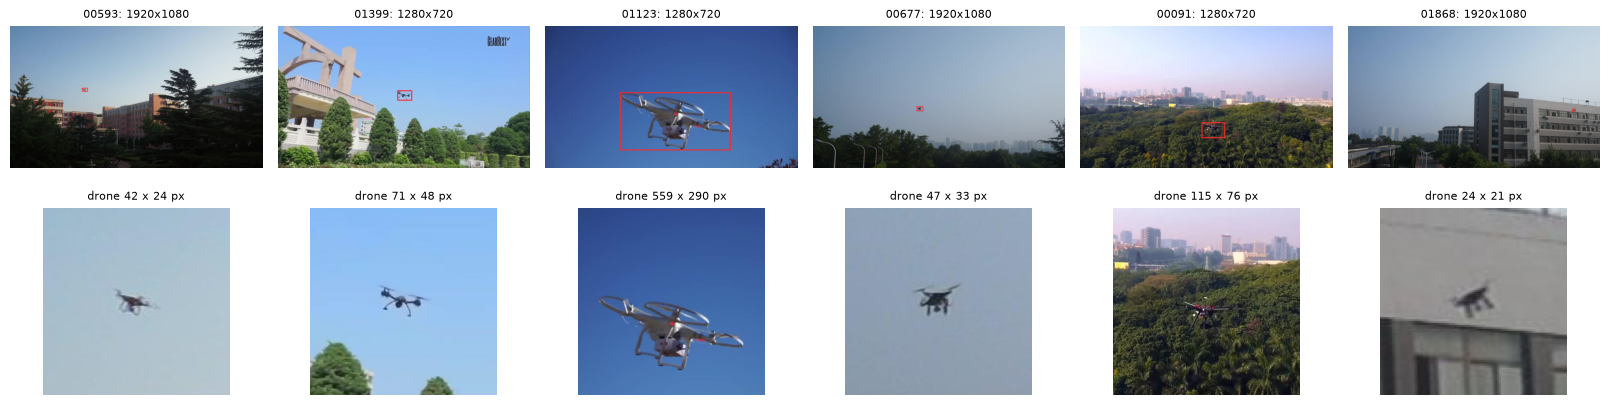

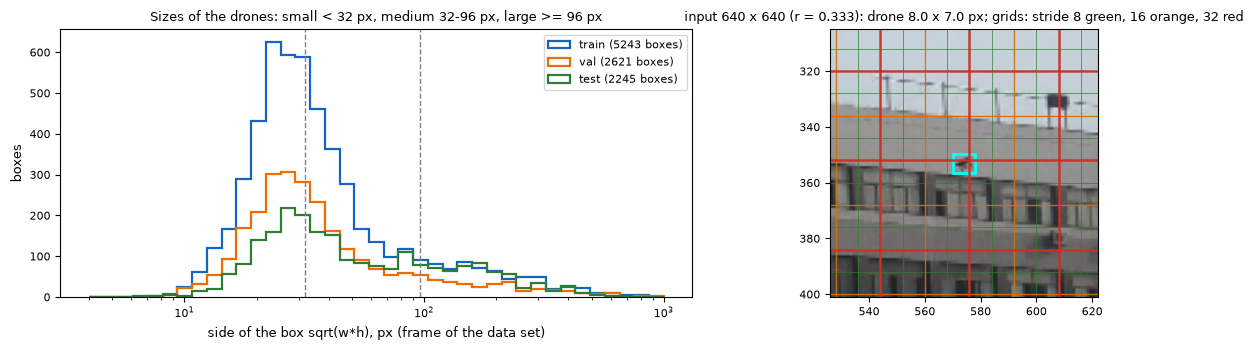

Drone of the image 01868 in the input 640 x 640: 8.0 x 7.0 px = 1.00 x 0.88 cells of stride 8, 0.50 x 0.44 cells of stride 16, 0.25 x 0.22 cells of stride 32


In [3]:
#@title 5.1.1 Drones in the images of a ground camera and the output grid of YOLO { display-mode: "form" }
N_SHOW = 6 #@param {type:"slider", min:3, max:9, step:3}
SEED = 0 #@param {type:"integer"}
GRID_IMAGE = -1 #@param {type:"integer"}

ann = {s: dut.annotations(s) for s in ("train", "val", "test")}


def box_sides(boxes_list):
    return np.array([math.sqrt(max(b[2] - b[0], 0) * max(b[3] - b[1], 0)) for bs in boxes_list for b in bs])


rows = []
SIDES = {}
for s, tb in ann.items():
    sd = box_sides(tb.boxes)
    SIDES[s] = sd
    rows.append({"part": s, "images": len(tb), "boxes": int(tb.n.sum()), "images without a drone": int((tb.n == 0).sum()),
                 "frames 1920 x 1080": f"{np.mean((tb.width == 1920) & (tb.height == 1080)):.0%}",
                 "median side of a box, px": round(float(np.median(sd)), 1),
                 "side < 32 px": f"{np.mean(sd < 32):.0%}", "32-96 px": f"{np.mean((sd >= 32) & (sd < 96)):.0%}",
                 ">= 96 px": f"{np.mean(sd >= 96):.0%}"})
display(pd.DataFrame(rows).set_index("part"))

rng = np.random.default_rng(SEED)
test = ann["test"]
show = rng.choice(np.where(test.n > 0)[0], N_SHOW, replace=False)
paths = dut.image_paths("test", test.image_id.values[show])
fig, axes = plt.subplots(2, N_SHOW, figsize=(2.7 * N_SHOW, 4.4), gridspec_kw={"height_ratios": [1.2, 1]})
for k, (i, p) in enumerate(zip(show, paths)):
    img = aitbc.to_rgb(cv2.imread(p)[..., ::-1])
    bs = test.boxes[i]
    axes[0, k].imshow(aitbc.draw_boxes(img, [{"box": b, "cls": "UAV"} for b in bs], color=(255, 40, 40),
                                       labels=False, thickness=max(2, img.shape[1] // 400)))
    axes[0, k].set_title(f"{test.image_id[i]}: {img.shape[1]}x{img.shape[0]}", fontsize=8)
    b = bs[0]
    side = max(b[2] - b[0], b[3] - b[1])
    axes[1, k].imshow(aitbc.crop_view(img, b, scale=4, min_side=48))
    axes[1, k].set_title(f"drone {b[2] - b[0]:.0f} x {b[3] - b[1]:.0f} px", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "NB08_511_gallery.png"), dpi=110)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
bins = np.logspace(np.log10(4), np.log10(1000), 40)
for s, c in zip(SIDES, ("#1565c0", "#ef6c00", "#2e7d32")):
    ax[0].hist(SIDES[s], bins=bins, histtype="step", lw=1.6, color=c, label=f"{s} ({len(SIDES[s])} boxes)")
for v in (32, 96):
    ax[0].axvline(v, color="grey", ls="--", lw=1)
ax[0].set_xscale("log")
ax[0].set_xlabel("side of the box sqrt(w*h), px (frame of the data set)")
ax[0].set_ylabel("boxes")
ax[0].legend(fontsize=8)
ax[0].set_title("Sizes of the drones: small < 32 px, medium 32-96 px, large >= 96 px", fontsize=9)

sides_show = [box_sides([test.boxes[j]]).min() for j in show]
gi = int(np.argmin(sides_show)) if GRID_IMAGE < 0 else GRID_IMAGE % len(show)
i = show[gi]
img = cv2.imread(paths[gi])[..., ::-1]
lb, r, pad = aitbc.letterbox(img, 640)
b = aitbc.boxes_to_input([test.boxes[i][0]], r, pad)[0]
cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
half = 48
x0, y0 = int(max(0, cx - half)), int(max(0, cy - half))
crop = lb[y0:y0 + 2 * half, x0:x0 + 2 * half]
ax[1].imshow(crop, extent=(x0, x0 + crop.shape[1], y0 + crop.shape[0], y0))
for stride, col, lw in ((8, "#2e7d32", 0.6), (16, "#ef6c00", 1.0), (32, "#c62828", 1.8)):
    for g in range(0, 641, stride):
        ax[1].axvline(g, color=col, lw=lw, alpha=0.8)
        ax[1].axhline(g, color=col, lw=lw, alpha=0.8)
ax[1].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="cyan", lw=2))
ax[1].set_xlim(x0, x0 + crop.shape[1]); ax[1].set_ylim(y0 + crop.shape[0], y0)
ax[1].set_title(f"input 640 x 640 (r = {r:.3f}): drone {b[2] - b[0]:.1f} x {b[3] - b[1]:.1f} px; "
                f"grids: stride 8 green, 16 orange, 32 red", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "NB08_511_sizes_grid.png"), dpi=110)
plt.show()
w_in, h_in = b[2] - b[0], b[3] - b[1]
print(f"Drone of the image {test.image_id[i]} in the input 640 x 640: {w_in:.1f} x {h_in:.1f} px = "
      + ", ".join(f"{w_in / s:.2f} x {h_in / s:.2f} cells of stride {s}" for s in (8, 16, 32)))

## Block 5.1.2. Intersection over union (IoU)

**Definition.** For a predicted box $B_p$ and a true (annotated) box $B_t$
$$\mathrm{IoU}(B_p, B_t) = \frac{|B_p \cap B_t|}{|B_p \cup B_t|} = \frac{|B_p \cap B_t|}{|B_p| + |B_t| - |B_p \cap B_t|}\in[0,1].$$
A detection is **correct** (true positive) if its IoU with a free true box is not less than the threshold $\tau$: $\tau = 0.5$ in the measure AP50 (Pascal VOC), $\tau = 0.5, 0.55, \dots, 0.95$ in the measure AP50-95 of COCO.

For two squares of side $a$ shifted by $d$ pixels along one axis $\mathrm{IoU} = \frac{a-d}{a+d}$; the shift that gives IoU $= 0.5$ is $d = a/3$. For a drone of 12 px this is 4 px, for a vehicle of 120 px it is 40 px: **the same error of a few pixels is negligible for a large object and fatal for a small one.**

**Parameters.** `SHIFT_X_PX`, `SHIFT_Y_PX` — shift of the predicted box relative to the true box of a real drone; `SCALE` — ratio of the sizes of the predicted and the true box; `IMAGE_NUMBER` — number of the test image of the gallery of block 5.1.1.

**Expected result.** The true and the predicted box on the enlarged fragment with the value of IoU; the curves of IoU against the shift for squares of 8, 16, 32, 64 and 128 px and the thresholds 0.5 and 0.75.

**What to observe.** For the default real drone (a box of about 42 px) a shift of 4 px gives IoU = 0.83, and the shift that gives IoU = 0.5 is 14 px. On the curves, a shift of 4 px brings a square of 8 px to IoU = 0.33 (an error at the threshold 0.5), while a square of 128 px keeps IoU = 0.94. A scale error acts in the same way: a box twice as large as the true one and with the same centre gives IoU = 0.25.

**Control question 2.** Why does COCO average AP over the thresholds 0.5–0.95, and why is the threshold 0.5 often used for small targets?

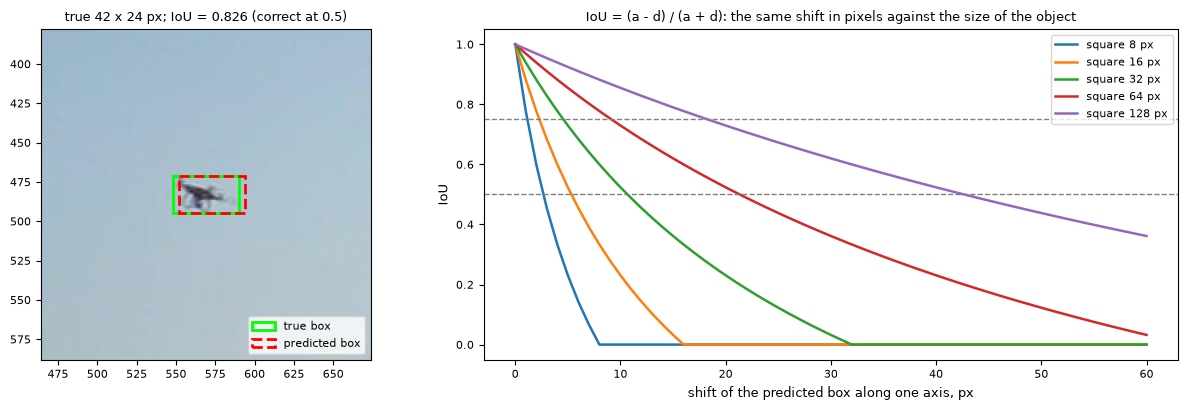

IoU = 0.826; shift giving IoU = 0.5 for this box along x: 14.0 px


In [4]:
#@title 5.1.2 IoU of a predicted and a true box { run: "auto", display-mode: "form" }
SHIFT_X_PX = 4 #@param {type:"slider", min:-30, max:30, step:1}
SHIFT_Y_PX = 0 #@param {type:"slider", min:-30, max:30, step:1}
SCALE = 1.0 #@param {type:"slider", min:0.5, max:2.0, step:0.05}
IMAGE_NUMBER = 0 #@param {type:"integer"}

i = show[IMAGE_NUMBER % len(show)]
img = cv2.imread(paths[IMAGE_NUMBER % len(show)])[..., ::-1]
t_box = np.array(test.boxes[i][0], float)
cx, cy = (t_box[0] + t_box[2]) / 2 + SHIFT_X_PX, (t_box[1] + t_box[3]) / 2 + SHIFT_Y_PX
w, h = (t_box[2] - t_box[0]) * SCALE, (t_box[3] - t_box[1]) * SCALE
p_box = np.array([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])
iou = aitbc.box_iou_matrix([p_box], [t_box])[0, 0]

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
side = max(t_box[2] - t_box[0], t_box[3] - t_box[1])
c = ((t_box[0] + t_box[2]) / 2, (t_box[1] + t_box[3]) / 2)
half = max(2.5 * side, 24)
ax[0].imshow(img)
ax[0].add_patch(plt.Rectangle(t_box[:2], *(t_box[2:] - t_box[:2]), fill=False, ec="lime", lw=2, label="true box"))
ax[0].add_patch(plt.Rectangle(p_box[:2], *(p_box[2:] - p_box[:2]), fill=False, ec="red", lw=2, ls="--", label="predicted box"))
ax[0].set_xlim(max(0, c[0] - half), min(img.shape[1], c[0] + half)); ax[0].set_ylim(min(img.shape[0], c[1] + half), max(0, c[1] - half))
ax[0].legend(fontsize=8, loc="lower right")
ax[0].set_title(f"true {t_box[2] - t_box[0]:.0f} x {t_box[3] - t_box[1]:.0f} px; IoU = {iou:.3f} "
                f"({'correct' if iou >= 0.5 else 'error'} at 0.5)", fontsize=9)
d = np.arange(0, 61)
for a in (8, 16, 32, 64, 128):
    ax[1].plot(d, np.clip((a - d) / (a + d), 0, 1), lw=1.8, label=f"square {a} px")
for t in (0.5, 0.75):
    ax[1].axhline(t, color="grey", ls="--", lw=1)
ax[1].set_xlabel("shift of the predicted box along one axis, px")
ax[1].set_ylabel("IoU")
ax[1].legend(fontsize=8)
ax[1].set_title("IoU = (a - d) / (a + d): the same shift in pixels against the size of the object", fontsize=9)
plt.tight_layout()
plt.show()
print(f"IoU = {iou:.3f}; shift giving IoU = 0.5 for this box along x: {(t_box[2] - t_box[0]) / 3:.1f} px")

## Block 5.1.3. Confidence of a detection and non-maximum suppression

**Confidence.** For every cell and class YOLO gives a score $s \in [0,1]$; a box is kept if $s \geq$ `CONF`. A low threshold keeps weak true detections and many false ones; a high threshold removes false detections and misses weak targets.

**Non-maximum suppression (NMS).** Neighbouring cells predict almost the same box of one object. NMS sorts the boxes by score and repeats: the box with the highest score is kept, the boxes with IoU $>$ `NMS_IOU` with it are removed. A low `NMS_IOU` removes the duplicates but can merge two close objects (a group of drones); a high `NMS_IOU` keeps the duplicates.

**Classes of COCO.** The YOLO11 model trained on COCO has no class *drone*. The images of DUT Anti-UAV show what such a model does with a drone: it assigns the nearest classes it knows — *airplane*, *bird*, *kite*. The boxes of these three classes are taken in this lecture as detections of a drone (class-agnostic evaluation).

**Parameters.** `MODEL` — YOLO11n (2.6 M parameters) or YOLO11s (9.4 M); `IMAGE_NUMBER` — test image of the gallery (−1 — the image where the drone gets the highest score); `CONF` — threshold of the confidence; `NMS_IOU` — threshold of NMS; the raw predictions are obtained with the confidence 0.01 and NMS switched off.

**Expected result.** The raw boxes and the boxes after NMS on the fragment of the drone, the table of the kept boxes with their classes and scores.

**What to observe.** In the image with the highest score of a drone (a large drone close to the camera), YOLO11n gives 17 raw boxes, 10 of them with a confidence of at least 0.25. NMS with the threshold 0.5 leaves one box: the class *airplane* with the confidence 0.87 and IoU 0.98 with the true box. The model has no class drone, so it calls the drone by the nearest class of COCO. Set `NMS_IOU` = 0.9 and then `CONF` = 0.05 and count the boxes again.

**Control question 3.** Why does NMS reduce the number of boxes on one object to one, and in which situation of a group of targets is it harmful?

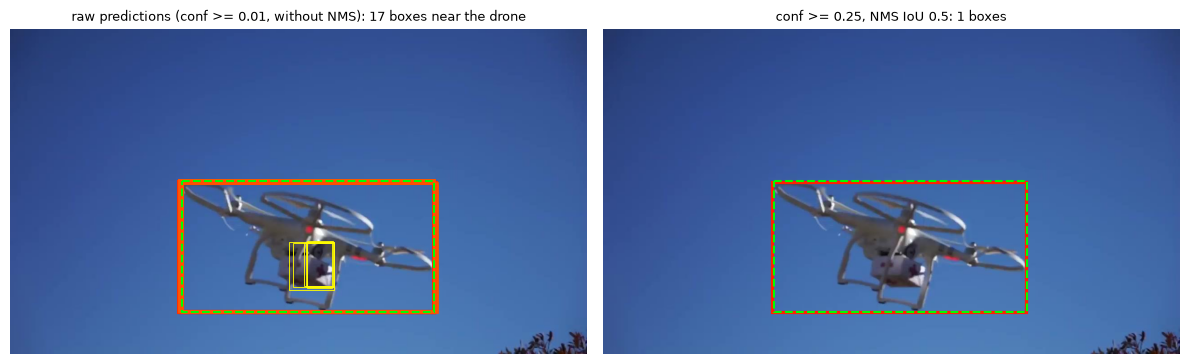

All raw boxes: 17; with conf >= 0.25: 10; after NMS: 1


,class of COCO,confidence,IoU with the drone,"size, px"
0,airplane,0.865,0.981,563 x 287


In [5]:
#@title 5.1.3 Raw predictions, threshold of the confidence and NMS { display-mode: "form" }
MODEL = "yolo11n.pt" #@param ["yolo11n.pt", "yolo11s.pt"]
IMAGE_NUMBER = -1 #@param {type:"integer"}
CONF = 0.25 #@param {type:"slider", min:0.01, max:0.9, step:0.01}
NMS_IOU = 0.5 #@param {type:"slider", min:0.1, max:0.95, step:0.05}

COCO_UAV = [4, 14, 33]  # airplane, bird, kite: the nearest classes of COCO for a drone
yolo = load_yolo(MODEL)
RAW = []
for k, p in enumerate(paths):
    im = cv2.imread(p)[..., ::-1].copy()
    rb, rs, rc, _ = aitbc.yolo_predict(yolo, im, imgsz=1280, conf=0.01, iou=0.999, max_det=1000)
    iou_t = aitbc.box_iou_matrix(rb, [test.boxes[show[k]][0]])[:, 0] if len(rb) else np.zeros(0)
    RAW.append((im, rb, rs, rc, float(rs[iou_t >= 0.3].max()) if np.any(iou_t >= 0.3) else 0.0))
k_img = int(np.argmax([r[4] for r in RAW])) if IMAGE_NUMBER < 0 else IMAGE_NUMBER % len(show)
i = show[k_img]
img, raw_b, raw_s, raw_c, _ = RAW[k_img]
keep_conf = raw_s >= CONF
k = aitbc.nms(raw_b[keep_conf], raw_s[keep_conf], NMS_IOU)
fin_b, fin_s, fin_c = raw_b[keep_conf][k], raw_s[keep_conf][k], raw_c[keep_conf][k]
t_box = np.array(test.boxes[i][0], float)
side = max(t_box[2] - t_box[0], t_box[3] - t_box[1])
c = ((t_box[0] + t_box[2]) / 2, (t_box[1] + t_box[3]) / 2)
half = max(4 * side, 40)
near = lambda bb: (np.abs((bb[:, 0] + bb[:, 2]) / 2 - c[0]) < half) & (np.abs((bb[:, 1] + bb[:, 3]) / 2 - c[1]) < half)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (bb, ss, title) in zip(ax, ((raw_b, raw_s, f"raw predictions (conf >= 0.01, without NMS): {near(raw_b).sum()} boxes near the drone"),
                                   (fin_b, fin_s, f"conf >= {CONF}, NMS IoU {NMS_IOU}: {near(fin_b).sum() if len(fin_b) else 0} boxes"))):
    a.imshow(img)
    for b, s in zip(bb, ss):
        a.add_patch(plt.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, ec=plt.cm.autumn(1 - s), lw=0.6 + 2 * s))
    a.add_patch(plt.Rectangle(t_box[:2], *(t_box[2:] - t_box[:2]), fill=False, ec="lime", lw=1.5, ls="--"))
    a.set_xlim(max(0, c[0] - half), min(img.shape[1], c[0] + half))
    a.set_ylim(min(img.shape[0], c[1] + half), max(0, c[1] - half))
    a.set_title(title, fontsize=9)
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "NB08_513_nms.png"), dpi=110)
plt.show()
rows = []
for b, s, cl in zip(fin_b, fin_s, fin_c):
    rows.append({"class of COCO": yolo.names[int(cl)], "confidence": round(float(s), 3),
                 "IoU with the drone": round(float(aitbc.box_iou_matrix([b], [t_box])[0, 0]), 3),
                 "size, px": f"{b[2] - b[0]:.0f} x {b[3] - b[1]:.0f}"})
print(f"All raw boxes: {len(raw_b)}; with conf >= {CONF}: {keep_conf.sum()}; after NMS: {len(fin_b)}")
display(pd.DataFrame(rows).sort_values("confidence", ascending=False).head(10) if rows else pd.DataFrame({"result": ["no boxes"]}))

## Block 5.1.4. Precision, recall, AP and mAP

**Counting.** The detections of all test images are sorted by confidence. Going down the list, every detection is matched with a free true box of its image with IoU $\geq \tau$ (true positive, TP) or not (false positive, FP); the true boxes left without a detection are false negatives (FN). For the threshold of the confidence $s$
$$P(s) = \frac{TP(s)}{TP(s) + FP(s)}, \qquad R(s) = \frac{TP(s)}{N_{\text{true}}} .$$

**Average precision.** AP is the area under the curve $P(R)$ made non-increasing (the envelope $\tilde P(R) = \max_{R' \geq R} P(R')$); COCO averages $\tilde P$ over 101 values of the recall $0, 0.01, \dots, 1$:
$$\mathrm{AP}_\tau = \frac{1}{101}\sum_{R \in \{0, 0.01, \dots, 1\}} \tilde P(R), \qquad \mathrm{AP}_{50\text{-}95} = \frac{1}{10}\sum_{\tau=0.50}^{0.95}\mathrm{AP}_\tau .$$
**mAP** is the mean of AP over the classes; with one class (drone) mAP = AP. The function `ap_per_class` of Ultralytics integrates the same curve by trapezoids and gives a slightly different number; both are shown.

**Parameters.** `N_EVAL` — random test images; `MODEL`; `IMG_SIZE` — size of the input; `CLASSES` — which detections are taken as a drone (the three nearest classes of COCO or all 80 classes); `CONF_WORK` — working threshold for the table of precision and recall.

**Expected result.** The table AP50, AP50-95, precision and recall at the working threshold, the threshold of the maximum F1; the precision-recall curve; the precision and the recall against the threshold.

**What to observe.** On 150 test images (152 drones) YOLO11n at the input 640 reaches AP50 = 0.517 and AP50-95 = 0.325 (the function of Ultralytics gives 0.516 and 0.324). At the threshold 0.25 the precision is high (0.88) but the recall is only 0.37: almost every reported drone is real, but two of three drones are missed. The maximum F1 = 0.59 is reached at the much lower threshold 0.13. For an air-defence post a threshold below 0.25 is chosen, accepting more false alarms.

**Control question 4.** Why is AP independent of the working threshold, and how is the working threshold chosen for an air-defence post where a missed drone is more dangerous than a false alarm?

,value
test images,150
drones (true boxes),152
"AP50 (COCO, 101 points)",0.517
AP50-95 (COCO),0.325
AP50 / AP50-95 by ap_per_class of Ultralytics,0.516 / 0.324
precision at conf >= 0.25,0.875
recall at conf >= 0.25,0.368
false detections per image at conf >= 0.25,0.05
threshold of the maximum F1,0.13 (F1 = 0.593)
"time per image (cpu, input 640)",40 ms


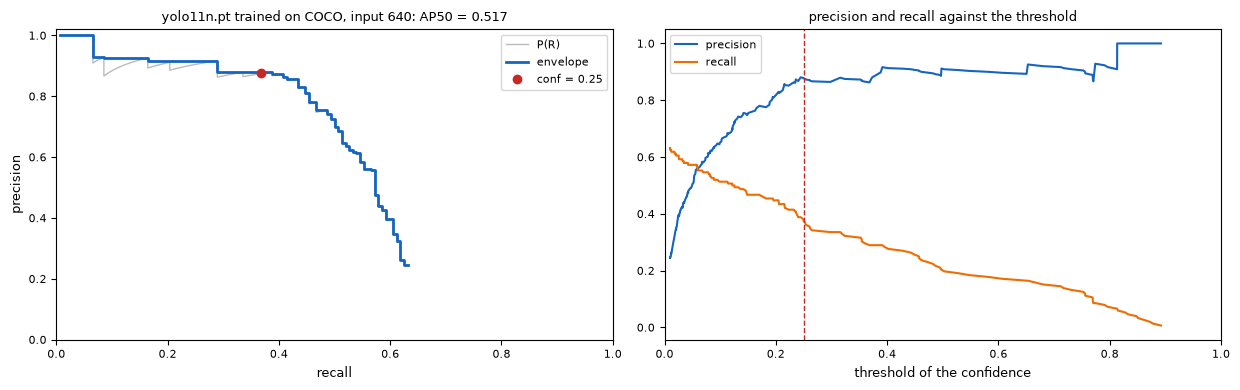

In [6]:
#@title 5.1.4 Evaluation of the YOLO model trained on COCO on the drones of DUT Anti-UAV { display-mode: "form" }
N_EVAL = 150 #@param {type:"slider", min:50, max:500, step:50}
MODEL = "yolo11n.pt" #@param ["yolo11n.pt", "yolo11s.pt"]
IMG_SIZE = 640 #@param [640, 1280] {type:"raw"}
CLASSES = "airplane, bird, kite" #@param ["airplane, bird, kite", "all 80 classes"]
CONF_WORK = 0.25 #@param {type:"slider", min:0.05, max:0.8, step:0.05}

from ultralytics.utils.metrics import ap_per_class
yolo = load_yolo(MODEL)
cls_sel = COCO_UAV if CLASSES.startswith("airplane") else None
rng = np.random.default_rng(1)
EVAL_IDX = np.sort(rng.choice(np.where(test.n > 0)[0], N_EVAL, replace=False))
EVAL_PATHS = dut.image_paths("test", test.image_id.values[EVAL_IDX])
EVAL_GT = [np.array(test.boxes[i], float) for i in EVAL_IDX]


def run_detector(model, imgsz, classes, conf=0.01):
    out, t = [], 0.0
    for p in EVAL_PATHS:
        img = cv2.imread(p)[..., ::-1]
        t1 = time.time()
        b, s, c, _ = aitbc.yolo_predict(model, img, imgsz=imgsz, conf=conf, classes=classes)
        t += time.time() - t1
        out.append((b, s))
    return out, 1000 * t / len(EVAL_PATHS)


PRED_514, MS_514 = run_detector(yolo, IMG_SIZE, cls_sel)
THRS = np.round(np.arange(0.5, 0.96, 0.05), 2)
ev = aitbc.evaluate_detections(PRED_514, EVAL_GT, iou_thrs=THRS, conf=CONF_WORK)
conf_f1, f1 = aitbc.f1_threshold(ev["curve"])
# the same curve by the function of Ultralytics
tp = np.concatenate([np.stack([aitbc.match_greedy(b, s, g, t)[0] for t in THRS], 1) for (b, s), g in zip(PRED_514, EVAL_GT)])
sc = np.concatenate([s for _, s in PRED_514])
res = ap_per_class(tp.astype(float), sc, np.zeros(len(sc)), np.zeros(sum(len(g) for g in EVAL_GT)))
ap_ul = res[5][0]
display(pd.DataFrame({"value": [len(EVAL_PATHS), ev["n_gt"], f"{ev['AP50']:.3f}", f"{ev['AP']:.3f}",
                                f"{ap_ul[0]:.3f} / {ap_ul.mean():.3f}", f"{ev['precision']:.3f}", f"{ev['recall']:.3f}",
                                f"{ev['false_per_image']:.2f}", f"{conf_f1:.2f} (F1 = {f1:.3f})", f"{MS_514:.0f} ms"]},
                     index=["test images", "drones (true boxes)", "AP50 (COCO, 101 points)", "AP50-95 (COCO)",
                            "AP50 / AP50-95 by ap_per_class of Ultralytics", f"precision at conf >= {CONF_WORK}",
                            f"recall at conf >= {CONF_WORK}", f"false detections per image at conf >= {CONF_WORK}",
                            "threshold of the maximum F1", f"time per image ({DEVICE}, input {IMG_SIZE})"]))
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
cv_ = ev["curve"]
ax[0].plot(cv_["recall"], cv_["precision"], color="#bbbbbb", lw=1, label="P(R)")
ax[0].plot(cv_["recall"], np.maximum.accumulate(cv_["precision"][::-1])[::-1], color="#1565c0", lw=2, label="envelope")
j = np.searchsorted(-cv_["scores"], -CONF_WORK, side="right") - 1
if j >= 0:
    ax[0].plot(cv_["recall"][j], cv_["precision"][j], "o", color="#c62828", label=f"conf = {CONF_WORK}")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1.02)
ax[0].legend(fontsize=8)
ax[0].set_title(f"{MODEL} trained on COCO, input {IMG_SIZE}: AP50 = {ev['AP50']:.3f}", fontsize=9)
ax[1].plot(cv_["scores"], cv_["precision"], label="precision", color="#1565c0")
ax[1].plot(cv_["scores"], cv_["recall"], label="recall", color="#ef6c00")
ax[1].axvline(CONF_WORK, color="#c62828", ls="--", lw=1)
ax[1].set_xlabel("threshold of the confidence"); ax[1].set_xlim(0, 1); ax[1].legend(fontsize=8)
ax[1].set_title("precision and recall against the threshold", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "NB08_514_precision_recall.png"), dpi=110)
plt.show()
RESULT_51 = {"model": MODEL, "img_size": IMG_SIZE, "classes": CLASSES, "n_images": int(N_EVAL),
             "AP50": round(ev["AP50"], 4), "AP50_95": round(ev["AP"], 4), "precision": round(ev["precision"], 4),
             "recall": round(ev["recall"], 4), "conf_work": CONF_WORK}

## Block 5.1.5. Small targets: size of the input, slicing of the frame and the cost in time

**Why small targets are lost.** A frame of 1920 × 1080 reduced to the input 640 × 640 is scaled by $r = 1/3$: a drone of 24 px becomes 8 px, i.e. one cell of the finest grid (stride 8). Its features are mixed with the background in the first layers, and the detector misses it.

**Two remedies.**
1. **Larger input** $S$ (1280 instead of 640): the drone keeps more pixels; the computation grows as $S^2$.
2. **Slicing** (tiling, SAHI): the frame is cut into windows $T \times T$ with the overlap $o$; every window is processed at its own resolution, the boxes are shifted back to the frame and merged by NMS. The number of runs of the network is
$$n = \left\lceil\frac{W - oT}{(1-o)T}\right\rceil\cdot\left\lceil\frac{H - oT}{(1-o)T}\right\rceil \ (+1 \text{ for the whole frame}).$$

**Parameters.** `TILE` — size of a window; `OVERLAP` — overlap of the windows; `WITH_FULL_FRAME` — also process the whole frame (for large targets close to the camera). The model, the images and the classes are those of block 5.1.4.

**Expected result.** The table of AP50, recall at the working threshold by size groups and the time per image for three variants (input 640, input 1280, slicing); the bar chart of the recall by sizes; a small drone found only by the slicing.

**What to observe.** The input 1280 raises AP50 from 0.517 to 0.577 and the recall at 0.25 from 0.37 to 0.42 at almost three times the time (40 → 109 ms per image on the processor of the test computer). Slicing with windows of 640 px (8.3 runs of the network per image) gives the highest recall, 0.59, and AP50 = 0.583, but the precision falls from 0.88 to 0.73 (0.23 false detections per image instead of 0.05) and the time grows about 10 times (421 ms per image). The gain is in the small drones: on the bar chart the recall of the 64 drones smaller than 32 px grows from about 0.1 (input 640) to about 0.3 (input 1280) and 0.46 (slicing), while for the drones of 96 px and more it grows only from about 0.66 to 0.77.

**Control question 5.** Which variant would you choose for a post with a computer of 10 TOPS that must process 25 frames per second, and what would you lose?

,runs of the network per image,AP50,recall at conf >= 0.25,precision,false detections per image,"time per image, ms (cpu)"
variant,,,,,,
input 640,1.0,0.517,0.368,0.875,0.05,40
input 1280,1.0,0.577,0.421,0.865,0.07,109
"slicing 640 px, overlap 0.2",8.3,0.583,0.592,0.726,0.23,421


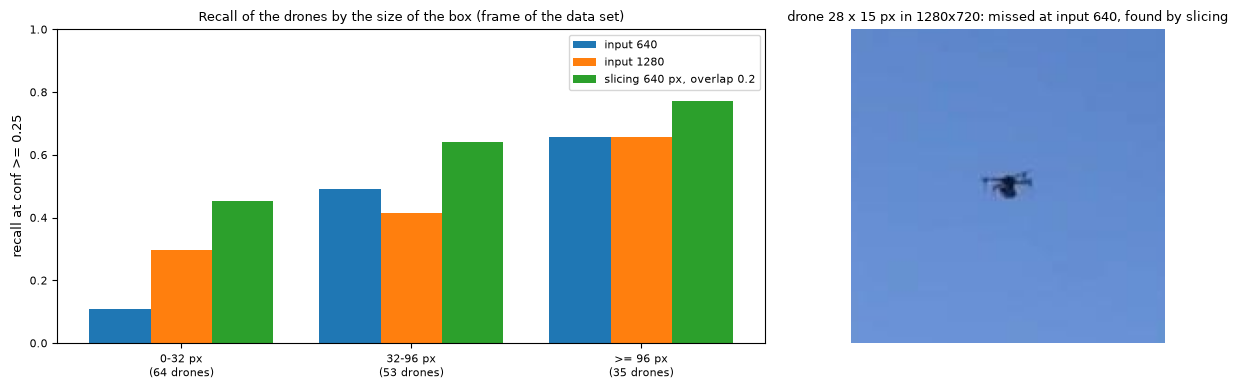

project.json updated: lesson 5.1, keys: lesson_5_1


In [7]:
#@title 5.1.5 Input 640, input 1280 and slicing of the frame { display-mode: "form" }
TILE = 640 #@param [480, 640, 800] {type:"raw"}
OVERLAP = 0.2 #@param {type:"slider", min:0.0, max:0.4, step:0.05}
WITH_FULL_FRAME = True #@param {type:"boolean"}

variants = {}
for name, imgsz in (("input 640", 640), ("input 1280", 1280)):
    if name == f"input {IMG_SIZE}":
        variants[name] = (PRED_514, MS_514, 1)
    else:
        variants[name] = run_detector(yolo, imgsz, cls_sel) + (1,)
out, t, runs = [], 0.0, 0
for p in EVAL_PATHS:
    img = cv2.imread(p)[..., ::-1]
    t1 = time.time()
    b, s, c, n = aitbc.predict_tiled(yolo, img, tile=TILE, overlap=OVERLAP, imgsz=TILE, conf=0.01, classes=cls_sel,
                                     full_frame=WITH_FULL_FRAME)
    t += time.time() - t1
    runs += n
    out.append((b, s))
variants[f"slicing {TILE} px, overlap {OVERLAP}"] = (out, 1000 * t / len(EVAL_PATHS), runs / len(EVAL_PATHS))

rows, by_size = [], {}
for name, (pred, ms, n) in variants.items():
    e = aitbc.evaluate_detections(pred, EVAL_GT, iou_thrs=(0.5,), conf=CONF_WORK)
    by_size[name] = e["recall_by_size"]
    rows.append({"variant": name, "runs of the network per image": round(n, 1), "AP50": round(e["AP50"], 3),
                 f"recall at conf >= {CONF_WORK}": round(e["recall"], 3), "precision": round(e["precision"], 3),
                 "false detections per image": round(e["false_per_image"], 2), f"time per image, ms ({DEVICE})": round(ms)})
TAB_515 = pd.DataFrame(rows).set_index("variant")
display(TAB_515)
groups = list(next(iter(by_size.values())).keys())
fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.3, 1]})
wbar = 0.8 / len(by_size)
for k, (name, g) in enumerate(by_size.items()):
    ax[0].bar(np.arange(len(groups)) + k * wbar, [g[x][0] for x in groups], wbar, label=name)
ax[0].set_xticks(np.arange(len(groups)) + wbar * (len(by_size) - 1) / 2)
ax[0].set_xticklabels([f"{x}\n({next(iter(by_size.values()))[x][1]} drones)" for x in groups])
ax[0].set_ylabel(f"recall at conf >= {CONF_WORK}"); ax[0].set_ylim(0, 1); ax[0].legend(fontsize=8)
ax[0].set_title("Recall of the drones by the size of the box (frame of the data set)", fontsize=9)
# a small drone found by the slicing and missed at the input 640
names = list(variants)
shown = False
for (b0, s0), (b2, s2), g, p in zip(variants[names[0]][0], variants[names[2]][0], EVAL_GT, EVAL_PATHS):
    for tb in g:
        side = math.sqrt((tb[2] - tb[0]) * (tb[3] - tb[1]))
        if side >= 32:
            continue
        hit0 = len(b0) and (aitbc.box_iou_matrix([tb], b0[s0 >= CONF_WORK]).max(initial=0) >= 0.5)
        hit2 = len(b2) and (aitbc.box_iou_matrix([tb], b2[s2 >= CONF_WORK]).max(initial=0) >= 0.5)
        if hit2 and not hit0:
            img = cv2.imread(p)[..., ::-1]
            ax[1].imshow(aitbc.crop_view(img, tb, scale=6, min_side=64))
            ax[1].set_title(f"drone {tb[2] - tb[0]:.0f} x {tb[3] - tb[1]:.0f} px in {img.shape[1]}x{img.shape[0]}: "
                            f"missed at input 640, found by slicing", fontsize=9)
            shown = True
            break
    if shown:
        break
ax[1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "NB08_515_small_targets.png"), dpi=110)
plt.show()
RESULT_51["small_targets"] = TAB_515.reset_index().to_dict("records")
update_project_json("5.1", {"lesson_5_1": RESULT_51})

### Self-check of Lesson 5.1

1. What does a detector give for an image, and how does a one-stage detector differ from a classifier applied to windows?
2. Write the formula of IoU and compute it for two squares of 12 px shifted by 3 px.
3. What do the threshold of the confidence and the threshold of NMS change in the list of detections?
4. How are precision, recall and AP computed, and why is AP50-95 lower than AP50?
5. Name two ways to detect small targets and their cost in computation.

---
# Lesson 5.2 (Group class). Segmentation of the traversable area, tracking of objects and the video-analysis pipeline

**Learning questions**
1. Semantic segmentation of the terrain and the traversable area of a ground robotic platform (UGV).
2. Segmentation network LR-ASPP MobileNetV3 and its transfer learning.
3. Tracking of objects by detection: Kalman filter, association by IoU, ByteTrack.
4. Measures of tracking: MOTA, IDF1, identity switches.
5. Video-analysis pipeline and the requirements of real time.

**Situation of the lesson.** A ground robotic platform moves along field tracks and across a training area; its front camera must show in every frame where it can drive. A reconnaissance UAV over a crossroads must keep the identity of every vehicle from frame to frame. Both tasks run on an onboard computer in real time. The group class builds the segmentation of the traversable area, compares two trackers and measures the time of every stage of the video pipeline.

## Block 5.2.1. Terrain classes and the traversable area of a ground robotic platform

**Semantic segmentation** assigns a class to every pixel of the frame. The annotation of **GOOSE** has 64 classes of an unstructured environment (asphalt, gravel, soil, low and high grass, bushes, trees, buildings, vehicles, persons, sky, …). For the motion of a UGV they are joined into three groups of **traversability**:
- **traversable** — asphalt, cobble, gravel, soil, low grass, moss, leaves, snow, markings, sidewalks;
- **conditionally traversable** — high grass, crops, debris, tree roots (the speed must be reduced);
- **obstacle** — everything else (trees, bushes, walls, poles, vehicles, persons, water); the sky and the own vehicle are not evaluated.

**Data and parts.** The validation part of GOOSE has 962 frames from 8 recording sessions (sequences). Consecutive frames of one session are almost the same; therefore the test frames are taken from **other sessions** than the training frames (the lesson of Topic 4 on leakage): by default the test part is the session on a **military training area** (Garching *Übungsplatz*) and a session **in rain**.

**Parameters.** `N_TRAIN_PER_SEQUENCE` — training frames per training session; `N_TEST_PER_SEQUENCE` — test frames per test session; `TEST_SEQUENCES` — sessions of the test part; `SEED_SEG` — choice of the frames. Frames are reduced to 512 × 256 px.

**Expected result.** The table of the sessions with the shares of the three groups, examples of the frames with the groups of traversability.

**What to observe.** The shares of the groups differ strongly between the sessions: the field tracks of Siegertsbrunn have 53 % traversable and 27 % conditionally traversable terrain, the forest and hills of Aying more than 50 % obstacles. The conditionally traversable group (high grass, crops) is frequent only in two training sessions (22–27 %); in the test sessions on the training area and in rain it is 13 % and 3 %.

**Control question 6.** Why is a frame of the training area not used in the training if the network must work on a training area?

72 training and 30 test frames prepared in 7 s


,frames in GOOSE val,part,frames used,traversable,conditionally traversable,obstacle
session,,,,,,
2022-07-22_flight,151,training,12,27%,22%,51%
2022-08-30_siegertsbrunn_feldwege,103,training,12,53%,27%,20%
2022-09-21_garching_uebungsplatz_2,123,test,15,39%,13%,47%
2022-12-07_aying_hills,134,training,12,38%,4%,58%
2023-01-20_aying_mangfall_2,191,training,12,48%,0%,52%
2023-03-03_garching_2,106,training,12,46%,4%,50%
2023-05-15_neubiberg_rain,73,test,15,44%,3%,53%
2023-05-17_neubiberg_sunny,81,training,12,43%,3%,54%


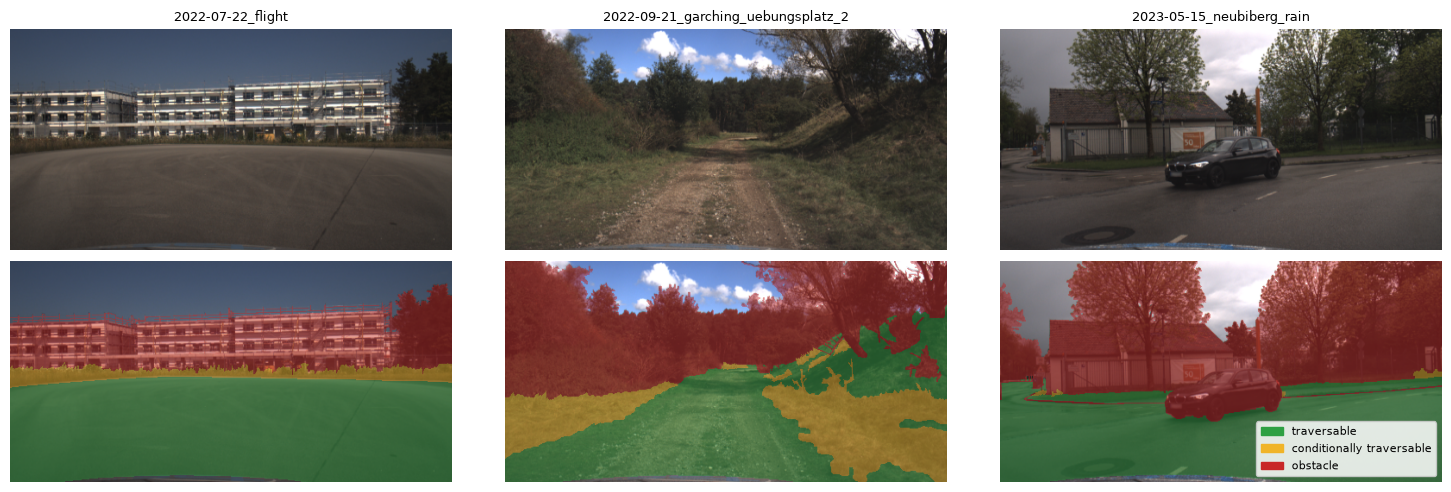

In [8]:
#@title 5.2.1 Terrain classes of GOOSE and the groups of traversability { display-mode: "form" }
N_TRAIN_PER_SEQUENCE = 12 #@param {type:"slider", min:4, max:40, step:4}
N_TEST_PER_SEQUENCE = 15 #@param {type:"slider", min:5, max:40, step:5}
TEST_SEQUENCES = "training area + rain" #@param ["training area + rain", "training area", "hills + rain"]
SEED_SEG = 0 #@param {type:"integer"}

SEG_SIZE = (512, 256)
TRAV_NAMES = ["traversable", "conditionally traversable", "obstacle"]
TRAV_COLORS = np.array([[46, 160, 67], [240, 180, 40], [200, 40, 40]], np.uint8)
TEST_SETS = {"training area + rain": ["2022-09-21_garching_uebungsplatz_2", "2023-05-15_neubiberg_rain"],
             "training area": ["2022-09-21_garching_uebungsplatz_2"],
             "hills + rain": ["2022-12-07_aying_hills", "2023-05-15_neubiberg_rain"]}
test_seqs = TEST_SETS[TEST_SEQUENCES]
by_seq = collections.defaultdict(list)
for m in goose.frames():
    by_seq[m.split("/")[2]].append(m)
rng = np.random.default_rng(SEED_SEG)


def pick(lst, n):
    idx = np.sort(rng.choice(len(lst), min(n, len(lst)), replace=False))
    return [lst[i] for i in idx]


seg_train = [m for s in sorted(by_seq) if s not in test_seqs for m in pick(by_seq[s], N_TRAIN_PER_SEQUENCE)]
seg_test = [m for s in test_seqs for m in pick(by_seq[s], N_TEST_PER_SEQUENCE)]
t0 = time.time()
goose.prefetch(seg_train + seg_test)


def load_seg(member):
    img, lab = goose.load(member, scale=0.25)
    img = cv2.resize(img, SEG_SIZE, interpolation=cv2.INTER_AREA)
    lab = cv2.resize(lab, SEG_SIZE, interpolation=cv2.INTER_NEAREST)
    t = goose.traversability(lab)                       # 0 not evaluated, 1, 2, 3
    return img, np.where(t == 0, 255, t - 1).astype(np.uint8)


SEG_TR = [load_seg(m) for m in seg_train]
SEG_TE = [load_seg(m) for m in seg_test]
print(f"{len(SEG_TR)} training and {len(SEG_TE)} test frames prepared in {time.time() - t0:.0f} s")
rows = []
for s in sorted(by_seq):
    part = "test" if s in test_seqs else "training"
    mem = seg_test if part == "test" else seg_train
    labs = [y for m, (x, y) in zip(mem, SEG_TE if part == "test" else SEG_TR) if m.split("/")[2] == s]
    v = np.concatenate([y[y != 255] for y in labs]) if labs else np.zeros(0)
    rows.append({"session": s, "frames in GOOSE val": len(by_seq[s]), "part": part, "frames used": len(labs),
                 **{n: f"{np.mean(v == k):.0%}" if len(v) else "-" for k, n in enumerate(TRAV_NAMES)}})
display(pd.DataFrame(rows).set_index("session"))


def trav_overlay(img, y, alpha=0.45):
    col = np.zeros_like(img)
    m = y != 255
    col[m] = TRAV_COLORS[y[m]]
    out = img.copy()
    out[m] = (img[m] * (1 - alpha) + col[m] * alpha).astype(np.uint8)
    return out


ex = [SEG_TR[0], SEG_TE[0], SEG_TE[-1]]
ex_names = [seg_train[0].split("/")[2], seg_test[0].split("/")[2], seg_test[-1].split("/")[2]]
fig, axes = plt.subplots(2, 3, figsize=(15, 5))
for k, ((x, y), n) in enumerate(zip(ex, ex_names)):
    axes[0, k].imshow(x); axes[0, k].set_title(n, fontsize=9)
    axes[1, k].imshow(trav_overlay(x, y))
for a in axes.ravel():
    a.axis("off")
aitbc.legend(axes[1, 2], TRAV_NAMES, TRAV_COLORS, loc="lower right", fontsize=8)   # colours 0...255
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "NB08_521_traversability.png"), dpi=110)
plt.show()

## Block 5.2.2. Segmentation network LR-ASPP MobileNetV3: transfer learning and quality

**Network.** LR-ASPP (*Lite Reduced Atrous Spatial Pyramid Pooling*, Howard et al., 2019) is the segmentation head of MobileNetV3: the features of the stride 16 (960 channels) are weighted by a global attention branch, joined with the features of the stride 8 (40 channels) and converted by $1\times1$ convolutions into the scores of the classes; the scores are enlarged to the size of the input. The backbone MobileNetV3-Large and the head were trained by torchvision on COCO with the 21 classes of Pascal VOC.

**Transfer learning** as in Lesson 4.4: the backbone is frozen, its features of the training frames are computed once, the two output convolutions are replaced for 3 groups of traversability, and the head is trained by the cross-entropy over the evaluated pixels (the pixels of the sky and of the own vehicle are ignored).

**Quality.** For every group $c$: $\mathrm{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}$ over the pixels of the test frames; mIoU is their mean.

**Decision of motion.** In front of the platform the **corridor** of the next metres of motion is taken (a trapezoid in the bottom part of the frame). If at least 80 % of its pixels are traversable — *go*; if at least 80 % are traversable or conditionally traversable — *slow*; otherwise — *stop*. The decision by the network is compared with the decision by the annotation.

**Parameters.** `EPOCHS_SEG` — epochs of the training of the head; `LR_SEG` — learning rate; `SHOW_TEST` — number of the test frame shown.

**Expected result.** The curve of the loss, the IoU of the groups on the training and the test part, the time of one frame, the agreement of the decisions of motion, three test frames with the annotation and the prediction.

**What to observe.** Only the head (246 526 parameters) is trained, in about 20 s on the processor. On the test sessions the IoU of the traversable terrain is 0.79 and of the obstacles 0.89, but the conditionally traversable group almost fails (IoU 0.04 against 0.61 in the training part): it is rare in the test sessions and is confused with the neighbouring groups; mIoU falls from 0.82 to 0.57. The decision of motion in the corridor agrees with the annotation in 87 % of the 30 test frames (by the annotation 26 go, 1 slow, 3 stop). The whole network takes about 25 ms per frame of 512 × 256 on the processor.

**Control question 7.** Which error of the segmentation is dangerous for a UGV, and which is only costly in time?

,training part,test part (other sessions)
IoU: traversable,0.894,0.785
IoU: conditionally traversable,0.606,0.035
IoU: obstacle,0.948,0.889
mIoU,0.816,0.570


,value
training frames,72
test frames,30
trained parameters (head),246526
features of the backbone,3 s
training of the head,18 s (40 epochs)
"one frame 512 x 256, whole network",26 ms (cpu)
decision of motion: agreement with the annotation,87% of 30 test frames
decisions by the annotation,"go: 26, slow: 1, stop: 3"


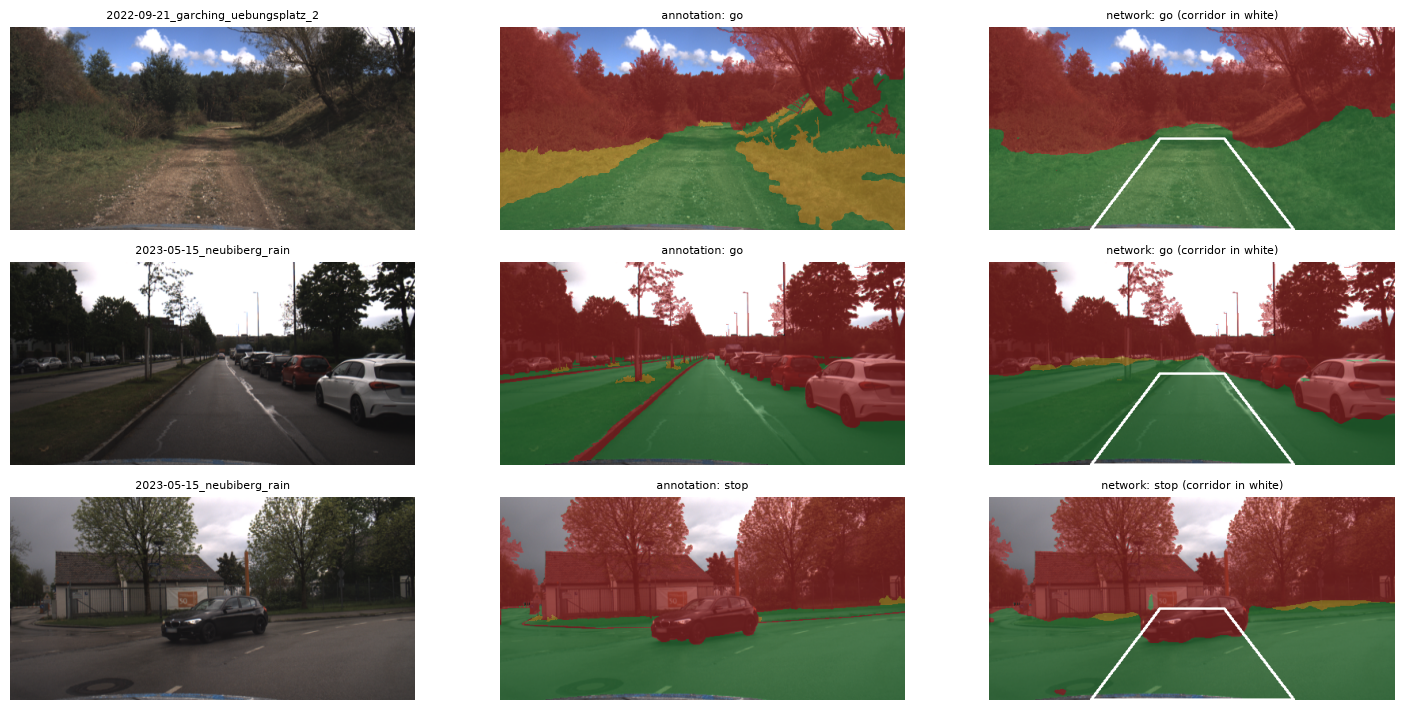

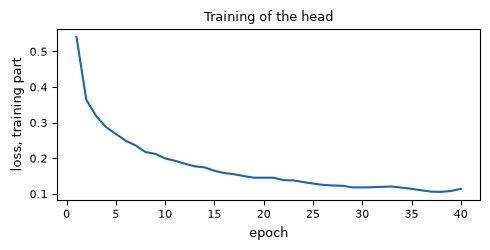

In [9]:
#@title 5.2.2 LR-ASPP MobileNetV3: training of the head and the IoU of the groups { display-mode: "form" }
EPOCHS_SEG = 40 #@param {type:"slider", min:5, max:100, step:5}
LR_SEG = 0.003 #@param {type:"number"}
SHOW_TEST = 0 #@param {type:"integer"}

import torch.nn.functional as F
torch.manual_seed(0)
seg_model = aitbc.lraspp_traversability(3).to(DEVICE).eval()
MEAN = torch.tensor(aitbc.IMAGENET_MEAN).view(1, 3, 1, 1)
STD = torch.tensor(aitbc.IMAGENET_STD).view(1, 3, 1, 1)


def to_batch(imgs):
    x = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).float() / 255.0
    return ((x - MEAN) / STD).to(DEVICE)


@torch.no_grad()
def backbone_features(data, batch=8):
    low, high = [], []
    for k in range(0, len(data), batch):
        f = seg_model.backbone(to_batch([x for x, _ in data[k:k + batch]]))
        low.append(f["low"].half().cpu()); high.append(f["high"].half().cpu())
    return torch.cat(low), torch.cat(high)


t0 = time.time()
F_TR = backbone_features(SEG_TR)
F_TE = backbone_features(SEG_TE)
Y_TR = torch.from_numpy(np.stack([y for _, y in SEG_TR])).long()
Y_TE = torch.from_numpy(np.stack([y for _, y in SEG_TE])).long()
t_feat = time.time() - t0
head = seg_model.classifier
opt = torch.optim.Adam(head.parameters(), lr=LR_SEG)
w = torch.tensor([1.0, 1.5, 1.0], device=DEVICE)       # conditional terrain is the rarest group
hist = []
t0 = time.time()
for ep in range(EPOCHS_SEG):
    head.train()
    perm = torch.randperm(len(Y_TR))
    tot = 0.0
    for k in range(0, len(perm), 8):
        j = perm[k:k + 8]
        logits = head({"low": F_TR[0][j].float().to(DEVICE), "high": F_TR[1][j].float().to(DEVICE)})
        logits = F.interpolate(logits, size=Y_TR.shape[1:], mode="bilinear", align_corners=False)
        loss = F.cross_entropy(logits, Y_TR[j].to(DEVICE), weight=w, ignore_index=255)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(j)
    hist.append(tot / len(perm))
t_train = time.time() - t0


@torch.no_grad()
def predict_feats(feats, n):
    head.eval()
    out = []
    for k in range(0, n, 8):
        lg = head({"low": feats[0][k:k + 8].float().to(DEVICE), "high": feats[1][k:k + 8].float().to(DEVICE)})
        lg = F.interpolate(lg, size=(SEG_SIZE[1], SEG_SIZE[0]), mode="bilinear", align_corners=False)
        out.append(lg.argmax(1).cpu().numpy().astype(np.uint8))
    return np.concatenate(out)


P_TR, P_TE = predict_feats(F_TR, len(Y_TR)), predict_feats(F_TE, len(Y_TE))
cm_tr, iou_tr = aitbc.segmentation_iou(P_TR, Y_TR.numpy(), 3)
cm_te, iou_te = aitbc.segmentation_iou(P_TE, Y_TE.numpy(), 3)
seg_model.eval()
x1 = to_batch([SEG_TE[0][0]])
with torch.no_grad():
    ms_frame = aitbc.time_call(lambda: seg_model(x1)["out"], repeats=5)
corr = aitbc.corridor_mask((SEG_SIZE[1], SEG_SIZE[0]))


def decision(y):
    v = y[corr & (y != 255)]
    if v.size == 0:
        return "not evaluated"
    if np.mean(v == 0) >= 0.8:
        return "go"
    return "slow" if np.mean(v <= 1) >= 0.8 else "stop"


dec_true = [decision(y) for _, y in SEG_TE]
dec_pred = [decision(np.where(y == 255, 255, p)) for (_, y), p in zip(SEG_TE, P_TE)]
agree = np.mean([a == b for a, b in zip(dec_true, dec_pred)])
display(pd.DataFrame({"training part": [f"{v:.3f}" for v in iou_tr] + [f"{iou_tr.mean():.3f}"],
                      "test part (other sessions)": [f"{v:.3f}" for v in iou_te] + [f"{iou_te.mean():.3f}"]},
                     index=[f"IoU: {n}" for n in TRAV_NAMES] + ["mIoU"]))
display(pd.DataFrame({"value": [len(SEG_TR), len(SEG_TE), sum(p.numel() for p in head.parameters()), f"{t_feat:.0f} s",
                                f"{t_train:.0f} s ({EPOCHS_SEG} epochs)", f"{ms_frame:.0f} ms ({DEVICE})",
                                f"{agree:.0%} of {len(dec_true)} test frames",
                                ", ".join(f"{d}: {dec_true.count(d)}" for d in ("go", "slow", "stop"))]},
                     index=["training frames", "test frames", "trained parameters (head)", "features of the backbone",
                            "training of the head", "one frame 512 x 256, whole network",
                            "decision of motion: agreement with the annotation", "decisions by the annotation"]))
fig, axes = plt.subplots(3, 3, figsize=(15, 7.2))
for r_, k in enumerate([SHOW_TEST % len(SEG_TE), (SHOW_TEST + len(SEG_TE) // 2) % len(SEG_TE), len(SEG_TE) - 1]):
    x, y = SEG_TE[k]
    p = np.where(y == 255, 255, P_TE[k])
    axes[r_, 0].imshow(x); axes[r_, 0].set_title(seg_test[k].split("/")[2], fontsize=8)
    axes[r_, 1].imshow(trav_overlay(x, y)); axes[r_, 1].set_title(f"annotation: {dec_true[k]}", fontsize=8)
    im = trav_overlay(x, p)
    cnt, _ = cv2.findContours(corr.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(im, cnt, -1, (255, 255, 255), 2)
    axes[r_, 2].imshow(im); axes[r_, 2].set_title(f"network: {dec_pred[k]} (corridor in white)", fontsize=8)
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "NB08_522_segmentation.png"), dpi=110)
plt.show()
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(np.arange(1, len(hist) + 1), hist, color="#1565c0")
ax.set_xlabel("epoch"); ax.set_ylabel("loss, training part"); ax.set_title("Training of the head", fontsize=9)
plt.tight_layout()
plt.show()
torch.save(head.state_dict(), os.path.join(MODEL_DIR, "lraspp_traversability_head.pt"))
RESULT_52 = {"segmentation": {"train_frames": len(SEG_TR), "test_frames": len(SEG_TE), "test_sessions": test_seqs,
                              "iou_test": dict(zip(TRAV_NAMES, map(float, np.round(iou_te, 4)))),
                              "miou_test": round(float(iou_te.mean()), 4), "decision_agreement": round(float(agree), 3),
                              "ms_per_frame": round(float(ms_frame), 1), "device": DEVICE}}

## Block 5.2.3. Tracking of objects by detection: Kalman filter, association, ByteTrack

**Tracking by detection.** The detector is run in every frame; the tracker joins the detections of consecutive frames into tracks with a constant identity (ID):
1. **Prediction.** For every track a Kalman filter with the state $(c_x, c_y, w, h, \dot c_x, \dot c_y, \dot w, \dot h)$ predicts its box in the new frame (constant velocity, Notebook 05 of the practical course).
2. **Association.** The matrix $\mathrm{IoU}$ of the predicted boxes and the detections is formed, and the Hungarian method finds the pairs with the largest total IoU; a pair is accepted if its IoU is not less than a threshold.
3. **Update.** The matched track corrects its filter by the detection; an unmatched detection with a high score opens a new track; a track without a detection for more than `MAX_LOST` frames is deleted.

**ByteTrack** (Zhang Y. et al., ECCV 2022) adds a second association: the tracks left without a detection are matched with the **detections of low score** ($\text{LOW} \leq s < \text{HIGH}$), which an ordinary tracker throws away. A vehicle partly hidden by a tree or blurred by motion gets a low score, but its track continues.

**Measures** (CLEAR-MOT and identity measures, the annotation of M3OT):
$$\mathrm{MOTA} = 1 - \frac{FN + FP + \mathrm{IDSW}}{GT}, \qquad \mathrm{IDF1} = \frac{2\,\mathrm{IDTP}}{GT + N_{\text{hyp}}},$$
where IDSW is the number of changes of the ID of a true object, IDTP the number of detections assigned to the correct identity by the best one-to-one assignment of the tracks to the true objects.

**Parameters.** `SEQUENCE` — sequence of M3OT (day crossroads); `N_FRAMES` — frames (10 frames per second); `DETECTOR`, `IMG_SIZE` — model and size of the input (the vehicles are 13–20 px in the frames 640 × 512, therefore the frame is enlarged); `HIGH`, `LOW` — thresholds of the score; `MAX_LOST` — frames without a detection before a track is deleted. The detections are computed once for a sequence, detector and input; the trackers are then compared quickly.

**Expected result.** The table of MOTA, IDF1, IDSW, FP and FN of the two trackers; the trajectories of the tracks on the last frame; the number of IDs against the number of true vehicles.

**What to observe.** YOLO11s at the input 1920 finds the vehicles of 13–20 px with high precision (0.94) but with low scores: at the threshold 0.3 the recall is only 0.36 (AP50 = 0.68). With the same detections the IoU tracker reaches MOTA = 0.32 and IDF1 = 0.49; ByteTrack, which also uses the detections between 0.1 and 0.3, reaches MOTA = 0.44 and IDF1 = 0.62: the false negatives fall from 598 to 483 of 906 true boxes, the false positives grow only from 17 to 24, and there is one identity switch. Both trackers are far below 1 because the detector misses most vehicles; the tracker cannot create a track for a vehicle that is never detected. The time of the tracker is below 1 ms per frame.

**Control question 8.** Why does ByteTrack reduce the false negatives without raising the false positives, although it uses detections of low score?

Detector yolo11s.pt, input 1920: 849 ms per frame (cpu); AP50 = 0.680, recall at score >= 0.3: 0.362, precision 0.937


,MOTA,IDF1,ID switches,FP,FN,true boxes,true vehicles,track IDs,"time of the tracker, ms/frame"
tracker,,,,,,,,,
IoU tracker (score >= HIGH only),0.320,0.489,1,17,598,906,16,14,0.59
ByteTrack (+ second association LOW...HIGH),0.439,0.615,1,24,483,906,16,13,0.58


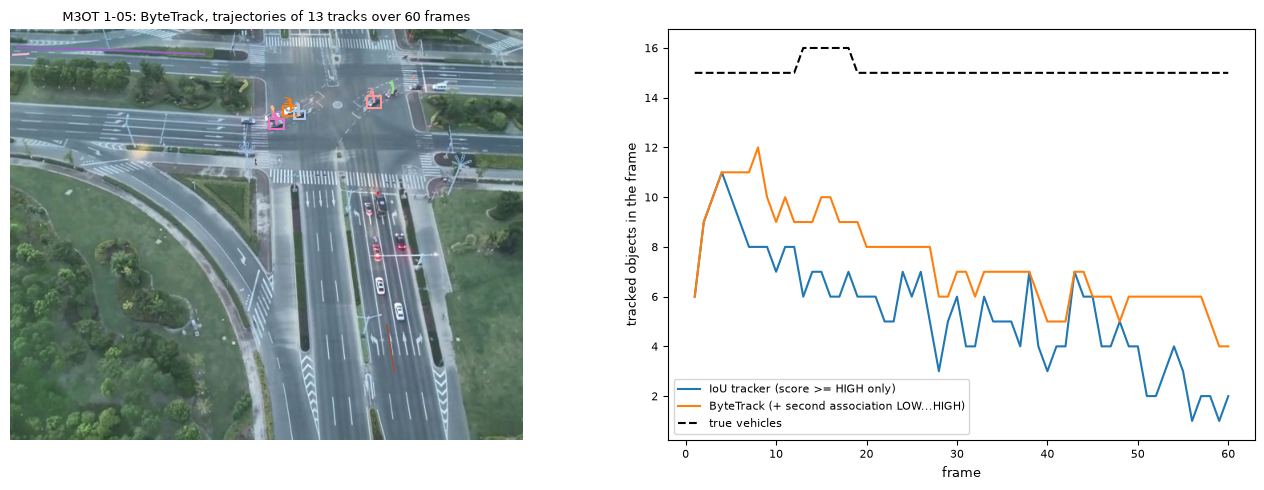

In [10]:
#@title 5.2.3 Tracking of vehicles in a UAV video: IoU tracker and ByteTrack { display-mode: "form" }
SEQUENCE = "1-05" #@param ["1-05", "1-07", "1-08"]
N_FRAMES = 60 #@param {type:"slider", min:20, max:200, step:10}
DETECTOR = "yolo11s.pt" #@param ["yolo11n.pt", "yolo11s.pt"]
IMG_SIZE = 1920 #@param [640, 1280, 1920] {type:"raw"}
HIGH = 0.3 #@param {type:"slider", min:0.2, max:0.8, step:0.05}
LOW = 0.1 #@param {type:"slider", min:0.05, max:0.4, step:0.05}
MAX_LOST = 30 #@param {type:"slider", min:1, max:60, step:1}

VEHICLES = [2, 3, 5, 7]  # COCO: car, motorcycle, bus, truck
det_model = load_yolo(DETECTOR)
FR_T = m3.frames(SEQUENCE, start=0, count=N_FRAMES)
gt_tab = m3.tracks(SEQUENCE)
key = (SEQUENCE, N_FRAMES, DETECTOR, IMG_SIZE)
if globals().get("DET_KEY") != key:
    DETS, t0 = [], time.time()
    for img in FR_T:
        b, s, c, sp = aitbc.yolo_predict(det_model, img, imgsz=IMG_SIZE, conf=0.05, classes=VEHICLES)
        DETS.append((b, s))
    DET_MS = 1000 * (time.time() - t0) / N_FRAMES
    DET_KEY = key
GT_T = {f + 1: [(int(r.id), [r.x, r.y, r.x + r.w, r.y + r.h]) for r in gt_tab[gt_tab.frame == f + 1].itertuples()]
        for f in range(N_FRAMES)}
TRACKS = {}
rows = []
aitbc.ByteTracker().update(*DETS[0])   # warm-up: the first call loads the Hungarian method of SciPy
for name, use_low in (("IoU tracker (score >= HIGH only)", False), ("ByteTrack (+ second association LOW...HIGH)", True)):
    trk = aitbc.ByteTracker(high=HIGH, low=LOW, new_track=min(HIGH + 0.1, 0.9), max_lost=MAX_LOST, use_low=use_low)
    t0 = time.time()
    hyp = {f + 1: [(i, b) for i, b, s in trk.update(*DETS[f])] for f in range(N_FRAMES)}
    ms = 1000 * (time.time() - t0) / N_FRAMES
    m = aitbc.mot_metrics(GT_T, hyp, 0.5)
    TRACKS[name] = hyp
    rows.append({"tracker": name, "MOTA": round(m["MOTA"], 3), "IDF1": round(m["IDF1"], 3), "ID switches": m["IDSW"],
                 "FP": m["FP"], "FN": m["FN"], "true boxes": m["GT"], "true vehicles": m["gt_ids"],
                 "track IDs": m["hyp_ids"], "time of the tracker, ms/frame": round(ms, 2)})
TAB_523 = pd.DataFrame(rows).set_index("tracker")
ev = aitbc.evaluate_detections(DETS, [[b for _, b in GT_T[f + 1]] for f in range(N_FRAMES)], conf=HIGH)
print(f"Detector {DETECTOR}, input {IMG_SIZE}: {DET_MS:.0f} ms per frame ({DEVICE}); AP50 = {ev['AP50']:.3f}, "
      f"recall at score >= {HIGH}: {ev['recall']:.3f}, precision {ev['precision']:.3f}")
display(TAB_523)
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
last = FR_T[-1].copy()
hyp = TRACKS[list(TRACKS)[1]]
paths_ = collections.defaultdict(list)
for f in range(1, N_FRAMES + 1):
    for i, b in hyp[f]:
        paths_[i].append(((b[0] + b[2]) / 2, (b[1] + b[3]) / 2))
ax[0].imshow(last)
cmap = plt.cm.tab20
for i, pts in paths_.items():
    pts = np.array(pts)
    ax[0].plot(pts[:, 0], pts[:, 1], "-", color=cmap(i % 20), lw=1.5)
for i, b in hyp[N_FRAMES]:
    ax[0].add_patch(plt.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, ec=cmap(i % 20), lw=1.5))
    ax[0].text(b[0], b[1] - 2, str(i), color=cmap(i % 20), fontsize=7)
ax[0].set_title(f"M3OT {SEQUENCE}: ByteTrack, trajectories of {len(paths_)} tracks over {N_FRAMES} frames", fontsize=9)
ax[0].axis("off")
for name, hyp_ in TRACKS.items():
    ax[1].plot(np.arange(1, N_FRAMES + 1), [len(hyp_[f]) for f in range(1, N_FRAMES + 1)], label=name)
ax[1].plot(np.arange(1, N_FRAMES + 1), [len(GT_T[f]) for f in range(1, N_FRAMES + 1)], "k--", label="true vehicles")
ax[1].set_xlabel("frame"); ax[1].set_ylabel("tracked objects in the frame"); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "NB08_523_tracking.png"), dpi=110)
plt.show()
RESULT_52["tracking"] = {"sequence": SEQUENCE, "frames": N_FRAMES, "detector": DETECTOR, "img_size": IMG_SIZE,
                         "high": HIGH, "low": LOW, "table": TAB_523.reset_index().to_dict("records")}

## Block 5.2.4. Video-analysis pipeline and the requirements of real time

**Pipeline.** For every frame: decoding of the video → preparation of the input (letterbox, normalisation) → inference of the network → post-processing (decoding of the boxes, NMS) → tracking → drawing → recording or transmission. The pipeline works in **real time** if the time per frame does not exceed the period of the frames:
$$t_{\text{frame}} = \sum_k t_k \leq \frac{1}{f_{\text{video}}}, \qquad f_{\max} = \frac{1}{t_{\text{frame}}}.$$
The longest stage is the inference; it grows with the size of the input and of the model.

**Detection on every $k$-th frame.** When the budget is short, the detector is run only on every $k$-th frame; between the detections the boxes are predicted by the Kalman filters of the tracks. The time of detection per frame falls $k$ times; the error grows with the motion of the objects between the detections.

**Parameters.** `TARGET_FPS` — required frame rate; `DETECT_EVERY` — $k$ for the saved video; `SAVE_VIDEO` — write the video with the tracks into `outputs/video`. The sequence, the detector and the detections are those of block 5.2.3.

**Expected result.** The table of the time of the stages and of the maximum frame rate for the models YOLO11n and YOLO11s at three sizes of the input; the table MOTA and IDF1 against $k$; the saved video.

**What to observe.** On the processor of the test computer the inference is the dominant stage: YOLO11n at 640 needs about 50 ms per frame (about 20 frames per second), YOLO11s at 1920 about 0.87 s (about 1 frame per second); decoding, preparation and NMS take a few milliseconds. When the detector runs only on every 2nd, 3rd or 5th frame, MOTA (0.44) and IDF1 (0.62) do not fall in this sequence: the vehicles at the crossroads move by a few pixels per frame and the Kalman filter predicts them well. With fast targets (an FPV drone, a vehicle close to the camera) the same $k$ would lose the tracks.

**Control question 9.** The onboard computer gives 12 frames per second for the detector at the input 1280. Which settings of the pipeline give 25 frames per second, and what is lost?

decoding, ms  preparation, ms  inference, ms  \
model   input                                                 
yolo11n 640             1.2              0.9           44.8   
        1280            1.2              8.9          153.9   
        1920            1.2             18.4          355.3   
yolo11s 640             1.2              0.8           94.0   
        1280            1.2              8.2          335.1   
        1920            1.2             18.6          844.5   

               post-processing (NMS), ms  total, ms  max frame rate  \
model   input                                                         
yolo11n 640                          1.1       47.9            20.9   
        1280                         1.5      165.5             6.0   
        1920                         2.2      377.1             2.7   
yolo11s 640                          1.1       97.0            10.3   
        1280                         1.8      346.3             2.9   
        1920                         2.4      866.6             1.2   

              real time at 10 fps  
model   input                      
yolo11n 640                   yes  
        1280                   no  
        1920                   no  
yolo11s 640                   yes  
        1280                   no  
        1920                   no

,MOTA,IDF1,ID switches,"detector, ms per frame (average)","tracker, ms per frame"
detection on every k-th frame,,,,,
1,0.439,0.615,1,848.6,0.95
2,0.439,0.619,0,424.3,0.61
3,0.439,0.621,1,282.9,0.54
5,0.443,0.621,0,169.7,0.31


Video: /content/AITBC/AITBC_project/outputs/video/NB08_tracking_1-05_k2.mp4 (0.9 MB, {'path': '/content/AITBC/AITBC_project/outputs/video/NB08_tracking_1-05_k2.mp4', 'opened': True, 'fps': 10.0, 'frames': 60, 'width': 640, 'height': 512, 'codec': 'FMP4', 'duration_s': 6.0, 'size_mb': 0.933976}); drawing and writing 0.8 ms per frame


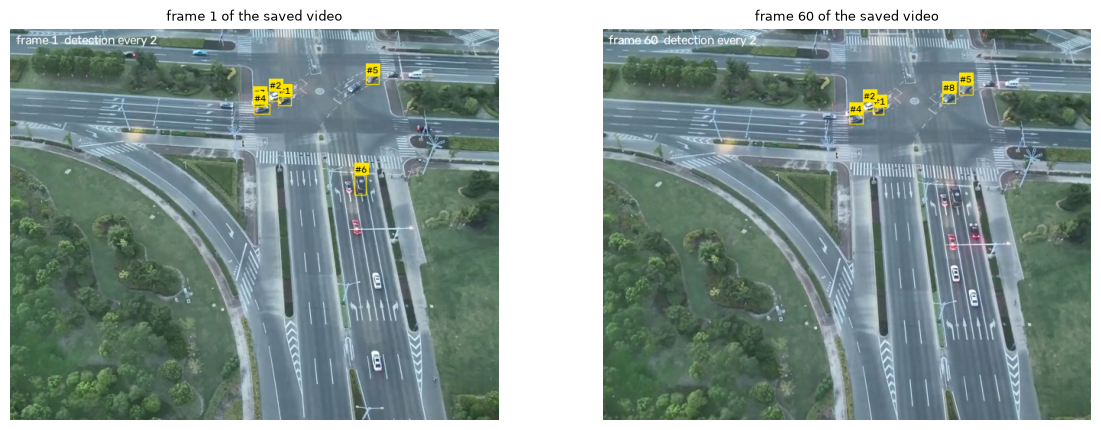

project.json updated: lesson 5.2, keys: lesson_5_2


In [11]:
#@title 5.2.4 Time of the stages, detection on every k-th frame and the saved video { display-mode: "form" }
TARGET_FPS = 10 #@param [10, 25, 30] {type:"raw"}
DETECT_EVERY = 2 #@param [1, 2, 3, 5] {type:"raw"}
SAVE_VIDEO = True #@param {type:"boolean"}

img = FR_T[0]
jpg = cv2.imencode(".jpg", img[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, 90])[1]
t_dec = aitbc.time_call(lambda: cv2.imdecode(jpg, cv2.IMREAD_COLOR), repeats=10)
rows = []
for name in ("yolo11n.pt", "yolo11s.pt"):
    mdl = load_yolo(name)
    for imgsz in (640, 1280, 1920):
        sp = []
        for k in range(4):
            sp.append(aitbc.yolo_predict(mdl, FR_T[k], imgsz=imgsz, conf=0.05, classes=VEHICLES)[3])
        sp = pd.DataFrame(sp[1:]).median()
        tot = t_dec + sp["preprocess"] + sp["inference"] + sp["postprocess"]
        rows.append({"model": name.replace(".pt", ""), "input": imgsz, "decoding, ms": round(t_dec, 1),
                     "preparation, ms": round(sp["preprocess"], 1), "inference, ms": round(sp["inference"], 1),
                     "post-processing (NMS), ms": round(sp["postprocess"], 1), "total, ms": round(tot, 1),
                     "max frame rate": round(1000 / tot, 1), f"real time at {TARGET_FPS} fps": "yes" if tot <= 1000 / TARGET_FPS else "no"})
TAB_524 = pd.DataFrame(rows).set_index(["model", "input"])
display(TAB_524)

rows = []
for k in (1, 2, 3, 5):
    trk = aitbc.ByteTracker(high=HIGH, low=LOW, new_track=min(HIGH + 0.1, 0.9), max_lost=MAX_LOST)
    hyp, t_trk = {}, 0.0
    for f in range(N_FRAMES):
        t0 = time.time()
        out = trk.update(*DETS[f]) if f % k == 0 else trk.coast()
        t_trk += time.time() - t0
        hyp[f + 1] = [(i, b) for i, b, s in out]
    m = aitbc.mot_metrics(GT_T, hyp, 0.5)
    rows.append({"detection on every k-th frame": k, "MOTA": round(m["MOTA"], 3), "IDF1": round(m["IDF1"], 3),
                 "ID switches": m["IDSW"], "detector, ms per frame (average)": round(DET_MS / k, 1),
                 "tracker, ms per frame": round(1000 * t_trk / N_FRAMES, 2)})
    if k == DETECT_EVERY:
        HYP_K = hyp
TAB_524K = pd.DataFrame(rows).set_index("detection on every k-th frame")
display(TAB_524K)

if SAVE_VIDEO:
    t0 = time.time()
    out_frames = []
    for f in range(N_FRAMES):
        objs = [{"box": b, "cls": "vehicle"} for i, b in HYP_K[f + 1]]
        ids = [i for i, b in HYP_K[f + 1]]
        im = aitbc.draw_boxes(FR_T[f], objs, labels=False, ids=ids, thickness=1, color=(255, 230, 0))
        cv2.putText(im, f"frame {f + 1}  detection every {DETECT_EVERY}", (8, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    (255, 255, 255), 1, cv2.LINE_AA)
        out_frames.append(im)
    t_draw = 1000 * (time.time() - t0) / N_FRAMES
    vpath = aitbc.write_video(os.path.join(VIDEO_DIR, f"NB08_tracking_{SEQUENCE}_k{DETECT_EVERY}.mp4"), out_frames, fps=10)
    info = aitbc.video_info(vpath)
    print(f"Video: {vpath} ({os.path.getsize(vpath) / 1e6:.1f} MB, {info}); drawing and writing {t_draw:.1f} ms per frame")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
    for a, f in zip(ax, (0, N_FRAMES - 1)):
        a.imshow(out_frames[f]); a.set_title(f"frame {f + 1} of the saved video", fontsize=9); a.axis("off")
    plt.tight_layout()
    plt.show()
RESULT_52["real_time"] = {"stages": TAB_524.reset_index().to_dict("records"),
                          "detect_every": TAB_524K.reset_index().to_dict("records")}
update_project_json("5.2", {"lesson_5_2": RESULT_52})

### Self-check of Lesson 5.2

1. How are the 64 classes of the terrain joined into the groups of traversability, and why is the sky not evaluated?
2. What is trained in the transfer learning of LR-ASPP, and why are the test frames taken from other sessions?
3. Describe the steps of a tracker by detection and the second association of ByteTrack.
4. What do MOTA and IDF1 measure, and which of them reacts to the identity switches more strongly?
5. How is the maximum frame rate of a pipeline found, and what does the detection on every $k$-th frame give?

## Data sources and licences

The course library reads the files directly from the repositories of the data sets; the data are not redistributed with the notebook. When images or results are published, the data sets are cited.

1. **DUT Anti-UAV.** Zhao J., Zhang J., Li D., Wang D. Vision-based Anti-UAV Detection and Tracking. *IEEE Transactions on Intelligent Transportation Systems* (2022); arXiv:2205.10851 · Data: https://github.com/wangdongdut/DUT-Anti-UAV, copy https://huggingface.co/datasets/aegean-ai/dut-anti-uav · Licence Apache-2.0.
2. **M3OT.** Nie Z. et al. *Scientific Data* 12, 1927 (2025) · Licence CC BY 4.0.
3. **GOOSE.** Mortimer P. et al. The GOOSE Dataset for Perception in Unstructured Environments. *IEEE ICRA 2024*, 14838–14844 · https://goose-dataset.de · Licence CC BY-SA 4.0.
4. **YOLO11.** Jocher G., Qiu J. Ultralytics YOLO11 (2024), https://github.com/ultralytics/ultralytics · Licence AGPL-3.0 (installed in the session, not redistributed). **COCO.** Lin T.-Y. et al. Microsoft COCO: Common Objects in Context. *ECCV 2014*.
5. **LR-ASPP, MobileNetV3.** Howard A. et al. Searching for MobileNetV3. *ICCV 2019*, 1314–1324; weights of torchvision (BSD-3-Clause).
6. **ByteTrack.** Zhang Y. et al. ByteTrack: Multi-Object Tracking by Associating Every Detection Box. *ECCV 2022*. **CLEAR-MOT.** Bernardin K., Stiefelhagen R. *EURASIP J. Image and Video Processing* (2008). **IDF1.** Ristani E. et al. *ECCV Workshops 2016*. **Slicing (SAHI).** Akyon F. C. et al. *IEEE ICIP 2022*.

**Next notebook.** Notebook 09 — Topic 5, Lesson 5.3 (practical class): YOLO11 on a single frame, on a series of UAV frames, on FPV frames and on a thermal frame, and the saved video; Lesson 5.4 (practical class, mini-project): training of a counter-UAV detector on DUT Anti-UAV, its evaluation, tracking of a drone and export to ONNX.